    # Calibration / sanity check

**Goal of the notebook:** to characterise how the criteria behave on trained neural networks, to check their basic soundness and task selectivity, and to determine a stable configuration of hyperparameters for the subsequent experiments.

---

## What is analysed for each set of hyperparameters

**A. Detector validity** — the score of one ideal planted neuron.

**Task:** show that the detector is in principle able to detect target geometry that is known to exist, and thereby confirm the basic soundness of the implementation.

**B. False-positive behaviour** — the distribution of scores on 4–5 null-features fixed in advance.

**Task:** show how the detector behaves on objects known to be negative, and establish an empirical baseline of false positives.

**C. Task irrelevance** — the score distributions on the task-irrelevant circle and on the null-features of dataset A.

**Task:** show that the presence of a geometric feature that the task does not require does not lead to systematic detection compared with the null baseline.

**D. Task relevance** — the score distributions on the task-relevant circle and on the null-features of dataset B.

**Task:** show that the detector is able to detect geometry that is genuinely necessary for solving the task, and that this behaviour differs from the null baseline.

**E. Selectivity** — a direct comparison of the scores on the task-relevant and task-irrelevant circles.

**Task:** show that the detector responds specifically to task relevance, and not simply to the presence or the geometric shape of a circle.

**F. Numerical stability and frozen methodological specification**

For all of A–E we examine how the corresponding results depend on
[
\theta=(\text{resolution}, n_{\mathrm{levels}}, \varepsilon,\ldots).
]

We look for a region in which, as the numerical hyperparameters change:

* the results stay within a numerical tolerance set in advance;
* the qualitative conclusions of A–E are preserved;
* the interpretation of the detector's behaviour does not change.

**Task:** show that the properties of the detector are not an artefact of a particular choice of numerical hyperparameters, and on that basis freeze a working configuration for all subsequent experiments.

---

## Plan of the first experiment

**We choose two datasets**, as stated above:

* A: `simple_irrelevant` — the circle is task-irrelevant;
* B: `simple_relevant` — the circle is task-relevant.

**We train 50 neural networks** on each dataset.

**The main part of the notebook is a sweep over the hyperparameters of the criteria.** For each set of hyperparameters we compute:

* the criterion on **every neuron of every model**;
* the criterion **once on the ideal planted neuron**;
* for dataset A — on **4–5 pre-fixed** `null_features` and on the task-irrelevant feature;
* for dataset B — on the same `null_features` and on the task-relevant feature.

For each set of hyperparameters we obtain:

* one value on the ideal planted neuron;
* the distribution of scores on the null-features;
* the distribution of scores on the task-irrelevant feature;
* the distribution of scores on the task-relevant feature.

We then analyse:

* **Detector validity** — whether the criterion can detect the ideal planted witness;
* **False-positive behaviour** — what the baseline on the null-features is;
* **Task irrelevance** — whether systematic detection of the task-irrelevant feature is absent;
* **Task relevance** — whether the task-relevant feature is detected;
* **Selectivity** — whether task-relevant and task-irrelevant features are distinguished;
* **Numerical stability and frozen methodological specification** — whether the results settle into a stable regime as the hyperparameters change, and whether a working configuration can be frozen on that basis.

**Outcome of the notebook:**

* obtain a set of methodological recommendations on the choice of hyperparameters, to be frozen and used in the following experiments;
* confirm the basic soundness of the criteria;
* **show that the criteria distinguish task-relevant from task-irrelevant features, rather than simply responding to the presence of the corresponding geometry.**

**This is the main scientific task of this notebook.**


In [1]:
# Repository root as CWD, src/ on sys.path — the convention of the persistence layer.
import os, sys
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "repository root not found"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import torch, pandas as pd
pd.set_option("display.width", 200)
print("CWD:", Path.cwd())

from analysis.lab import ExperimentLab
from analysis.null_placement import at, shift, preview
from analysis.stat_aggregation import bounds_from_X
from analysis.null_placement import random_placements
from models.NN_analysis import TruncatedMLPFunction, ScalarProjection
from analysis.criterions import structural_criterion
from data.dataset_recipes import make_simple_dataset
from management.experiment_management import store_dataset_instance, load_dataset_instance, get_feature_points
import numpy as np, pandas as pd, time
import analysis.calibration as cal
from analysis.null_placement import build_null_features, placement_report
from analysis.stat_aggregation import find_model_paths_for_dataset
from management.experiment_management import load_model_instance, get_feature_points
from experiments.registry import EXPERIMENTS

CWD: /home/serdabel/Desktop/proga/task-relevance-of-topological-features


## 1. Introduce two datasets:

In [2]:
# irrelevant_dataset = make_simple_dataset(relevant=False)
# irrelevant_dataset.plot()

In [3]:
# relevant_dataset = make_simple_dataset(relevant=True)
# relevant_dataset.plot()

In [4]:
# # store_dataset_instance(name="simple_irrelevant", data=irrelevant_dataset)
# # store_dataset_instance(name="simple_relevant", data=relevant_dataset)
# 
# relevant_dataset = load_dataset_instance(
#     "data/dataset_instances/simple_relevant/"
#     "simple_relevant_0/"
# )
# 
# irrelevant_dataset = load_dataset_instance(
#     "data/dataset_instances/simple_irrelevant/"
#     "simple_irrelevant_0/"
# )
# 
# print("Relevant --- X:", tuple(relevant_dataset["X"].shape), "| features:", list(relevant_dataset.get("features", {})))
# print("Irrelevant - X:", tuple(irrelevant_dataset["X"].shape), "| features:", list(irrelevant_dataset.get("features", {})))

## 2. Train 50 models on each dataset to 100% accuracy:

done with the ensemble-training code (`src/training/mass_training.py`); the trained models are stored in `models/runs/`

## 3. Fix bounding box and null-features

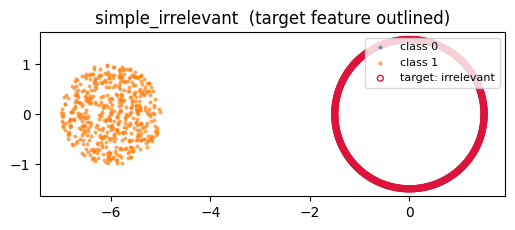

{'experiment': 'exp1_sanity_check',
 'dataset': 'simple_irrelevant',
 'arch': 'tanh_w5_d5',
 'n_models': 1,
 'n_epochs': 300,
 'target_acc': 1.0,
 'lr': 0.001,
 'batch_size': 64,
 'optimizer': 'adam',
 'weight_decay': 0.0,
 'resolution': 200,
 'target_feature': 'irrelevant',
 'primary_witness_column': 'is_structural_witness'}

In [5]:
lab_irrel = ExperimentLab("exp1_sanity_check", dataset="simple_irrelevant")
lab_irrel.show_dataset()
lab_irrel.config()

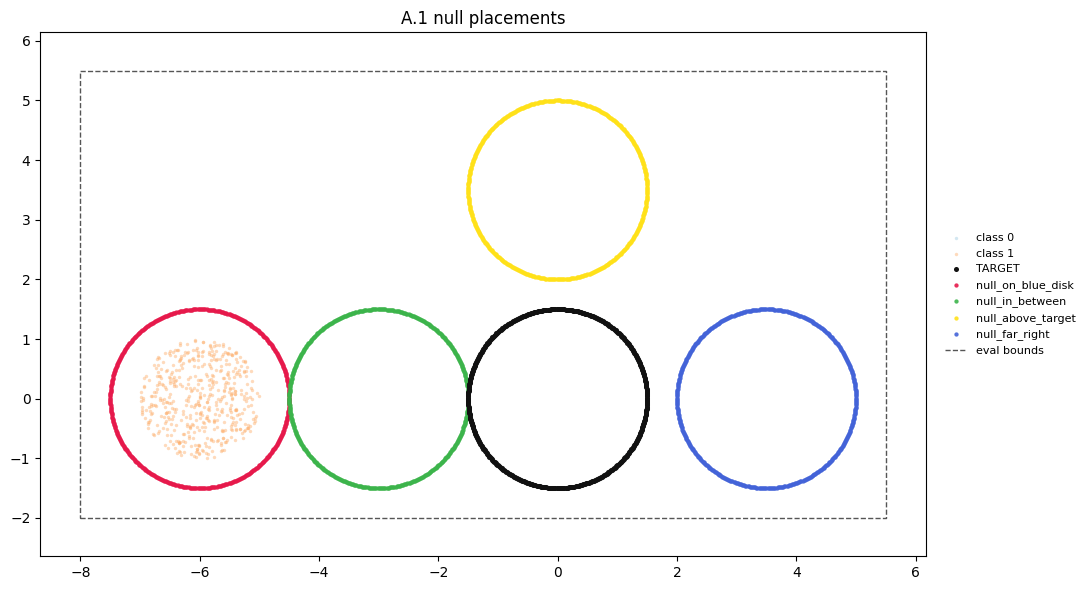

In [6]:
placements = [
    at( -6.0,  0.0, name="on_blue_disk"),   # right on the data of the opposite class
    at( -3.0,  0.0, name="in_between"),       # in the empty corridor, on the decision boundary
    at( 0.0,  3.5, name="above_target"),   # next to the target, same regime
    at( 3.5, 0.0, name="far_right")
]

report = lab_irrel.set_null_placements(placements)

_ = preview(lab_irrel.dataset()["X"], lab_irrel.dataset()["y"],
            lab_irrel.feature_points(),      # target
            lab_irrel.null_features,         # controls
            bounds=lab_irrel.bounds())       # dashed line — the region on which the field is computed

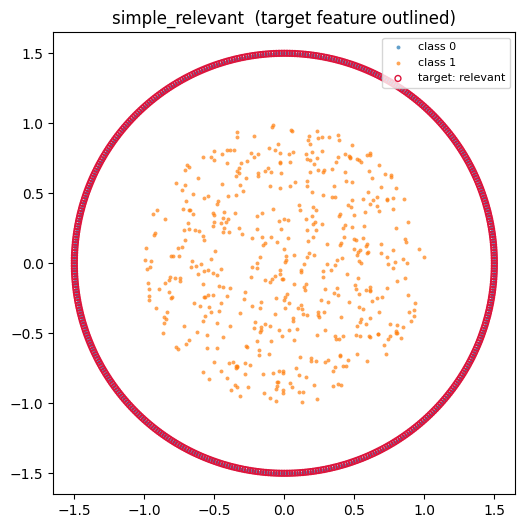

{'experiment': 'exp1_sanity_check',
 'dataset': 'simple_relevant',
 'arch': 'tanh_w5_d5',
 'n_models': 1,
 'n_epochs': 300,
 'target_acc': 1.0,
 'lr': 0.001,
 'batch_size': 64,
 'optimizer': 'adam',
 'weight_decay': 0.0,
 'resolution': 200,
 'target_feature': 'relevant',
 'primary_witness_column': 'is_structural_witness'}

In [7]:
lab_rel = ExperimentLab("exp1_sanity_check", dataset="simple_relevant")
lab_rel.show_dataset()
lab_rel.config()

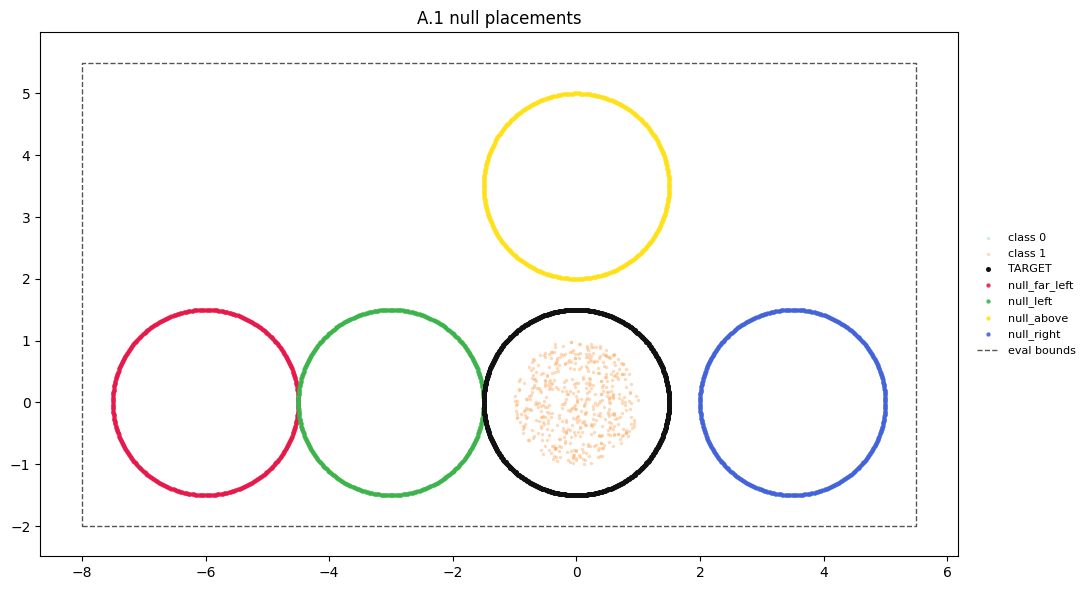

In [8]:
placements = [
    at( -6.0,  0.0, name="far_left"),
    at( -3.0,  0.0, name="left"),
    at( 0.0,  3.5, name="above"),
    at( 3.5, 0.0, name="right")
]

report_rel = lab_rel.set_null_placements(placements)

_ = preview(lab_rel.dataset()["X"], lab_irrel.dataset()["y"],
            lab_rel.feature_points(),      # target
            lab_rel.null_features,         # controls
            bounds=lab_rel.bounds())       # dashed line — the region on which the field is computed

----
## 1. Resolution sweep

Sweep the values of `resolution` with `n_levels` and `level_eps` fixed.

For each value compute:
- the score of the ideal planted neuron;
- the scores of all neurons on the `null_features`;
- the scores of all neurons on the task-irrelevant feature of dataset A;
- the scores of all neurons on the task-relevant feature of dataset B.

Check whether the behaviour of the criteria reaches a plateau and whether the main qualitative conclusions are preserved.

---

In [9]:
lab_irrel.bounds(), lab_rel.bounds()

([(-8.0, 5.5), (-2.0, 5.5)], [(-8.0, 5.5), (-2.0, 5.5)])

In [10]:
# ── 0. Fix everything except resolution ───────────────────────────────────────
SPEC = EXPERIMENTS["exp1_sanity_check"]

# ONE box for both datasets — otherwise the grid step, and with it the floor of
# the scale, differ, and analysis E (selectivity) measures discretisation on a
# par with task relevance.
BOUNDS = [(-8.0, 5.5), (-2.0, 5.5)]        # ← your numbers after choosing the null features

RESOLUTIONS   = [25, 50, 100, 200, 400]
REFERENCE_RES = 200
ARCH_TAG      = "tanh_w5_d5_mass-train"
N_SWEEP_MODELS = 50        # ← the main cost knob, see the estimate below
LAYER_IDS      = None     # None = all layers

# Only structural + homological: anchored is deliberately excluded.
CRITS = {k: v for k, v in cal.criteria(SPEC.eval).items()
         if k in ("structural", "homological")}

# The threshold of the structural criterion is read from the spec, not typed in by hand.
TAU = SPEC.eval.structural_kwargs["threshold"]

In [11]:
# ── 1. Features: target + nulls. The circle is bitwise the same in both datasets,
#      so the same placements give literally identical nulls. ──────────────────
# The list of nulls is written out here explicitly rather than inherited from the
# cells above: there the variable `placements` is assigned twice (same layout,
# different names), and PLACEMENTS would receive whichever ran last. The sweep
# configuration must not depend on the order in which the exploratory cells were
# run — these are exactly the names under which sanity_resolution_sweep.csv was
# computed.
PLACEMENTS = [
    at(-6.0, 0.0, name="on_blue_disk"),   # right on the data of the opposite class
    at(-3.0, 0.0, name="in_between"),     # empty corridor, decision boundary
    at( 0.0, 3.5, name="above_target"),   # next to the target, same regime
    at( 3.5, 0.0, name="far_right"),      # far to the right
]

DATASETS = {
    "irrelevant": ("simple_irrelevant", "irrelevant"),
    "relevant":   ("simple_relevant",   "relevant"),
}

FEATURES, PATHS, DATA = {}, {}, {}
for tag, (ds_name, target) in DATASETS.items():
    d = load_dataset_instance(f"data/dataset_instances/{ds_name}/{ds_name}_0/",
                              reconstruct_data=False)
    DATA[tag] = d
    A = get_feature_points(d, target)
    FEATURES[tag] = {target: A, **build_null_features(A, PLACEMENTS)}
    PATHS[tag] = find_model_paths_for_dataset(ds_name, model_name=ARCH_TAG)
    print(f"{tag:11s}: {len(PATHS[tag]):3d} models | features: {list(FEATURES[tag])}")
    display(placement_report(A, {k: v for k, v in FEATURES[tag].items() if k != target},
                             X=d["X"], y=d["y"], bounds=BOUNDS))

irrelevant : 100 models | features: ['irrelevant', 'null_on_blue_disk', 'null_in_between', 'null_above_target', 'null_far_right']


,feature,centre,diam,separation,min_pair_sep,dist_to_data,nearest_class,in_bounds
0,TARGET,"(0.0, 0.0)",3.0,0.0000,NaN,0.0000,0,1.0
1,null_on_blue_disk,"(-6.0, 0.0)",3.0,1.5314,0.5636,0.5215,1,1.0
2,null_in_between,"(-3.0, 0.0)",3.0,0.5636,0.5636,1.0207,0,1.0
3,null_above_target,"(0.0, 3.5)",3.0,0.7209,1.0775,2.1627,0,1.0
4,null_far_right,"(3.5, 0.0)",3.0,0.7209,1.1880,2.1627,0,1.0


relevant   :  50 models | features: ['relevant', 'null_on_blue_disk', 'null_in_between', 'null_above_target', 'null_far_right']


,feature,centre,diam,separation,min_pair_sep,dist_to_data,nearest_class,in_bounds
0,TARGET,"(0.0, 0.0)",3.0,0.0000,NaN,0.0000,0,1.0
1,null_on_blue_disk,"(-6.0, 0.0)",3.0,1.5314,0.5636,4.5941,0,1.0
2,null_in_between,"(-3.0, 0.0)",3.0,0.5636,0.5636,1.6907,0,1.0
3,null_above_target,"(0.0, 3.5)",3.0,0.7209,1.0775,2.1627,0,1.0
4,null_far_right,"(3.5, 0.0)",3.0,0.7209,1.1880,2.1627,0,1.0


In [12]:
# ── 2. Cost estimate BEFORE the run: time of one evaluation × number of evaluations
probe_model, _ = load_model_instance(PATHS["relevant"][0])
n_neurons = sum(probe_model.blocks[l].linear.out_features
                for l in range(probe_model.n_layers))

t = time.perf_counter()
cal.measure(cal.trained_probe(probe_model, 0, 0, FEATURES["relevant"]["relevant"]),
            CRITS["structural"], BOUNDS, REFERENCE_RES)
per_eval = time.perf_counter() - t

n_evals = (len(RESOLUTIONS) * len(DATASETS) * N_SWEEP_MODELS
           * len(FEATURES["relevant"]) * n_neurons * len(CRITS))
print(f"neurons per model  : {n_neurons}")
print(f"one evaluation     : {per_eval:.2f} s (res={REFERENCE_RES})")
print(f"total evaluations  : {n_evals}")
print(f"rough estimate     : {n_evals * per_eval / 60:.0f} min "
      f"(grows ~R², so the top resolutions cost more than the average)")

neurons per model  : 25
one evaluation     : 0.30 s (res=200)
total evaluations  : 125000
rough estimate     : 635 min (grows ~R², so the top resolutions cost more than the average)


In [13]:
# ── 3. A: planted neuron — sweep over resolution (seconds) ────────────────────
#     The answer is known BEFORE the measurement: this neuron is a witness. Its
#     score at each R serves as the reference point for all the other
#     distributions, so it too is written to disk, next to the ensemble.
PLANTED_CSV = Path("analysis/results/calibration/sanity_resolution_planted.csv")

A_rel = FEATURES["relevant"]["relevant"]
planted = cal.planted_probe(probe_model, A_rel, layer_id=3, coord_id=0, name="planted")

if PLANTED_CSV.exists():
    df_A = cal.read_scores_csv(PLANTED_CSV)
    print(f"reusing {PLANTED_CSV}")
else:
    df_A = cal.scan([planted], CRITS, BOUNDS, REFERENCE_RES,
                    grid={"resolution": RESOLUTIONS}, verbose=True)
    PLANTED_CSV.parent.mkdir(parents=True, exist_ok=True)
    df_A.to_csv(PLANTED_CSV, index=False)

display(df_A.pivot_table(index="resolution", columns="criterion",
                         values=["score", "is_witness"]))

reusing analysis/results/calibration/sanity_resolution_planted.csv


is_witness                  score           
criterion  homological structural homological structural
resolution                                              
25                 1.0        0.0    0.347375   0.127846
50                 1.0        1.0    0.401333   0.094597
100                1.0        1.0    0.410869   0.074123
200                1.0        1.0    0.412388   0.034313
400                1.0        1.0    0.411859   0.020726

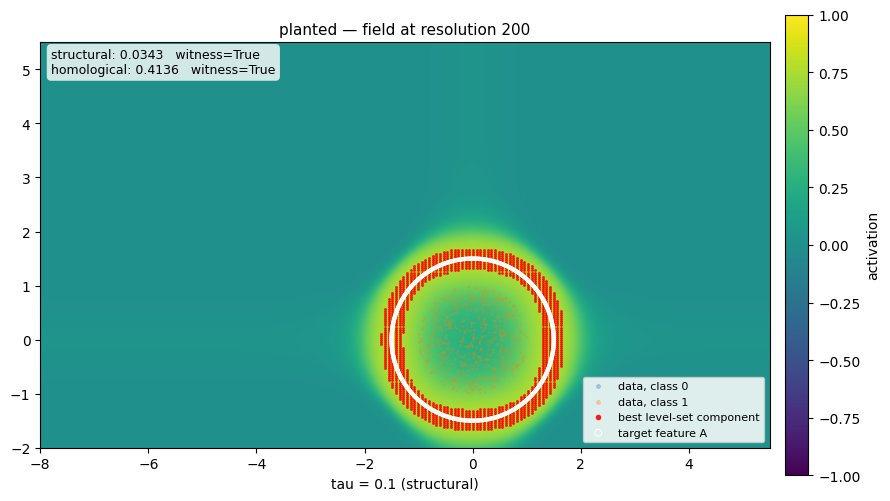

In [14]:
# ── 3b. What the planted neuron looks like ───────────────────────────────────
#     Its verdict is known BEFORE the measurement, so the picture answers not
#     "is it a witness" but "what exactly does the criterion see": where the
#     ridge runs, which component of the level band the criterion picks, and
#     how it lies on A.
#     Red is the chosen component. It is a RING of finite thickness, not a
#     curve: this is the eps-thickening, and the Chamfer distance from it to the
#     white circle is exactly the instrument's overhead (the true geometry of
#     the ridge is 0.0016).
#     The field is saturated nowhere (it reaches ~0.76, not 1) — that is how
#     plant_radial_neuron is built, and the modest homological margin comes
#     from the same place.
from visualization.calibration_plots import plot_probe_field

_ = plot_probe_field(planted, BOUNDS, REFERENCE_RES, criteria_specs=CRITS,
                     threshold=TAU,
                     X=DATA["relevant"]["X"], y=DATA["relevant"]["y"])

In [15]:
# ── 4. B/C/D: ensemble × features × neurons, for each resolution ──────────────
#     Each triple (R, dataset, criterion) is saved RIGHT AFTER it is computed:
#     the full run takes hours, and a kernel crash at the last step must not
#     cost all the previous ones. Parts already computed are reused, so the
#     cell can be re-run as many times as you like — only what is not there
#     yet gets computed. To recompute a part, delete its file.
PARTS = Path("analysis/results/calibration/sweep_parts")
PARTS.mkdir(parents=True, exist_ok=True)
SWEEP_CSV = Path("analysis/results/calibration/sanity_resolution_sweep.csv")

frames = []
for res in RESOLUTIONS:
    for tag, (ds_name, target) in DATASETS.items():
        for cname, crit in CRITS.items():
            part = PARTS / f"res{res}_{tag}_{cname}.csv"
            if part.exists():
                # read_scores_csv, not read_csv: pandas reads a bare "null" in
                # the role column as NaN and silently loses exactly the rows
                # that make up the floor.
                df = cal.read_scores_csv(part)
                print(f"res={res:4d} {tag:11s} {cname:12s} {len(df):5d} rows ← {part.name}")
            else:
                t0 = time.perf_counter()
                df = cal.ensemble_scores(
                    PATHS[tag][:N_SWEEP_MODELS], FEATURES[tag], BOUNDS, res,
                    crit, target_name=target, layer_ids=LAYER_IDS, verbose=False)
                df.to_csv(part, index=False)
                print(f"res={res:4d} {tag:11s} {cname:12s} {len(df):5d} rows in "
                      f"{time.perf_counter() - t0:.0f} s → {part.name}")
            df["resolution"], df["dataset"], df["criterion"] = res, tag, cname
            frames.append(df)

ens = pd.concat(frames, ignore_index=True)
ens.to_csv(SWEEP_CSV, index=False)
print(f"\ntotal {len(ens)} rows → {SWEEP_CSV}")

res=  25 irrelevant  structural    6250 rows ← res25_irrelevant_structural.csv
res=  25 irrelevant  homological   6250 rows ← res25_irrelevant_homological.csv
res=  25 relevant    structural    6250 rows ← res25_relevant_structural.csv
res=  25 relevant    homological   6250 rows ← res25_relevant_homological.csv
res=  50 irrelevant  structural    6250 rows ← res50_irrelevant_structural.csv
res=  50 irrelevant  homological   6250 rows ← res50_irrelevant_homological.csv
res=  50 relevant    structural    6250 rows ← res50_relevant_structural.csv
res=  50 relevant    homological   6250 rows ← res50_relevant_homological.csv
res= 100 irrelevant  structural    6250 rows ← res100_irrelevant_structural.csv
res= 100 irrelevant  homological   6250 rows ← res100_irrelevant_homological.csv
res= 100 relevant    structural    6250 rows ← res100_relevant_structural.csv
res= 100 relevant    homological   6250 rows ← res100_relevant_homological.csv
res= 200 irrelevant  structural    6250 rows ← res200_

In [16]:
# ── 5. Summary: the unit of observation is the best neuron of a (model, feature) pair
#     Not the fraction of witnesses: it inherits a multiplicity that grows with
#     the network's width by construction. And not "the
#     best of all nulls": the target has one feature, the floor four
#     placements, and a common minimum would give the floor a fourfold
#     multiplicity that the target does not have. The spread BETWEEN placements
#     is the width of the floor, not noise.
summary = cal.sweep_summary(ens)
contrast = pd.concat([
    cal.sweep_contrast(ens[ens.criterion == "structural"], threshold=TAU),
    cal.sweep_contrast(ens[ens.criterion == "homological"]),
], ignore_index=True)

summary.to_csv("analysis/results/calibration/sanity_resolution_summary.csv", index=False)
contrast.to_csv("analysis/results/calibration/sanity_resolution_contrast.csv", index=False)

for cname in CRITS:
    print("=" * 118)
    print(cname)
    display(summary[summary.criterion == cname].round(4))
    display(contrast[contrast.criterion == cname].round(4))

structural


,criterion,resolution,dataset,role,n_neurons,detected_neurons,neuron_median,neuron_q10,neuron_q90,n_units,detected_units,best_median,best_q10,best_q90,best_extreme,lower_is_better
20,structural,25,irrelevant,null,5000,1.0,0.4374,0.2286,0.6253,200,1.0,0.2453,0.1766,0.4325,0.1591,True
21,structural,25,irrelevant,target,1250,1.0,0.5673,0.4475,0.7502,50,1.0,0.4117,0.3027,0.4513,0.1765,True
22,structural,25,relevant,null,5000,1.0,0.4696,0.2271,0.7984,200,1.0,0.2243,0.1726,0.3696,0.1476,True
23,structural,25,relevant,target,1250,1.0,0.2307,0.0826,0.7078,50,1.0,0.0824,0.0702,0.1063,0.0613,True
24,structural,50,irrelevant,null,5000,1.0,0.3836,0.1873,0.5814,200,1.0,0.1971,0.1565,0.4011,0.1205,True
25,structural,50,irrelevant,target,1250,1.0,0.5371,0.4301,0.7044,50,1.0,0.4027,0.2133,0.4362,0.1722,True
26,structural,50,relevant,null,5000,1.0,0.3785,0.1945,0.6984,200,1.0,0.1957,0.1601,0.3241,0.1258,True
27,structural,50,relevant,target,1250,1.0,0.2054,0.0640,0.6451,50,1.0,0.0637,0.0498,0.0773,0.0429,True
28,structural,100,irrelevant,null,5000,1.0,0.3673,0.1910,0.5609,200,1.0,0.2070,0.1583,0.3810,0.0734,True
29,structural,100,irrelevant,target,1250,1.0,0.5224,0.4222,0.6636,50,1.0,0.3965,0.2028,0.4238,0.1614,True


,criterion,resolution,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
0,structural,25,irrelevant,0.4117,0.2453,null_far_right,0.1896,-0.1664,-0.2221,0.2089,0.00,0.000
1,structural,25,relevant,0.0824,0.2243,null_on_blue_disk,0.1954,0.1419,0.1130,0.9835,0.86,0.000
2,structural,50,irrelevant,0.4027,0.1971,null_far_right,0.1714,-0.2056,-0.2313,0.1861,0.00,0.000
3,structural,50,relevant,0.0637,0.1957,null_far_right,0.1702,0.1320,0.1065,0.9938,0.92,0.000
4,structural,100,irrelevant,0.3965,0.2070,null_far_right,0.1699,-0.1895,-0.2266,0.1922,0.00,0.005
5,structural,100,relevant,0.0486,0.1889,null_far_right,0.1660,0.1402,0.1174,0.9990,0.96,0.000
6,structural,200,irrelevant,0.3923,0.2259,null_far_right,0.1764,-0.1664,-0.2158,0.1991,0.00,0.005
7,structural,200,relevant,0.0349,0.1858,null_far_right,0.1650,0.1509,0.1300,0.9995,0.98,0.000
8,structural,400,irrelevant,0.3975,0.2321,null_far_right,0.1768,-0.1654,-0.2207,0.2007,0.00,0.005
9,structural,400,relevant,0.0311,0.1943,null_far_right,0.1729,0.1632,0.1419,0.9995,0.98,0.000


homological


,criterion,resolution,dataset,role,n_neurons,detected_neurons,neuron_median,neuron_q10,neuron_q90,n_units,detected_units,best_median,best_q10,best_q90,best_extreme,lower_is_better
0,homological,25,irrelevant,null,5000,0.0162,-0.0049,-0.0259,-0.0006,200,0.190,-0.0041,-0.0314,-0.0005,0.0178,False
1,homological,25,irrelevant,target,1250,0.0152,-0.0429,-0.0696,-0.0001,50,0.240,-0.0279,-0.0567,0.0027,0.0055,False
2,homological,25,relevant,null,5000,0.1010,-0.0529,-0.1108,-0.0066,200,0.505,-0.0269,-0.0640,-0.0025,0.0106,False
3,homological,25,relevant,target,1250,0.6280,0.7586,-0.0808,1.5828,50,1.000,1.6266,1.3762,1.7180,1.7474,False
4,homological,50,irrelevant,null,5000,0.0312,-0.0189,-0.0939,-0.0013,200,0.300,-0.0125,-0.0775,-0.0010,0.0199,False
5,homological,50,irrelevant,target,1250,0.0360,-0.0514,-0.0827,-0.0087,50,0.560,-0.0316,-0.0774,-0.0051,0.0057,False
6,homological,50,relevant,null,5000,0.1474,-0.0736,-0.1680,-0.0180,200,0.640,-0.0339,-0.0838,-0.0042,0.0133,False
7,homological,50,relevant,target,1250,0.6568,0.7077,-0.1097,1.5882,50,1.000,1.6311,1.4016,1.7200,1.7461,False
8,homological,100,irrelevant,null,5000,0.0396,-0.0108,-0.0515,-0.0015,200,0.380,-0.0093,-0.0522,-0.0014,0.0199,False
9,homological,100,irrelevant,target,1250,0.0416,-0.0564,-0.0890,-0.0138,50,0.600,-0.0402,-0.0822,-0.0022,0.0056,False


,criterion,resolution,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
10,homological,25,irrelevant,-0.0279,-0.0041,null_far_right,-0.0033,-0.0238,-0.0246,0.2873,NaN,NaN
11,homological,25,relevant,1.6266,-0.0269,null_on_blue_disk,-0.0086,1.6534,1.6352,1.0000,NaN,NaN
12,homological,50,irrelevant,-0.0316,-0.0125,null_far_right,-0.0030,-0.0191,-0.0286,0.3238,NaN,NaN
13,homological,50,relevant,1.6311,-0.0339,null_on_blue_disk,-0.0093,1.6651,1.6404,1.0000,NaN,NaN
14,homological,100,irrelevant,-0.0402,-0.0093,null_far_right,-0.0034,-0.0309,-0.0368,0.2535,NaN,NaN
15,homological,100,relevant,1.6261,-0.0349,null_on_blue_disk,-0.0049,1.6610,1.6310,1.0000,NaN,NaN
16,homological,200,irrelevant,-0.0332,-0.0183,null_far_right,-0.0061,-0.0150,-0.0271,0.3871,NaN,NaN
17,homological,200,relevant,1.6273,-0.0416,null_on_blue_disk,-0.0088,1.6689,1.6361,1.0000,NaN,NaN
18,homological,400,irrelevant,-0.0436,-0.0173,null_far_right,-0.0056,-0.0263,-0.0380,0.3322,NaN,NaN
19,homological,400,relevant,1.6431,-0.0333,null_on_blue_disk,-0.0076,1.6765,1.6507,1.0000,NaN,NaN


---
### How to read the histograms: what a "unit" is and over what the median is taken

**Two different objects** are drawn on the same axis, and they must not be confused.

**The bars are all neurons.** Every neuron of every model, scored against every feature:
1250 values for the target (50 models × 25 neurons) and 5000 for the nulls (the same 50 models × 25
neurons × 4 placements). This is the descriptive picture: what the criterion returns at all.

**The thick vertical line is the statistic that is allowed to deliver a verdict.** It is built in
two steps.

#### Step 1: within a *(model, feature)* pair, take the BEST neuron

Not the mean over neurons and not the fraction of witness neurons. Three reasons.

* **The hypothesis is existential.** The claim reads "the network *has* a neuron that witnesses
  the feature", not "a typical neuron witnesses it". The right statistic for "there exists" is an
  extremum, not a mean.
* **Multiplicity.** If one counts the fraction of witness neurons, the probability that *at least one*
  neuron crosses the threshold by chance grows with the number of neurons by construction: with a
  threshold that errs in 5% of cases, 35 neurons give a 0.83 chance of a false positive, and 63 neurons
  0.96. So the "fraction of witnesses" is a quantity that depends on the width of
  the network mechanically. And the dependence on width is the subject of a separate experiment (exp2);
  building it into the statistic would spoil that experiment in advance. Taking the best neuron collapses
  25 comparisons into one and **removes** the multiplicity rather than correcting for it.
* **Neurons within a model are not independent observations.** They share weights, data and seed.
  Averaging them means building a confidence interval for a population that does not exist. That is why
  the bootstrap unit throughout the repository is the model, not the neuron (`CONVENTIONS["bootstrap_unit"]`).

Importantly, **the same is done with the nulls**: for a null, too, the best of the 25 neurons is taken.
Both sides are "the best of 25"; the comparison is fair.

#### Step 1a: why the unit is a *(model, feature)* pair and not simply a model

The target has one feature, the floor four placements. If the unit were the model, the null side would
get "the best of 100" (4 features × 25 neurons) against the target's "best of 25" — the floor would
receive a fourfold reserve of multiplicity that the target does not have. With pairs both sides are "the
best of 25", and the spread **between placements** then becomes meaningful in itself: it is the width of
the floor, not noise to be averaged out.

#### Step 2: the median is taken over units

Not over neurons and not over models on their own, but over *(model, feature)* pairs:

| | target | nulls |
|---|---|---|
| neurons in the histogram | 1250 | 5000 |
| **units** *(model, feature)* | **50** = 50 × 1 | **200** = 50 × 4 |

The median, not the mean: the score of one unit is a minimum over roughly 200 combinations
(level, ε), that is, an extreme-value statistic with a long right tail. Such a tail pulls the mean,
but not the median. For the same reason the target's separation from the floor is measured
non-parametrically (`p_superior`) rather than with a t-test.

#### How different these numbers are

`relevant`, R = 200, structural criterion:

| | target | nulls |
|---|---|---|
| median over all neurons (bars) | 0.1697 | 0.3196 |
| **median of the best per unit (thick line)** | **0.0349** | **0.1858** |

The difference is almost fivefold. The first row answers the question "what does a typical neuron look
like", the second "does the model have a witness". The verdict of the experiment is built on the second
only.

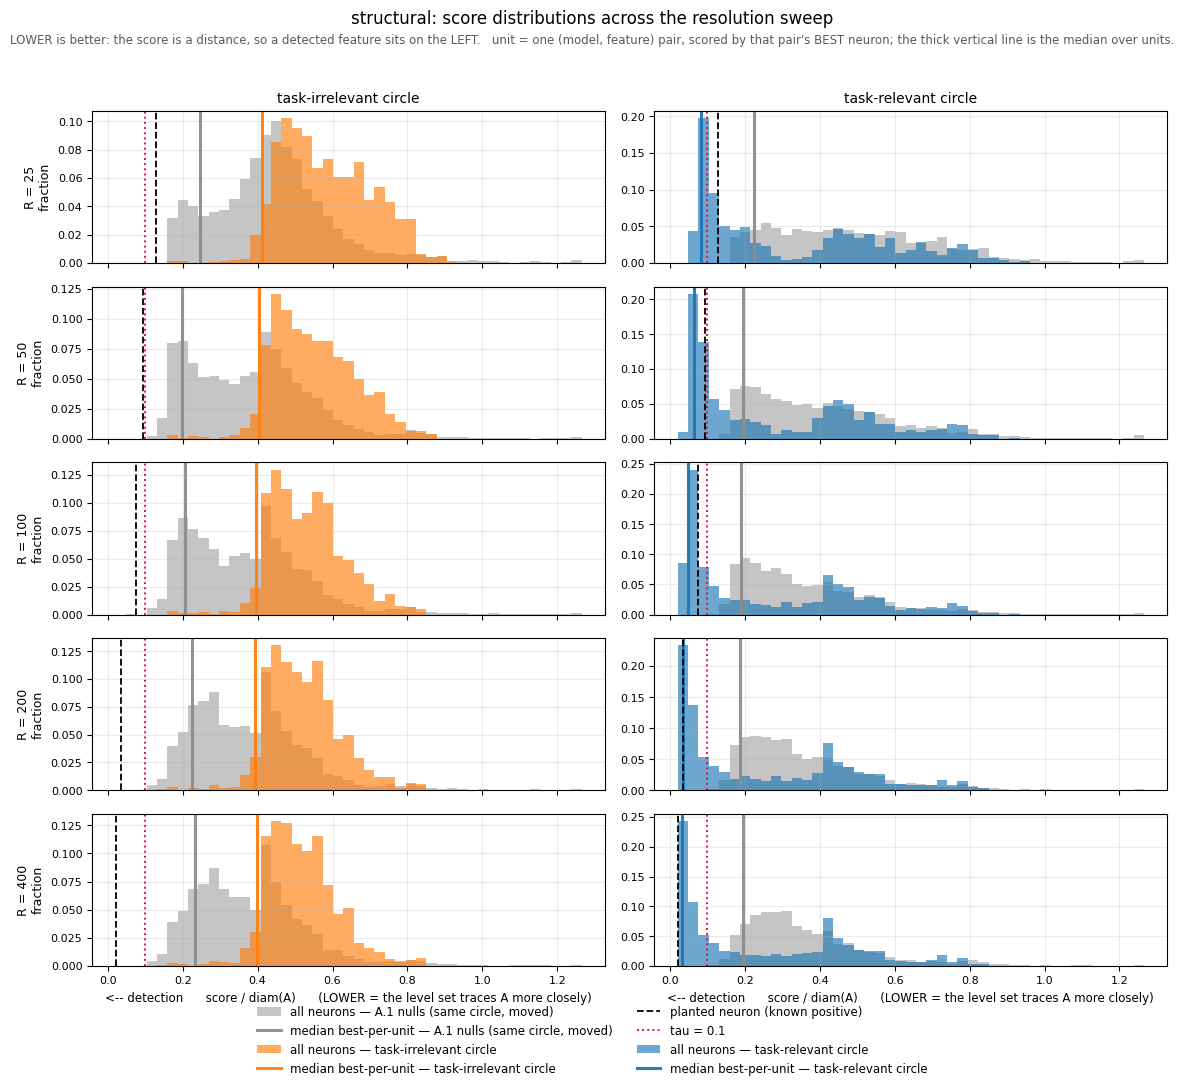

In [17]:
# ── 6. Twenty distributions: 5 resolutions × 2 datasets × 2 criteria ─────────
#     A row is one resolution, a column one task. Grey is the A.1 nulls,
#     colour is the target; black dashed is the planted neuron, crimson is tau,
#     the thick vertical lines are the median of the best neuron per (model,
#     feature) pair, i.e. the only one of the three marks that is allowed to
#     deliver a verdict.
#     Bar height is the FRACTION of all scored neurons, not a density: a
#     criterion that returned no number (homological, NaN = not a single bar of
#     the required dimension was found) shows this as missing area.
from visualization.calibration_plots import plot_sweep_distributions, plot_plateau_curves

if "df_A" not in globals():
    df_A = cal.read_scores_csv(PLANTED_CSV) if PLANTED_CSV.exists() else None

FIGDIR = Path("analysis/results/calibration/figures")
SAVE = False        # True — save to FIGDIR instead of showing

plot_sweep_distributions(
    ens, "structural", planted=df_A, threshold=TAU,
    save_path=(FIGDIR / "sweep_dist_structural.png") if SAVE else None)

---
### How the homological criterion works and what 0 means on its histogram

**What is filtered.** The superlevel sets $\{f \ge c\}$. The level $c$ moves from top to bottom:
at $c=\max f$ the set is empty, at $c=\min f$ it is the whole window. On the way, holes appear in it
and fill in. A loop (a class in $H_1$) is *born* at level $b$ and *dies* at level
$d<b$; its persistence $p=b-d$ is **the width of the interval of levels on which the hole
exists**.

**What it is computed on.** Not on the continuum but on a finite cloud:

* the points are the same field points as for the structural criterion, but cropped to a window of
  radius `neighborhood_factor` = 1.5 × the feature's radius around its centroid (so that a loop
  somewhere at the other end of the box is not credited to this feature), and, on overflow, thinned
  by a random subsample down to `max_sample_points` = 4000 with `seed = 0`;
* the complex is Delaunay (an alpha complex, `backend="delaunay"`), built from the geometry of the
  points alone;
* the filtration is lower-star for $-f$: each simplex is assigned the maximum of $-f$ over its
  vertices. This is exactly the superlevel filtration of $f$;
* **both orientations** are computed, $f$ and $-f$, and the better one is taken: a ring can be a ridge
  (a hole in $\{f\ge c\}$) or the rim of a pit (a hole in $\{-f\ge c\}$);
* infinite bars are clipped at the lowest scanned level.

**How a bar becomes a verdict.** A circle requires `feature_homology = {1: 1}`
— one loop in dimension 1. Then (`src/analysis/homological.py:297`):

1. sort the bars of dimension 1 by persistence;
2. $p_k$ is the longest one, $p_{\text{next}}$ the next one, the "noise" bar;
3. `floor` = `relative_floor` × (max f − min f) over the sample; with
   `relative_floor = 0.1` this is 10% of the field's range in the window;
4. **witness** if all of the following hold at once: $p_k>0$; $p_k \ge 2p_{\text{next}}$ (or
   there is no second bar); $p_k \ge \text{floor}$;
5. **margin** $= p_k - \max(p_{\text{next}},\ \text{floor})$ — this is the score on the
   histogram.

The rule reads as follows: the main loop must be **twice as long as its nearest competitor**
and **no shorter than 10% of the field's range**. The first cuts off "two equal noise holes", the
second "all the holes are tiny".

**What 0 means in the picture.** Zero is exactly the decision boundary: the main bar is exactly as long
as the larger of the two obstacles. To the right of zero the bar is longer than the obstacle, to the
left it is shorter.

Strictly speaking, $\text{margin}\ge 0$ is necessary but not sufficient: the test for twofold
superiority is not encoded in the margin, and in principle $\text{margin}>0$ can occur without a verdict
(when $p_{\text{next}}>\text{floor}$ and $p_k$ lies between $p_{\text{next}}$ and
$2p_{\text{next}}$). **On these data this does not happen even once:** of the 9614 rows with a computed
margin, all 3334 with $\text{margin}\ge 0$ are witnesses, and none of the 6280 with $\text{margin}<0$ is.
The reason is that what binds here is `floor` (≈ 0.18 at a range of ≈ 1.84), while the second bar is
almost always tiny: a window of radius 1.5·r_A physically holds one loop, not two comparable ones. So on
these histograms **the sign of the margin is the verdict**.

**An empty place is not zero.** If no bar of the required dimension was found at all, the margin is
NaN, not 0: "the diagram is empty" and "there was a bar, but it lost" are different facts, and the
second gives a negative margin. The bars are normalised by **all** scored neurons, so the missing area
is exactly the fraction of neurons without a bar, and its percentage is written in the corner of the
panel.

#### Why many neurons have a larger margin than the planted one

In short: **the margin measures contrast, not geometry, and the planted neuron is built quiet on
purpose.**

* The margin is expressed in units of the neuron's own values. For post-tanh $f\in[-1,1]$, so the
  scale runs from 0 to 2. **The size of the loop does not enter the margin at all**: a large circle does
  not live longer than a small one. A sharper and deeper ridge lives longer.
* The planted neuron: a bar from $f=0.760$ to $f=0.272$, length 0.488, margin 0.412.
  `plant_radial_neuron` normalises the cap so that its maximum equals 1, and deliberately keeps the
  subsequent tanh in the linear regime — the docstring says so outright: saturation "flattens the
  profile and washes the level sets out". The field of the planted neuron reaches ≈ 0.76, not ±1.
* A trained neuron is saturated. For the 835 relevant neurons with a bar found at R = 200 the median
  birth is 0.185, the median death −0.814, the median length 0.823, the maximum 1.945: the ring
  survives from "almost +1" to "almost −1".
* Turning `sharpness` is useless: the margin hits a ceiling at 0.685 (0.253 / 0.412 / 0.662 / 0.685
  / 0.685 at sharpness 1 / 2 / 4 / 8 / 16), while the structural score only gets worse,
  from 0.034 to 0.064 — too sharp an edge makes the ridge thinner than the grid.

Hence the reading rule, already formulated below in the section "What must not be read from these
numbers" → "Two different roles of the planted neuron": **for the structural criterion the black line
is a ceiling, for the homological one it is merely a known positive.** "To the right of the black line"
on the homological panel does not mean "better than the ideal".

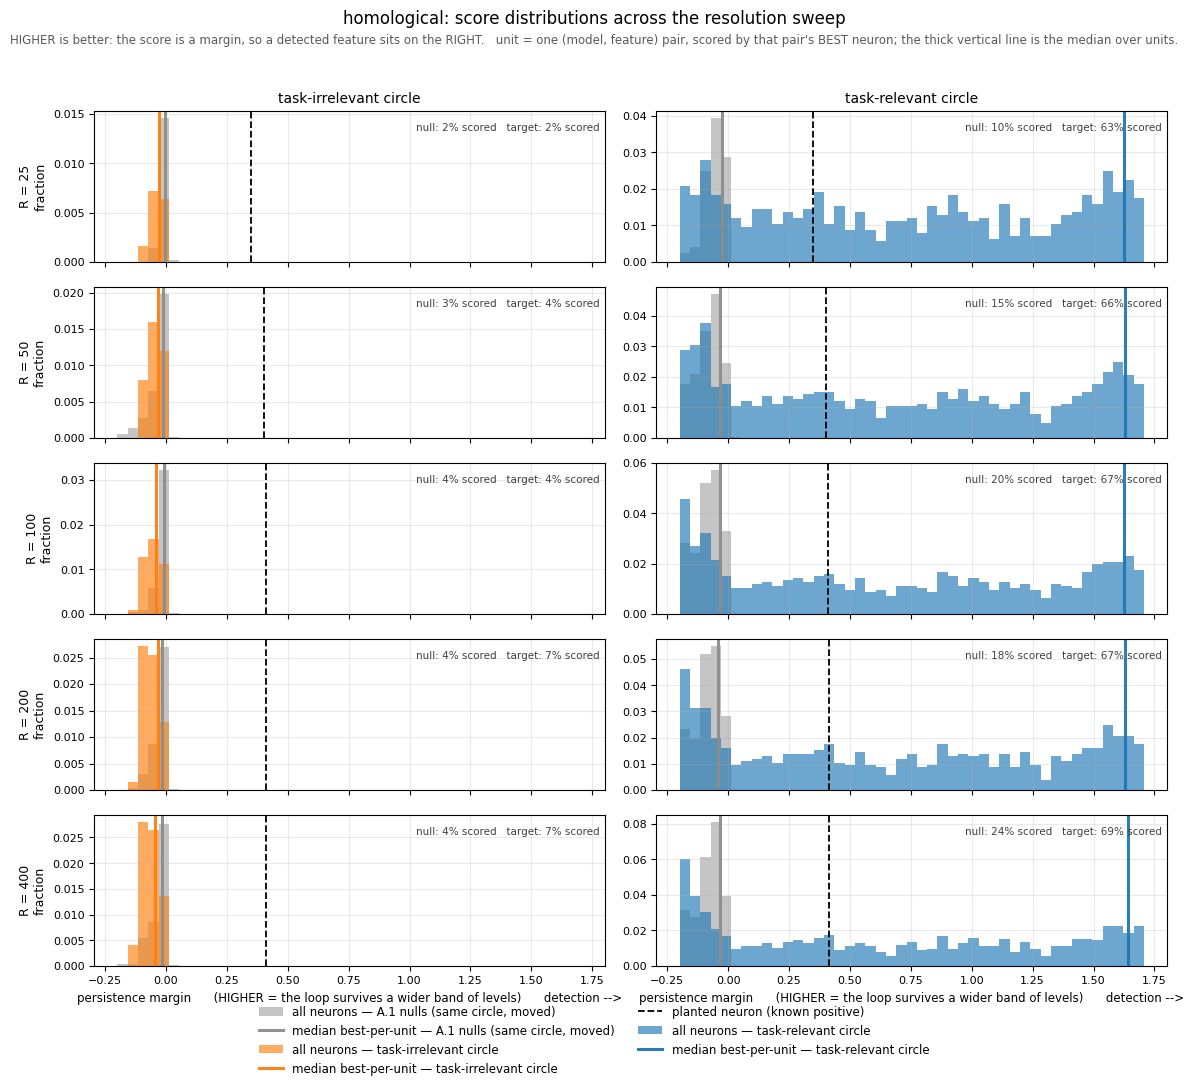

In [18]:
plot_sweep_distributions(
    ens, "homological", planted=df_A,
    save_path=(FIGDIR / "sweep_dist_homological.png") if SAVE else None)

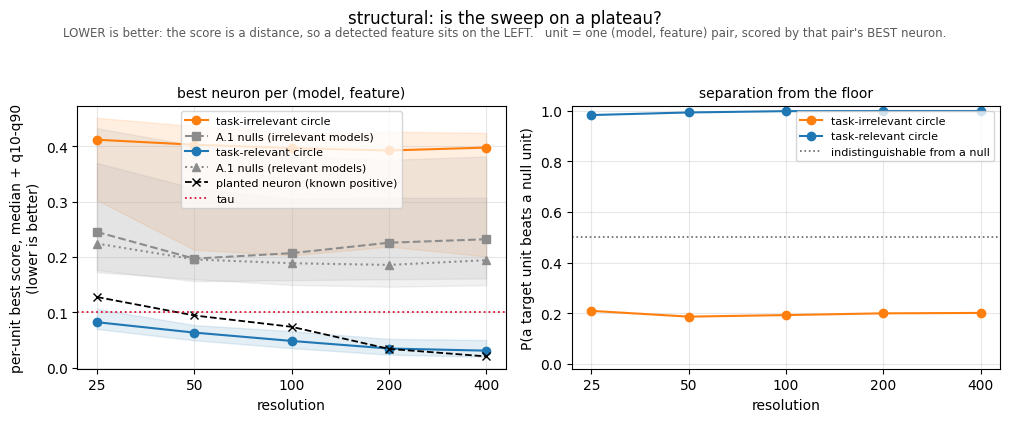

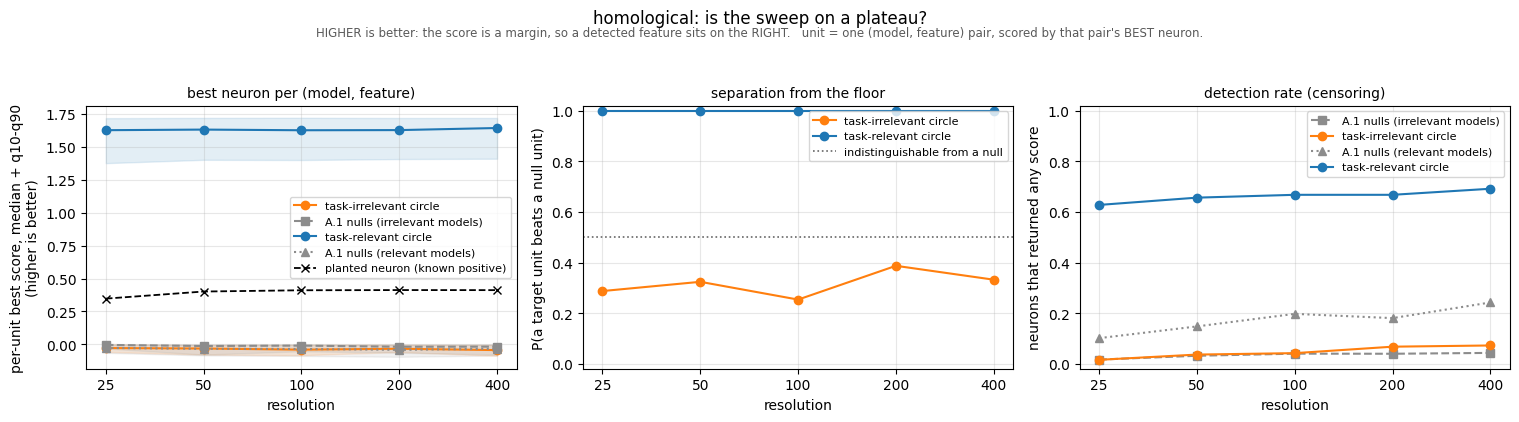

In [19]:
# ── 7. The same sweep, folded down to what the plateau is read from ──────────
#     Left: the best neuron per (model, feature) pair, median and q10–q90 band,
#     next to it the planted neuron. A target curve falling TOGETHER with the
#     planted one is not improving: it goes down following the instrument's own
#     overhead. Middle: P(target beats null) — a verdict without units of
#     measurement, and it is the one that must stop moving. Right (when there
#     is censoring): the fraction of neurons for which the criterion returned a
#     number at all.
plot_plateau_curves(ens, "structural", planted=df_A, threshold=TAU, contrast=contrast,
                    save_path=(FIGDIR / "sweep_plateau_structural.png") if SAVE else None)
plot_plateau_curves(ens, "homological", planted=df_A, contrast=contrast,
                    save_path=(FIGDIR / "sweep_plateau_homological.png") if SAVE else None)

---
### Results of the resolution sweep

Five resolutions × two datasets × two criteria, 50 models per dataset, 25 neurons per model,
5 features (target + 4 A.1 nulls) — 125,000 rows in `analysis/results/calibration/sanity_resolution_sweep.csv`,
summaries in `sanity_resolution_summary.csv` and `sanity_resolution_contrast.csv`.

**The unit of observation**, here and everywhere below, is a *(model, feature)* pair, and its value is the
best neuron of that pair. Not the fraction of witnesses: it inherits a multiplicity that grows with the
network's width by construction. And not "the best of all nulls": the target has one feature, the floor
four placements, and a common minimum would give the floor a fourfold multiplicity that the target does
not have.

#### 1. The answer of the experiment does not depend on resolution

The circle is bitwise the same in both datasets; only the task differs. The fraction of models that have
a witness neuron at τ = 0.1:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| task-relevant | 0.86 | 0.92 | 0.96 | **0.98** | 0.98 |
| task-irrelevant | 0.00 | 0.00 | 0.00 | **0.00** | 0.00 |
| A.1 nulls, relevant (200 units) | 0.000 | 0.000 | 0.000 | **0.000** | 0.000 |
| A.1 nulls, irrelevant (200 units) | 0.000 | 0.000 | 0.005 | **0.005** | 0.005 |

49 models of 50 against 0 of 50 — on one and the same feature. False positives on the nulls: not one of
200 on relevant at any R, and exactly one of 200 on irrelevant at R ≥ 100. The conclusion holds even at
the deliberately coarse R = 25.

The headroom at both ends is large; this is not a borderline result. The best neuron **in the whole**
irrelevant ensemble (1250 neurons) scores 0.1547 at R = 200 — one and a half times above τ.
The only relevant model that did not yield a witness at R ≥ 200 is `model21` (0.1304); it is examined
in the "Sandbox" at the end of the notebook.

#### 2. The plateau of the verdict — from R = 100

`p_superior` = P(a random target unit beats a random null unit) is a quantity without units of
measurement, which is why it is the one that must stop moving:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| relevant | 0.9835 | 0.9938 | 0.9990 | 0.9995 | 0.9995 |
| step \|Δ\| | — | 0.0103 | 0.0052 | 0.0005 | 0.0000 |
| irrelevant | 0.2089 | 0.1861 | 0.1922 | 0.1991 | 0.2007 |
| step \|Δ\| | — | 0.0228 | 0.0061 | 0.0069 | 0.0016 |

At a tolerance of 0.01 the first step that fits within it is the transition 50 → 100, and so do all the
following ones. The plateau is established from **R = 100** on, on both datasets.

The fraction of witnesses at τ behaves more coarsely: its granularity is 1/50 = 0.02, i.e. one step is
one model. From R = 100 to R = 200 exactly one model changes its verdict (`model7`, score 0.1088 — right
at the threshold), and from 200 to 400 none. The tolerance of 0.01 does not apply to this quantity: it is
smaller than its grain. The correct formulation is: **at R ≥ 200 exactly one model fails τ, and this is
stable**.

#### 3. The homological criterion is on its plateau at once — but for a different reason

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| best margin, relevant / target | 1.6266 | 1.6311 | 1.6261 | 1.6273 | 1.6431 |
| best margin, relevant / nulls | −0.0269 | −0.0339 | −0.0349 | −0.0416 | −0.0333 |
| `p_superior`, relevant | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| `p_superior`, irrelevant | 0.2873 | 0.3238 | 0.2535 | 0.3871 | 0.3322 |

The median best margin wanders by 0.016 against a separation of the target from the nulls of 1.67 —
about 1%. The stability is not accidental: the ends of the bar are **values of the function** (birth
≈ +0.2, death ≈ −0.8 for a saturated tanh), not properties of the grid. As soon as the cloud resolves
the ring at all, adding points does not lengthen the bar.

### What must not be read from these numbers

#### The absolute score of the target is not a measurement of the network

The planted neuron is a circle of the right radius in the right place; its true geometric error is
`ideal_score = 0.0016`, i.e. practically zero. Everything it scores is the overhead of the instrument
itself:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| planted (truth ≈ 0) | 0.1278 | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| target median, relevant | 0.0824 | 0.0637 | 0.0486 | **0.0349** | 0.0311 |

At R = 200 the target stands exactly at the instrument's ceiling: 0.0349 against 0.0343. At R = 400 the
instrument drops to 0.0207, but the target only to 0.0311; the planted neuron falls roughly as R^−0.67,
the target as R^−0.35. The neurons' own geometric error is not resolved at any resolution of the sweep.
**Therefore one must report the contrast (`gap`, `p_superior`), not the absolute score of the target**;
if the absolute number is needed nevertheless, the row of the planted neuron at the same R must stand
next to it.

#### Two different roles of the planted neuron

* **structural — it is a ceiling.** The right answer is known and equals zero, so the measured value is
  entirely the resolving power of the instrument. Nothing meaningful can end up below this line, and
  the difference "target − planted" is what can be attributed to the network at all.
* **homological — it is NOT a ceiling but "a known positive, only a quiet one".** The margin is measured
  in units of the neuron's own values and equals the width of the interval of levels on which the ring
  survives, that is, the **contrast**, not the geometry. The size of the loop does not enter it at all:
  large circles do not live longer. `plant_radial_neuron` by construction keeps the subsequent tanh in
  the linear regime (the planted field reaches ≈ 0.76, not ±1) — hence its margin of 0.41 against 1.63
  for a saturated trained neuron. Trained neurons beat the planted one not because they are "better than
  the ideal" but because they are louder. Turning `sharpness` is useless: the margin hits a ceiling at
  0.685, while structural only gets worse (0.034 → 0.064).

#### The floor of the scale is not flat — and it is the most mobile part of the measurement

The median of the best per unit, R = 200, irrelevant:

| placement | `far_right` | `on_blue_disk` | `above_target` | `in_between` |
|---|---|---|---|---|
| median | 0.1764 | 0.2044 | 0.2590 | 0.3675 |

One and the same circle gives from 0.176 to 0.368 depending only on where it was put.
The spread of 0.19 is larger than the `gap` itself (0.166). Therefore the verdict must beat the **softest**
placement — `gap_vs_softest` = 0.130 for relevant at R = 200 — and not the pool.

The floor, moreover, is the least stable part of the measurement: the pooled median of the nulls on
irrelevant takes a step of 0.019 at the transition 100 → 200 and does not satisfy the rule "two
consecutive steps below 0.01", and individual placements wander across R by 0.010–0.026 (the maximum is
`on_blue_disk`, 0.1780 → 0.2044). This is 10–26% of τ. It does not threaten the verdict (gap 0.15), but
**the number for the floor must always be given together with its resolution**.

#### The detection rate of the homological criterion must not be reported at any R

For this criterion `resolution` is not a discretisation but a proxy for the sample size, and it
saturates: `neighborhood_factor = 1.5` leaves a window of radius 1.5·r_A (≈ 15% of the box), and
`max_sample_points = 4000` cuts the rest down with a random subsample.

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| points in the filtration | 89 | 371 | 1515 | 4000 | 4000 |
| points in the grid in total | 625 | 2,500 | 10,000 | 40,000 | 160,000 |

Above R ≈ 160 what changes is not the resolution but which particular 4000 points `seed = 0` drew — one
and the same seed for all 50 models, so its error does not average out over the ensemble.

Checked with separate runs (R = 200, 5–8 models, all neurons, target + `null_in_between`; not included
in the notebook): changing only the `seed` moves the detection rate of the nulls from 0.128 to 0.240,
and removing the subsample entirely (`max_sample_points = 7000`, all ≈ 6100 points of the window) from
0.150 to 0.280. Meanwhile the median best margin of the target moves by 0.003, that of the nulls by
0.001, and `p_superior` stays 1.0000 in both cases.

The point: **event counters at the threshold are unstable, the verdict is not.** For a null the field is
almost flat, and "did a bar longer than 0.1 of the range and twice as long as the next one appear at all"
is decided on the edge. For the target the ring is a coarse feature of the function, and its bar
converged long ago. If you need a "detection rate", take it at the level of units: for the target it is
1.000 at all R.

### Decision: `resolution = 200`

| | R = 100 | **R = 200** | R = 400 |
|---|---|---|---|
| `p_superior`, relevant | 0.9990 | **0.9995** | 0.9995 |
| models that failed τ (of 50) | 2 | **1** | 1 |
| floor, median of the nulls (relevant) | 0.1889 | 0.1858 | 0.1943 |
| structural, time for both datasets | 1,663 s | **6,834 s** | 17,320 s |
| homology: points in the window / cap 4000 | 1,515 / no cut | 6,107 / cuts | 24,482 / cuts |

R = 200 is the smallest resolution at which **both** reported quantities have settled: `p_superior`
(from R = 100) and the number of models failing τ (from R = 200). R = 400 costs 2.5 times as much and
buys nothing: `p_superior` +0.0000, models ±0, floor +0.009.

Along with this, **`max_sample_points = 7000`** should be put into the spec for the homological
criterion:

```python
extra_criteria_kwargs={"homological": {"backend": "delaunay", "max_sample_points": 7000}}
```

This is not a bug fix — it was measured that the verdict does not change with this replacement — but the
removal of an arbitrary constant: at 4000 the answer depends on a single fixed draw, at 7000 there is no
draw at all (the window holds ≈ 6100 points). The price is ×1.6 in time. **The sweep need not be
recomputed:** everything that will be reported has already been measured and is stable.

#### What remains open

`n_levels` is the only hyperparameter not yet frozen. It concerns **only the structural criterion** (the
homological one has no discretisation in level at all) and is not independent of ε: the adaptive ε is
cut off from below at `0.5 · range(f)/(n_levels − 1)`, while ε itself falls as 1/R. At R = 200 this
cutoff already determines ε for roughly a third of the null neurons, but not yet for the target — that
is, changing `n_levels` moves above all **the floor of the scale**. The next section is about this.

### Observations on the data (mine) and analysis

> **for the structural score:**
>
> 1) on the relevant feature the distribution is bimodal, and one mode clearly detects the feature while the other repeats the distribution of the irrelevant feature
> 2) on the irrelevant dataset the distribution on the null feature is bimodal - because we see a picture averaged over 4 features - on some of them the values are simply higher, on others lower. And the bimodality starts to show as the resolution increases
> 3) it turns out that the threshold \tau=0.1 is well chosen — none, or almost none, of the null and irrelevant features fire this criterion, while in almost every relevant case it fires (there is at least someone who fires it). There are two exceptions, though: a model was found that fires an irrelevant / null feature, and, conversely, one where the relevant feature did not fire the criterion
>
> **Next, specifically about the sweep over resolution:**
> (both for task-relevant and for task-irrelevant)
>
> 4) even at the lowest resolution the lower bound of the structural score on the null-features lies in the interval [0.1, 0.15]; increasing the resolution moves it only at the transition from 25 to 50, after which the value does not change.
> 5) the value computed on the planted neuron, by contrast, decreases every time the resolution increases. In particular, at R=25 it is not detected at all, at R=50 it barely enters the detectable region, and only from R=200 on does it gain a sufficient margin over the minimal score values on the null-features.
>
> **on the task-relevant dataset**
>
> 6) the score values on the relevant feature approach 0.025 already from resolution R=50, but a large share of neurons acquire such low values also at resolution R=200.

---

**(1) Agreed, and the refinement turns out to be substantive.** The bimodality is there: at R = 200 the
fraction of relevant neurons below 0.1 is 0.42, and the rest form a second mode. But the second mode
**does not repeat the irrelevant distribution; it is shifted below it**: the median of the upper mode
(neurons with a score > 0.2) is 0.443 against 0.513 for the task-irrelevant target. The difference of
0.07 holds at all resolutions (R = 50: 0.477 against 0.537; R = 400: 0.442 against 0.507).

This reads as follows: even the "non-detecting" neurons of the relevant network are systematically
closer to the circle than any neurons of the irrelevant one. That is, task relevance is visible not only
in the best neuron but in the whole population — more weakly, but visibly. This is **new information**; I
had not looked at it. It cannot be taken as a verdict on its own (a population statistic brings back the
very multiplicity that the "model × feature" unit was introduced to escape), but as an independent
confirming observation it is good, and it is a ready candidate for a separate analysis.

**(2) Agreed, and the mechanism is exactly the one you named.** Medians by placement at the level of
neurons, irrelevant, R = 200: `far_right` 0.280, `on_blue_disk` 0.271, `above_target` 0.372,
`in_between` 0.480. The four placements group into two clusters (≈ 0.27 and ≈ 0.37–0.48), and their
mixture is what gives the two modes.

On "the bimodality shows up as the resolution grows" — also true, and the reason is not that the modes
move apart but that **they narrow**. After R = 50 the centres stay put, while the within-group IQR falls:
`on_blue_disk` 0.208 → 0.128, `far_right` 0.220 → 0.183 from R = 25 to R = 400. The components of the
mixture become narrower while their centres do not move — and the mixture starts to look two-humped.
This too is **new information**: I had not looked at the within-group spread.

**(3) Agreed, this is exactly what was measured — with one correction as to where.** There is one false
positive, and it is on a **null feature** (`model24`, L1n4, `null_above_target`), not on the
task-irrelevant target: not a single neuron of the irrelevant ensemble crossed τ at any resolution. The
opposite exception is `model21`. Both are examined in the "Sandbox".

Let me add what the observation does not contain: the headroom above is not huge. The best neuron **of
all 1250** in the irrelevant ensemble scores 0.1547 at R = 200, i.e. τ = 0.1 is only 55% away from it.

**(4) Half agreed, and the second half matters.** The minimum over all neurons:

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| nulls, **relevant** | 0.1476 | 0.1258 | 0.1187 | 0.1144 | 0.1093 |
| nulls, **irrelevant** | 0.1591 | 0.1205 | **0.0734** | 0.0667 | 0.0673 |

For relevant it is as you say: the range [0.11, 0.15], the main step at the transition 25 → 50, almost no
movement after that. For **irrelevant it is not so**: the minimum goes below 0.1, and the main step falls
on **50 → 100** (0.121 → 0.073), not on 25 → 50.

And this is no detail: **the false positive is produced by the resolution.** At R = 25 and R = 50 there
are zero false positives on the nulls, from R = 100 on exactly one, and it appears precisely because the
lower edge of the null distribution on irrelevant drops below τ at this step.

It **does not follow** from this that a coarse resolution is better: at R = 50 the fraction of relevant
models with a witness is 0.92 against 0.98, i.e. the price of one avoided false positive is three extra
misses. A coarse resolution is not cleaner, it is blinder.

**(5) Fully agreed, and this is an argument I did not have.** The planted neuron against the minimum over
the nulls (irrelevant):

| R | 25 | 50 | 100 | 200 | 400 |
|---|---|---|---|---|---|
| planted | 0.1278 | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| witness at τ? | **no** | yes | yes | yes | yes |
| minimum over the nulls | 0.1591 | 0.1205 | 0.0734 | 0.0667 | 0.0673 |

At R = 25 the instrument **cannot confirm a geometrically ideal witness** — this is perhaps the hardest
calibration fact of the whole sweep. At R = 100 the planted neuron (0.0741) and the best null (0.0734) run
**level**: at this point the instrument does not distinguish the ideal from the best coincidence. Only at
R = 200 does a twofold separation appear, and at R = 400 a threefold one.

This is an independent basis for R ≥ 200 that my analysis did not have: I justified the choice by the
plateau of the verdict and by the stability of the fraction of witnesses, whereas "when the instrument's
ceiling separates from the best null" is a separate and stricter criterion, and it gives the same figure.

**(6) Agreed in substance; the figure is shifted by one step.** The minimum over the relevant target:
0.0613 (R = 25), 0.0429 (50), 0.0272 (100), 0.0165 (200), 0.0117 (400) — it approaches 0.025 at
**R = 100**, not at R = 50. About the mass you are exactly right:

| fraction of relevant neurons | R=25 | R=50 | R=100 | R=200 | R=400 |
|---|---|---|---|---|---|
| with score < 0.025 | 0.000 | 0.000 | 0.000 | 0.015 | 0.046 |
| with score < 0.05 | 0.000 | 0.014 | 0.098 | **0.254** | 0.273 |
| with score < 0.1 | 0.229 | 0.346 | 0.397 | **0.419** | 0.419 |

The mass of very low values appears only by R = 200 and reaches its plateau there too (0.254 → 0.273 and
0.419 → 0.419). Up to R = 100 individual neurons already go low, but there is no population there yet.

---

#### What this changes in the conclusions of the resolution sweep

**The choice of R = 200 does not change — it is strengthened, and by two independent arguments.** Your
point 5 gives a criterion that I did not have: the separation of the instrument's ceiling from the best
null appears precisely at R = 200 (twofold), whereas at R = 100 they run level. Point 6 gives the second:
the population of low-scoring relevant neurons forms and reaches its plateau also by R = 200. Previously
R = 200 was chosen by the stability of the fraction of witnesses, while the plateau of `p_superior` set in
already at R = 100 — now it is clear that R = 100 is insufficient in substance, not only out of caution.

**One formulation needs a correction.** "The plateau of the verdict from R = 100" has to be read with a
footnote: at the same step 50 → 100 the single false positive appears, because the lower edge of the null
distribution on irrelevant drops from 0.121 to 0.073. `p_superior` does not notice this — it is about the
typical unit, not about the tail.

**The headline result is unaffected.** 49 models of 50 against 0 of 50, `p_superior` 0.9995 against
0.199, one false positive per 200 null units — all of this stands.

**A candidate for a separate analysis has appeared:** the shift of the whole population of relevant
neurons relative to irrelevant (point 1), not only of its best representative.

---
## 2. Sweep over `n_levels`

`n_levels` is the last unfrozen parameter of the structural criterion: how many levels `c` are tried
between `min f` and `max f`. The homological criterion does not sweep levels at all (its filtration is
continuous), so the sweep concerns **only the structural one**.

`level_eps` is **not part** of the sweep: it stays `"adaptive"`; that decision has been made and is not
revisited. It does not thereby become independent — the lower cutoff of the adaptive ε equals half a
level step, i.e. `n_levels` moves ε by itself, and exactly for those neurons that ran into the cutoff.
So the sweep over `n_levels` alone is that very joint sweep, only along the single axis along which we
are entitled to move; the `eps_clamped` column shows for whom it turned out to be a sweep over ε.

The rest is fixed: `resolution = 200` (the sweep above), the level grid is the neuron's observed range,
the box is the same one. The nulls are the same four placements, but two of them are taken into the
sweep, the softest and the hardest (why — see below).


### What exactly is needed from this sweep

`n_levels` is the last unfrozen hyperparameter. It concerns **only the structural criterion**: the
homological one has no discretisation in level, its filtration is continuous.

**The level-grid convention is frozen**: the levels are taken
over the neuron's observed range, `linspace(min f, max f, n_levels)`, i.e. `activation=None` in
`structural_kwargs` — this is now the default in all specs. Hence the level step equals
`range(f)/(n_levels − 1)`, and the lower cutoff of the adaptive ε is `range(f)/(2·(n_levels − 1))`,
both **specific to each neuron**.

#### What to expect, and where the catch is

The score is a minimum over levels, and the grids are exactly nested (`linspace(a, b, 201)` contains
`linspace(a, b, 101)`, and so on for 51 and 26). **At a fixed ε, more levels can only lower the score.**
But ε is not fixed: as `n_levels` grows the cutoff falls, and for the neurons that ran into it ε
decreases along with it. At R = 200 these are ≈ 32% of the null neurons and ≈ 1% of the target ones.

So the movement will differ between populations:

* the **target** already stands at the instrument's ceiling (0.0349 against 0.0343 for the planted
  neuron); it has nowhere left to improve — its ε is set by the field, monotonicity works but hits a
  wall;
* the **nulls** have headroom (0.186), and for a third of them ε will move together with the cutoff —
  the direction is not guaranteed.

Hence the main risk and the main question of the sweep: **extra levels can only lower the scores, and
only the nulls and the irrelevant target have room to go lower.** That is, `n_levels` is first of all a
stress test for false positives, not a sensitivity setting. The headroom now: the best neuron of the
irrelevant ensemble is 0.1547 at τ = 0.1, while the lower edge of the nulls on irrelevant has already
dropped to 0.0667 (one false positive). If it moves further, the headline result will move with it.

#### Configuration

| | |
|---|---|
| resolution | **200**, frozen |
| `level_eps` | `"adaptive"`, not touched |
| level grid | observed range (default) |
| `n_levels` | **{6, 26, 51, 101, 201, 401}** — the whole nested chain |
| sample | **35 models × 5 features × 25 neurons on both datasets** |
| `n_levels = 101` | **not computed**: this is exactly the configuration of the resolution sweep at R = 200 |
| criterion | structural only |

* `{6, 26, 51, 101, 201, 401}` are exact nested subsets of one grid (steps
  5 ⊂ 25 ⊂ 50 ⊂ 100 ⊂ 200 ⊂ 400), so "more levels" literally means "the same levels plus new ones". The
  low end 6 is needed for the same reason R = 25 was in the previous sweep: to show that the curve has a
  shape at all, not only a tail.
* 401 is not optional but a condition for the conclusion to be computable: the plateau rule requires
  **two** consecutive steps below the tolerance, and the last interval must be one of them. Without 401
  one can confirm a plateau at 101 at the latest, but not at 201.
* The shape of the sample is the same as in the resolution sweep (models × 5 features × 25 neurons on
  both datasets). This is not a luxury but what makes the `n_levels = 101` column free: it has already
  been computed there, bitwise in this same configuration. In addition, the floor gets its full width
  from four placements on both tasks rather than two placements on one.
* 35 models is the budget knob, and the only one. The comparison is paired (the set of models is the
  same in every cell), so what is read is a shift, not a level, and 35 models × 25 neurons are enough
  both for the median and for the minimum. Fewer models — a shorter run, in direct proportion.
* An additional column `floor = 0.5·(max f − min f)/(n_levels − 1)` and a flag
  `best_level_eps == floor`: without it one cannot tell movement due to the density of levels from
  movement due to ε.

The cost is known exactly, not estimated: a full pass at `n_levels = 101` and R = 200 (50 models ×
5 features × 2 datasets) has already been done and took **113.9 minutes** by the sum of the `seconds`
column. Everything else is a proportion: time ≈ 1.9 h × (n_levels/101) × (models/50).

| models | the whole chain, 101 reused | of which 401 |
|---|---|---|
| 50 | 12.9 h | 7.5 h |
| 40 | 10.3 h | 6.0 h |
| **35** | **9.0 h** | 5.3 h |
| 30 | 7.7 h | 4.5 h |

The loop runs in increasing order of `n_levels`, so everything except 401 is on disk within the first
≈ 3.7 h, and an interrupted run loses only the tail. The mechanics of partial saving is the same as in
the resolution sweep: each pair (`n_levels`, dataset) is saved right after it is computed.

#### How to read the result

1. **Hard guard, look at it first:** the minimum score over all neurons of the irrelevant target and
  over all nulls of both tasks. If it approaches 0.1, we stop at the previous `n_levels`, regardless of
  what `gap` shows.
2. **Main:** `p_superior` and `gap` with a tolerance of 0.01. A plateau is two consecutive steps below the
  tolerance, and the last interval must be one of them.
3. **Attribution:** the fraction of rows with an active cutoff. Small — the density of levels moved;
  large — ε moved.
4. **Choice:** the smallest `n_levels` at which `p_superior` and `gap` are already within the tolerance
  of their values at the largest tested one, and the minimum over irrelevant has not come close to τ.

In [20]:
# ── 8. Configuration of the sweep over n_levels ──────────────────────────────
#     ONE parameter changes. resolution = 200 and the level grid over the
#     observed range are frozen above, level_eps stays "adaptive".
from dataclasses import replace

# The whole nested chain: steps 5 ⊂ 25 ⊂ 50 ⊂ 100 ⊂ 200 ⊂ 400, i.e.
# "more levels" = "the same levels plus new ones". 401 is not optional: the
# plateau rule requires two consecutive steps under the tolerance, and without
# 401 a plateau at 201 cannot be checked.
N_LEVELS_GRID = [6, 26, 51, 101, 201, 401]
NL_RES        = REFERENCE_RES        # 200
NL_CRIT       = CRITS["structural"]  # the homological criterion does not sweep levels

# n_levels = 101 at R = 200 is exactly the configuration of the resolution sweep
# (101 is the default of structural_criterion, the other kwargs are the same),
# so it is not recomputed but taken from that sweep's part files. The check that
# they coincide is in cell 11, on three recomputed rows.
NL_REUSE       = {101}
NL_REUSE_PARTS = Path("analysis/results/calibration/sweep_parts")

# The ONLY budget knob. Time ≈ 1.9 h × (n_levels/101) × (models/50), where
# 1.9 h is the MEASURED time of a full pass at n_levels = 101 (the sum of the
# seconds column of the resolution sweep at R = 200). The whole chain with 101
# reused: 50 models → 12.9 h, 40 → 10.3 h, 35 → 9.0 h, 30 → 7.7 h. The
# comparison is paired (the set of models is the same in every cell), so the
# number of models changes the precision but does not bias the comparison
# across n_levels.
N_MODELS_NL = 50

# The shape of the sample is the same as in the resolution sweep: all features
# on both datasets. This is exactly what makes the n_levels = 101 column free,
# and it also gives the floor its full width from four placements on both tasks.
NL_FEATURES = {tag: list(FEATURES[tag]) for tag in DATASETS}
NL_MODELS   = {tag: PATHS[tag][:N_MODELS_NL] for tag in DATASETS}

# The known worst relevant unit (the only model that failed tau at R = 200) is
# added to the sample if it is not among the first N_MODELS_NL: the question of
# the sweep is whether precisely the edge drifts past tau, and the edge has to
# be in the sample, otherwise the "worst unit" column is empty by construction.
# At N_MODELS_NL = 35 it is included anyway and the block does nothing; the
# safeguard is needed for a smaller number of models.
_ref = ens if "ens" in globals() else (          # resolution sweep: already in memory
    cal.read_scores_csv(SWEEP_CSV) if SWEEP_CSV.exists() else None)
if _ref is not None:
    _rel = _ref[(_ref.criterion == "structural") & (_ref.resolution == NL_RES)
                & (_ref.dataset == "relevant") & (_ref.role == "target")]
    _worst = (cal.best_per_unit(_rel, lower_is_better=True)
              .sort_values("best_score", ascending=False).iloc[0])
    if _worst.model_path not in NL_MODELS["relevant"]:
        NL_MODELS["relevant"] = NL_MODELS["relevant"] + [_worst.model_path]
        print(f"worst unit at R={NL_RES} added to the sample: "
              f"{Path(_worst.model_path).name} ({_worst.best_score:.4f})\n")

NL_FEAT = {tag: {k: FEATURES[tag][k] for k in names}
           for tag, names in NL_FEATURES.items()}

if "n_neurons" not in globals():        # if cell 2 was not run this time
    _m, _ = load_model_instance(PATHS["relevant"][0])
    n_neurons = sum(_m.blocks[l].linear.out_features for l in range(_m.n_layers))

# The cost comes from the ALREADY MEASURED time of the previous sweep (the
# seconds column at R = 200, n_levels = 101), not from a new trial run: the
# sweep over levels is linear in n_levels, so the multiplier is the ratio to 101.
_per_row = {}
for tag in NL_FEAT:
    _c = (_ref[(_ref.criterion == "structural") & (_ref.resolution == NL_RES)
               & (_ref.dataset == tag)] if _ref is not None else None)
    # The MEAN, not the median: total time = rows × mean by definition, and the
    # distribution of times has a heavy right tail (relevant: median 0.57 s,
    # mean 0.74). With the median the estimate is too low by almost 20%.
    _per_row[tag] = float(_c["seconds"].mean()) if _c is not None and len(_c) else 0.5
_rows = {tag: len(NL_MODELS[tag]) * len(NL_FEAT[tag]) * n_neurons for tag in NL_FEAT}
_hour_at_101 = sum(_rows[tag] * _per_row[tag] for tag in NL_FEAT) / 3600

print(f"{sum(_rows.values())} rows per value of n_levels "
      f"({N_MODELS_NL} models × 5 features × {n_neurons} neurons × 2 datasets), "
      f"{_hour_at_101:.2f} h at n_levels = 101")
_total = 0.0
for n in N_LEVELS_GRID:
    h = _hour_at_101 * n / 101
    if n in NL_REUSE:
        print(f"  n_levels={n:4d}: {h:5.2f} h → reused from the resolution sweep")
    else:
        _total += h
        print(f"  n_levels={n:4d}: {h:5.2f} h")
print(f"total ≈ {_total:.1f} h  (everything except the largest n_levels — within the first "
      f"{_total - _hour_at_101 * max(N_LEVELS_GRID) / 101:.1f} h)")


12500 rows per value of n_levels (50 models × 5 features × 25 neurons × 2 datasets), 1.90 h at n_levels = 101
  n_levels=   6:  0.11 h
  n_levels=  26:  0.49 h
  n_levels=  51:  0.96 h
  n_levels= 101:  1.90 h → reused from the resolution sweep
  n_levels= 201:  3.78 h
  n_levels= 401:  7.53 h
total ≈ 12.9 h  (everything except the largest n_levels — within the first 5.3 h)


In [21]:
# ── 9. The field range of each neuron: what both the levels and the cutoff are made of
#     Levels = linspace(min f, max f, n_levels), so step = range/(n_levels−1),
#     and the lower cutoff of the adaptive ε is half a step. Both are SPECIFIC
#     to each neuron, so without this table movement due to the density of
#     levels cannot be told from movement due to ε. The grid is exactly the
#     criterion's, so the numbers are not "similar" but the very same ones.
#     Computed once (minutes), written to disk and reused.
from analysis.fields import evaluate_field_on_grid
from models.NN_analysis import get_hidden_dim

NL_RANGES_CSV = Path("analysis/results/calibration/sanity_nlevels_field_ranges.csv")

if NL_RANGES_CSV.exists():
    ranges = pd.read_csv(NL_RANGES_CSV)
    print(f"reusing {NL_RANGES_CSV} ({len(ranges)} neurons)")
else:
    t0, rows = time.perf_counter(), []
    for tag, paths in NL_MODELS.items():
        for path in paths:
            model, _ = load_model_instance(path)
            for layer_id in range(model.n_layers):
                for coord_id in range(get_hidden_dim(model, layer_id)):
                    v = evaluate_field_on_grid(
                        cal.neuron_function(model, layer_id, coord_id),
                        bounds=BOUNDS, resolution=NL_RES).values
                    rows.append({"model_path": str(path), "dataset": tag,
                                 "layer_id": layer_id, "coord_id": coord_id,
                                 "field_min": float(v.min()),
                                 "field_max": float(v.max())})
    ranges = pd.DataFrame(rows)
    NL_RANGES_CSV.parent.mkdir(parents=True, exist_ok=True)
    ranges.to_csv(NL_RANGES_CSV, index=False)
    print(f"{len(ranges)} neurons in {time.perf_counter() - t0:.0f} s → {NL_RANGES_CSV}")

ranges["field_range"] = ranges.field_max - ranges.field_min
display(ranges.groupby(["dataset", "layer_id"])[["field_min", "field_max", "field_range"]]
        .median().round(3))


reusing analysis/results/calibration/sanity_nlevels_field_ranges.csv (2500 neurons)


field_min  field_max  field_range
dataset    layer_id                                   
irrelevant 0            -0.996      0.996        1.988
           1            -0.740      0.750        1.441
           2            -0.684      0.701        1.348
           3            -0.713      0.715        1.414
           4            -0.716      0.724        1.432
relevant   0            -1.000      1.000        2.000
           1            -0.879      0.842        1.704
           2            -0.777      0.779        1.453
           3            -0.914      0.916        1.768
           4            -0.978      0.972        1.936

In [22]:
# ── 10. A: the planted neuron along n_levels (seconds) ───────────────────────
#     The instrument's ceiling: its true geometric error is ≈ 0
#     (ideal_score = 0.0016), so its score is the overhead of the criterion
#     itself at the given n_levels. A target curve going down TOGETHER with it
#     is not improving: it follows the instrument.
NL_PLANTED_CSV = Path("analysis/results/calibration/sanity_nlevels_planted.csv")

if "planted" not in globals():          # if cell 3 was not run this time
    probe_model, _ = load_model_instance(PATHS["relevant"][0])
    planted = cal.planted_probe(probe_model, FEATURES["relevant"]["relevant"],
                                layer_id=3, coord_id=0, name="planted")

if NL_PLANTED_CSV.exists():
    df_A_nl = cal.read_scores_csv(NL_PLANTED_CSV)
    print(f"reusing {NL_PLANTED_CSV}")
else:
    df_A_nl = cal.scan([planted], {"structural": NL_CRIT}, BOUNDS, NL_RES,
                       grid={"n_levels": N_LEVELS_GRID}, verbose=True)
    df_A_nl.to_csv(NL_PLANTED_CSV, index=False)

display(df_A_nl[["n_levels", "score", "ideal_score", "is_witness", "best_level_eps",
                 "best_adaptive_eps_quantile", "seconds"]].round(4))


reusing analysis/results/calibration/sanity_nlevels_planted.csv


,n_levels,score,ideal_score,is_witness,best_level_eps,best_adaptive_eps_quantile,seconds
0,6,0.0526,0.0016,True,0.0762,1.00,0.1359
1,26,0.0343,0.0016,True,0.0252,0.95,0.3030
2,51,0.0343,0.0016,True,0.0252,0.95,0.5696
3,101,0.0343,0.0016,True,0.0252,0.95,1.0905
4,201,0.0343,0.0016,True,0.0252,0.95,2.0576
5,401,0.0343,0.0016,True,0.0252,0.95,4.1190


In [23]:
# ── 11. B/C: ensemble × features × neurons, for each n_levels ─────────────────
#     The same mechanics as in the resolution sweep: each pair (n_levels,
#     dataset) goes to disk RIGHT AFTER it is computed, what has been computed
#     is reused, the cell can be re-run as many times as you like — only what
#     is not there yet gets computed. To recompute a part, delete its file.
#     CAUTION: a part's name encodes (n_levels, resolution, dataset, criterion)
#     and knows NOTHING about the criterion's other kwargs. If you change the
#     spec (level_eps, activation, quantile, threshold), delete the whole
#     directory, otherwise the run will silently mix two configurations.
NL_PARTS = Path("analysis/results/calibration/nlevels_parts")
NL_PARTS.mkdir(parents=True, exist_ok=True)
NL_SWEEP_CSV = Path("analysis/results/calibration/sanity_nlevels_sweep.csv")

frames = []
for n in N_LEVELS_GRID:
    # n_levels is substituted into the criterion's own kwargs, not into the
    # call: this way the rows carry exactly the configuration they were
    # computed under.
    crit = replace(NL_CRIT, kwargs={**NL_CRIT.kwargs, "n_levels": n})
    for tag in NL_FEATURES:
        part = NL_PARTS / f"nlev{n}_res{NL_RES}_{tag}_structural.csv"
        reuse_src = NL_REUSE_PARTS / f"res{NL_RES}_{tag}_structural.csv"
        if part.exists():
            df = cal.read_scores_csv(part)
            print(f"n_levels={n:4d} {tag:11s} {len(df):5d} rows ← {part.name}")
        elif n in NL_REUSE and reuse_src.exists():
            # The same rows have already been computed by the resolution sweep:
            # n_levels = 101 is the default of structural_criterion, and R, the
            # box, the features and the other kwargs coincide. We take them from
            # there, but FIRST check on three rows that the configuration really
            # is the same: since then both activation and max_sample_points have
            # changed, and the part file's name says nothing about it.
            src = cal.read_scores_csv(reuse_src)
            df = src[src.model_path.isin(NL_MODELS[tag])
                     & src.feature.isin(NL_FEAT[tag])].copy()
            for _, r in df.sample(min(3, len(df)), random_state=0).iterrows():
                _m, _ = load_model_instance(r.model_path)
                _got = cal.measure(
                    cal.trained_probe(_m, int(r.layer_id), int(r.coord_id),
                                      NL_FEAT[tag][r.feature]),
                    crit, BOUNDS, NL_RES)
                assert abs(_got["score"] - r.score) < 1e-6, (
                    f"{reuse_src.name}: {r.probe} gives {_got['score']:.6f} instead of "
                    f"{r.score:.6f} — the configuration has diverged, reuse is not allowed")
            assert len(df) == len(NL_MODELS[tag]) * len(NL_FEAT[tag]) * n_neurons, (
                f"{reuse_src.name}: {len(df)} rows instead of the expected "
                f"{len(NL_MODELS[tag]) * len(NL_FEAT[tag]) * n_neurons}")
            df.to_csv(part, index=False)
            print(f"n_levels={n:4d} {tag:11s} {len(df):5d} rows ← {reuse_src.name} "
                  f"(reused, 3 rows recomputed and matched)")
        else:
            t0 = time.perf_counter()
            df = cal.ensemble_scores(NL_MODELS[tag], NL_FEAT[tag], BOUNDS, NL_RES,
                                     crit, target_name=DATASETS[tag][1],
                                     layer_ids=LAYER_IDS, verbose=False)
            df.to_csv(part, index=False)
            print(f"n_levels={n:4d} {tag:11s} {len(df):5d} rows in "
                  f"{time.perf_counter() - t0:.0f} s → {part.name}")
        df["n_levels"], df["resolution"] = n, NL_RES
        df["dataset"], df["criterion"] = tag, "structural"
        frames.append(df)

nl = pd.concat(frames, ignore_index=True)

# The cutoff and its flag: floor = 0.5 · range/(n_levels − 1), exactly half a
# level step. This is the very quantity that shows what caused the movement —
# the density of levels or the ε that moved along with it.
nl = nl.merge(ranges[["model_path", "layer_id", "coord_id", "field_range"]],
              on=["model_path", "layer_id", "coord_id"], how="left")
assert nl.field_range.notna().all(), "no field range for some of the neurons — re-run cell 9"
nl["level_step"] = nl.field_range / (nl.n_levels - 1)
nl["eps_floor"] = 0.5 * nl.level_step
nl["eps_clamped"] = nl.best_level_eps <= nl.eps_floor * (1 + 1e-9)

nl.to_csv(NL_SWEEP_CSV, index=False)
print(f"\ntotal {len(nl)} rows → {NL_SWEEP_CSV}")


n_levels=   6 irrelevant   6250 rows ← nlev6_res200_irrelevant_structural.csv
n_levels=   6 relevant     6250 rows ← nlev6_res200_relevant_structural.csv
n_levels=  26 irrelevant   6250 rows ← nlev26_res200_irrelevant_structural.csv
n_levels=  26 relevant     6250 rows ← nlev26_res200_relevant_structural.csv
n_levels=  51 irrelevant   6250 rows ← nlev51_res200_irrelevant_structural.csv
n_levels=  51 relevant     6250 rows ← nlev51_res200_relevant_structural.csv
n_levels= 101 irrelevant   6250 rows ← nlev101_res200_irrelevant_structural.csv
n_levels= 101 relevant     6250 rows ← nlev101_res200_relevant_structural.csv
n_levels= 201 irrelevant   6250 rows ← nlev201_res200_irrelevant_structural.csv
n_levels= 201 relevant     6250 rows ← nlev201_res200_relevant_structural.csv
n_levels= 401 irrelevant   6250 rows ← nlev401_res200_irrelevant_structural.csv
n_levels= 401 relevant     6250 rows ← nlev401_res200_relevant_structural.csv

total 75000 rows → analysis/results/calibration/sanity_nlev

In [24]:
# ── 12. Summary, hard guard and attribution ──────────────────────────────────
#     Three things, to be read in this order:
#       guard    — the minimum over ALL neurons of the populations that must not
#                  cross tau (the nulls and the irrelevant target). If it comes
#                  close to tau, we stop at the previous n_levels, whatever gap
#                  shows.
#       contrast — p_superior and gap, tolerance 0.01 = tau/10, on both
#                  datasets: on relevant this is the separation of the target
#                  from the floor, on irrelevant the chance level (the target is
#                  WORSE than its own nulls).
#       eps_clamped — the fraction of rows with an active cutoff: small — the
#                  density of levels moved, large — ε moved.
nl_summary  = cal.sweep_summary(nl, by=("criterion", "n_levels", "dataset"))
nl_contrast = cal.sweep_contrast(nl, by=("criterion", "n_levels", "dataset"),
                                 threshold=TAU)
nl_summary.to_csv("analysis/results/calibration/sanity_nlevels_summary.csv", index=False)
nl_contrast.to_csv("analysis/results/calibration/sanity_nlevels_contrast.csv", index=False)

_units = cal.best_per_unit(nl, lower_is_better=True,
                           unit=("model_path", "feature", "n_levels", "dataset"))
guard = (nl.groupby(["dataset", "role", "n_levels"], sort=True)
           .agg(n_neurons=("score", "size"),
                min_score=("score", "min"),
                neurons_below_tau=("score", lambda s: int((s <= TAU).sum())),
                eps_clamped=("eps_clamped", "mean"),
                med_eps=("best_level_eps", "median"),
                med_eps_floor=("eps_floor", "median"))
           .reset_index()
           .merge(_units.groupby(["dataset", "role", "n_levels"])["best_score"]
                  .agg(unit_median="median", unit_worst="max",
                       units_below_tau=lambda s: int((s <= TAU).sum()))
                  .reset_index(),
                  on=["dataset", "role", "n_levels"]))

print("hard guard (the nulls and the irrelevant target must not approach tau = "
      f"{TAU}):")
display(guard.round(4))
print("contrast of the target against its own floor:")
display(nl_contrast.round(4))


hard guard (the nulls and the irrelevant target must not approach tau = 0.1):


,dataset,role,n_levels,n_neurons,min_score,neurons_below_tau,eps_clamped,med_eps,med_eps_floor,unit_median,unit_worst,units_below_tau
0,irrelevant,null,6,5000,0.1566,0,0.5752,0.1508,0.1508,0.2922,0.4912,0
1,irrelevant,null,26,5000,0.1124,0,0.4670,0.0305,0.0302,0.2251,0.4612,0
2,irrelevant,null,51,5000,0.0900,1,0.3360,0.0166,0.0151,0.2250,0.4577,1
3,irrelevant,null,101,5000,0.0667,1,0.1802,0.0100,0.0075,0.2259,0.4558,1
4,irrelevant,null,201,5000,0.0582,1,0.0838,0.0097,0.0038,0.2257,0.4558,1
5,irrelevant,null,401,5000,0.0482,3,0.0452,0.0097,0.0019,0.2239,0.4558,3
6,irrelevant,target,6,1250,0.1900,0,0.5752,0.1508,0.1508,0.4408,0.5150,0
7,irrelevant,target,26,1250,0.1574,0,0.4056,0.0308,0.0302,0.4010,0.4666,0
8,irrelevant,target,51,1250,0.1549,0,0.0632,0.0215,0.0151,0.4023,0.4641,0
9,irrelevant,target,101,1250,0.1547,0,0.0024,0.0213,0.0075,0.3923,0.4641,0


contrast of the target against its own floor:


,criterion,n_levels,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
0,structural,6,irrelevant,0.4408,0.2922,null_on_blue_disk,0.1825,-0.1486,-0.2583,0.1947,0.00,0.000
1,structural,6,relevant,0.0478,0.2402,null_far_right,0.1795,0.1924,0.1316,0.9907,0.92,0.000
2,structural,26,irrelevant,0.4010,0.2251,null_far_right,0.1714,-0.1759,-0.2296,0.1957,0.00,0.000
3,structural,26,relevant,0.0363,0.2093,null_far_right,0.1754,0.1730,0.1391,0.9998,0.96,0.000
4,structural,51,irrelevant,0.4023,0.2250,null_far_right,0.1732,-0.1773,-0.2291,0.1943,0.00,0.005
5,structural,51,relevant,0.0353,0.1958,null_far_right,0.1672,0.1604,0.1319,0.9996,0.96,0.000
6,structural,101,irrelevant,0.3923,0.2259,null_far_right,0.1764,-0.1664,-0.2158,0.1991,0.00,0.005
7,structural,101,relevant,0.0349,0.1858,null_far_right,0.1650,0.1509,0.1300,0.9995,0.98,0.000
8,structural,201,irrelevant,0.3923,0.2257,null_far_right,0.1819,-0.1665,-0.2104,0.1994,0.00,0.005
9,structural,201,relevant,0.0349,0.1810,null_far_right,0.1638,0.1461,0.1289,0.9995,0.98,0.000


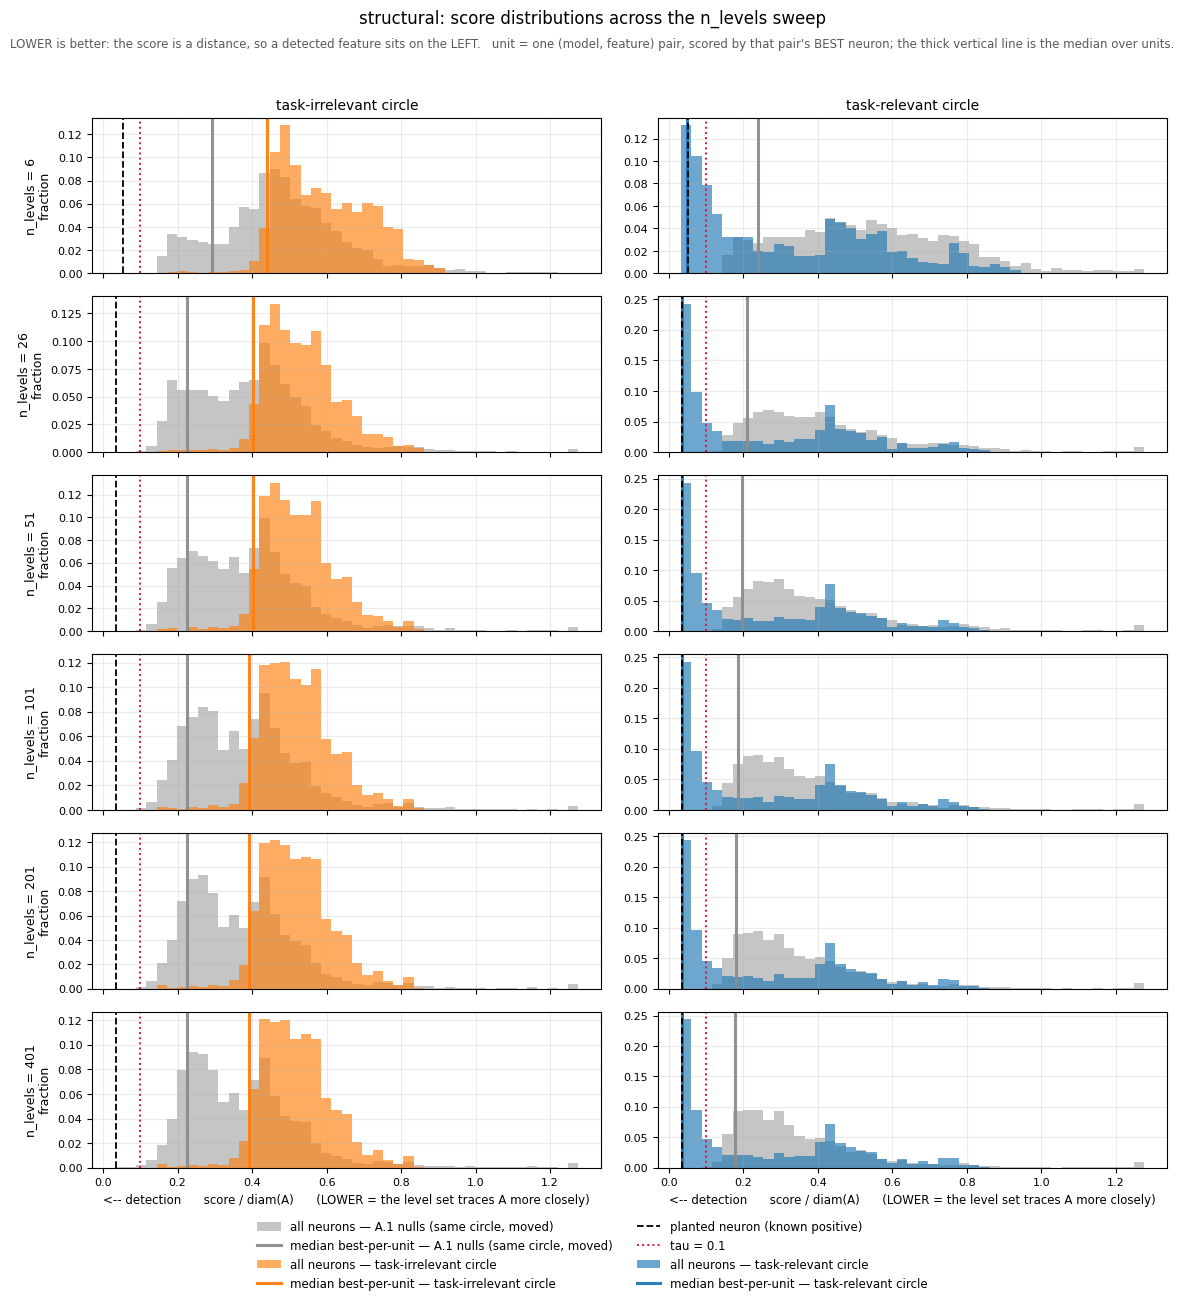

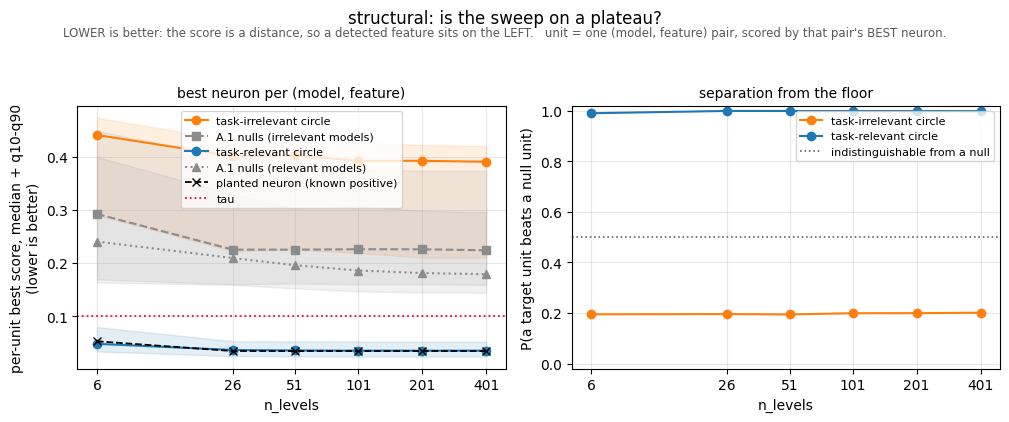

In [25]:
# ── 13. The same two pictures as for resolution, but along n_levels ──────────
#     axis="n_levels" is a parameter, not a column rename: the plateau is read
#     the same way whatever is swept, and there must be no second copy of these
#     functions.
from visualization.calibration_plots import plot_sweep_distributions, plot_plateau_curves

plot_sweep_distributions(
    nl, "structural", planted=df_A_nl, threshold=TAU, axis="n_levels",
    save_path=(FIGDIR / "nlevels_dist_structural.png") if SAVE else None)

plot_plateau_curves(
    nl, "structural", planted=df_A_nl, threshold=TAU, contrast=nl_contrast,
    axis="n_levels",
    save_path=(FIGDIR / "nlevels_plateau_structural.png") if SAVE else None)


---
### Results of the sweep over `n_levels`

Six values × two datasets, 50 models per dataset, 25 neurons per model, 5 features
(target + 4 A.1 nulls) — 75,000 rows in `analysis/results/calibration/sanity_nlevels_sweep.csv`,
summaries in `sanity_nlevels_summary.csv` and `sanity_nlevels_contrast.csv`. The `n_levels = 101` column
was not computed: it is exactly the configuration of the resolution sweep at R = 200, and the match was
checked by recomputing six rows (discrepancy 0.0e+00 … 5.6e−17). The other five values took
9 h 49 min of computation.

#### 1. The answer of the experiment does not depend on `n_levels`

The fraction of models that have a witness neuron at τ = 0.1:

| `n_levels` | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| task-relevant | 0.92 | 0.96 | 0.96 | **0.98** | 0.98 | 0.98 |
| task-irrelevant | 0.00 | 0.00 | 0.00 | **0.00** | 0.00 | 0.00 |
| A.1 nulls, relevant (200 units) | 0.000 | 0.000 | 0.000 | **0.000** | 0.000 | 0.000 |
| A.1 nulls, irrelevant (200 units) | 0.000 | 0.000 | 0.005 | **0.005** | 0.005 | 0.015 |

49 models of 50 against 0 of 50 on one and the same circle — at any number of levels, down to the
deliberately coarse six. As in the resolution sweep, the conclusion is not borderline: `p_superior` on
relevant is 0.991 at six levels and 0.999 at all the others, on irrelevant 0.19–0.20 (the target is
WORSE than its own nulls; this is exactly the chance level).

#### 2. The target hits the instrument's ceiling already at `n_levels = 26`

| | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| planted neuron (true error ≈ 0) | 0.0526 | 0.0343 | 0.0343 | **0.0343** | 0.0343 | 0.0343 |
| target, median of the best per unit | 0.0478 | 0.0363 | 0.0353 | **0.0349** | 0.0349 | 0.0349 |
| worst relevant unit (`model21`) | 0.2318 | 0.1304 | 0.1304 | **0.1304** | 0.1297 | 0.1294 |

The planted neuron stops changing after 26 and stays dead still from then on: its 0.0343 is the
instrument's overhead at R = 200, and it is set by the **resolution**, not by the density of levels. The
target median coincides with it to within 0.0006. The target has nowhere left to improve, and that is
exactly why its curve on the plot lies on the black dashed line.

#### 3. The floor does NOT reach a plateau — it drifts down monotonically

This is the main result of the sweep, and it is asymmetric to the previous point:

| | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| median of the floor (relevant) | 0.2402 | 0.2093 | 0.1958 | **0.1858** | 0.1810 | 0.1788 |
| `gap` = floor − target | 0.1924 | 0.1730 | 0.1604 | **0.1509** | 0.1461 | 0.1438 |
| **minimum over all 10,000 null neurons** | 0.1443 | 0.1124 | 0.0900 | **0.0667** | 0.0582 | **0.0482** |
| second and third lowest | 0.146 / 0.151 | 0.114 / 0.114 | 0.113 / 0.114 | **0.111 / 0.113** | 0.110 / 0.111 | **0.075 / 0.095** |
| null neurons below 0.15 | 2 | 61 | 84 | **101** | 122 | 136 |
| false positives (score ≤ τ) | 0 | 0 | 1 | **1** | 1 | **3** |

The mechanism is elementary and was predicted in advance: **the score is a minimum over levels, so more
levels = more attempts.** The target cannot make use of the extra attempts — it stands at the
instrument's ceiling; the floor has room to fall (0.18 against a threshold of 0.10), and it falls.
`n_levels` is therefore not a sensitivity knob but a stress test for false positives.

#### 4. The formal plateau: it is the floor that binds, not the target

Tolerance 0.01 = τ/10; a plateau is two consecutive steps below the tolerance, and the last interval must
be one of them.

| quantity | steps 6→26→51→101→201→401 | plateau from |
|---|---|---|
| target, unit median | 0.0116 · 0.0009 · 0.0004 · 0.0000 · 0.0000 | 26 |
| `p_superior` (relevant) | 0.0091 · 0.0002 · 0.0001 · 0.0000 · 0.0002 | 26 |
| `gap_vs_softest` | 0.0075 · 0.0072 · 0.0019 · 0.0011 · 0.0002 | 6 |
| **floor, unit median** | 0.0310 · 0.0135 · 0.0100 · 0.0048 · 0.0023 | **101** |
| **`gap`** | 0.0194 · 0.0126 · 0.0096 · 0.0048 · 0.0023 | **51–101** |
| minimum over the nulls | 0.0319 · 0.0224 · 0.0233 · 0.0086 · 0.0100 | not reached |

The step 51 → 101 of the floor and of `gap` sits exactly at the tolerance (0.0096–0.0100), so the binding
quantity is the floor, and its plateau begins at 101.

#### 5. Attribution: from which `n_levels` ε is set by the field rather than by the level grid

The fraction of neurons whose `best_level_eps` ran into the cutoff `0.5 · range(f)/(n_levels − 1)`:

| `n_levels` | 6 | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|---|
| relevant / target | 0.547 | 0.080 | 0.009 | **0.001** | 0.000 | 0.000 |
| irrelevant / target | 0.575 | 0.406 | 0.063 | **0.002** | 0.000 | 0.000 |
| relevant / nulls | 0.587 | 0.403 | 0.243 | **0.148** | 0.098 | 0.061 |
| irrelevant / nulls | 0.575 | 0.467 | 0.336 | **0.180** | 0.084 | 0.045 |

This is the answer to the question of what exactly was being moved. At `n_levels = 26`, for 40–47% of the
neurons ε is set by the **level grid**, not by the field: the "adaptive" ε is not adaptive there. By 101
none of this is left for the target (0.1%), while a sixth is left for the floor. Beyond 101 only the
density of levels changes — the median ε no longer moves (0.0176 → 0.0174 → 0.0173 on the relevant
nulls), yet the minimum over the nulls keeps falling all the same. That is, the whole effect beyond 101
is pure multiplicity of attempts.


### What must not be read from these numbers

**The three false positives at 401 do not mean "the criterion got better at finding circles".**
By name: `model24 L1n4` on `null_above_target` (the very ellipse from the "Sandbox", examined there via
the Morse lemma) stays below τ from 51 on and drifts 0.0900 → 0.0667 → 0.0582 → 0.0482; at 401 it is
joined by `model4 L3n4` (0.0754) and `model49 L3n1` (0.0946), both on `null_far_right`. None of them
"saw" the null better — it is just that with 400 levels each neuron has four times as many attempts to
hit as with 100. `model4 L3n4` moreover has `field_range = 0.167` against an ensemble median of 1.51: it
is an almost dead neuron (1.2% of neurons are like that), and its levels are simply very dense.

**The number "1 false positive" itself is indistinguishable between 51, 101 and 201.** It is one neuron
out of 5000; the granularity of the counter is one. Another quantity is distinguishable: how the whole
lower tail of the floor slides towards the threshold — 2 → 61 → 84 → 101 → 122 → 136 neurons below
0.15, and the 0.1st percentile 0.158 → 0.120 → 0.120 → 0.116 → 0.115 → 0.114. The tail drifts
monotonically and without a plateau.

**The fraction of witness models (0.92 → 0.98) has a grain of 1/50 = 0.02**, so the tolerance of 0.01
does not apply to it. The correct formulation: at `n_levels ≥ 101` exactly one model fails τ
(`model21`), at 26–51 two, at 6 four.

**`gap` shrinks as `n_levels` grows (0.192 → 0.144), but this is not a worsening of the separation.**
It shrinks only because the floor goes down while the target stays put; the dimensionless `p_superior`
does not move at all (0.9998 → 0.9993), and neither does `gap_vs_softest` (0.139 → 0.129). The statement
"the target is separated from the floor" does not depend on `n_levels`; what depends on it is the
headroom to the threshold.

**The median of the irrelevant target drifts too (0.4408 → 0.3904), but its minimum does not:** 0.1900 →
0.1574 → 0.1549 → 0.1547 → 0.1539 → 0.1539, i.e. the best neuron of the whole irrelevant ensemble (1250
neurons) is one and a half times above τ at any `n_levels`. The irrelevant target does not threaten the
threshold at any number of levels; it is the nulls that threaten it.


### Why this sweep is poorer than the resolution sweep

The shapes of the distributions barely move, and this is not an accident of sampling — the two
parameters have influence of different orders.

The score is `min over c of D(c)`, where `D(c)` is the normalised Chamfer distance from the best
component of the band `{|f − c| ≤ ε}` to A.

* **`resolution` changes `D(c)` itself, at every `c`.** A curve on a grid cannot be localised more
  precisely than the step `h`; on a coarse grid components break apart and merge — that is, the object
  being measured is a different one. This is a **first-order** effect in `h`.
* **`n_levels` changes only how densely we try `c`.** `D(c)` depends smoothly on `c`, and we are looking
  for its minimum; near a smooth minimum `D(c* + δ) − D(c*) = O(δ²)`. Doubling the number of levels cuts
  the shortfall **fourfold** — and runs into the floor set by the grid. This is a **second-order**
  effect, and it dies out.

This can be checked directly in the data: the target median at R = 200 freezes at 0.0349, and the planted
neuron at 0.0343. This is the floor of the grid; levels cannot push the score below it, however many of
them are added.

Hence a prediction about the interaction of the two parameters: **the finer the grid, the more extra
levels are worth** — the floor they run into is lower. At R = 400 the plateau in `n_levels` probably sets
in later than at R = 200. We did not measure this, and when the resolution is changed it is worth looking
at again.

#### What this sweep did give — four observations that were not there before

**1. The nulls are four to six times more sensitive to discretisation than the target.** The fraction
of neurons whose score differs from the reference (n = 401) by more than 0.01, at n = 51:

| | target | nulls |
|---|---|---|
| relevant | 9.1% | 55.5% |
| irrelevant | 13.7% | 47.7% |

The reason is substantive: the target has a **right level** — the minimum of `D(c)` is sharp and
well-defined, so refining the grid does not move it. A null essentially has no minimum, the landscape is
flat, and at every number of levels a different `c` wins. That is, **the robustness of the score to
discretisation is in itself a sign of detection** — a signal that the criterion does not use, and a
candidate for a separate instrument.

**2. The identity of the best neuron holds up much worse than its value.** The same neuron remains the
best for a (model, feature) pair in 54.6% of cases at 26 → 51, **67.8% at 51 → 101**, 75.0% at
101 → 201, and 83.4% at 201 → 401. The statement "this model has a witness" is stable; the statement
"this particular neuron is the witness" is noticeably weaker. For ablation (experiment 7), which strikes
a specific neuron, this is a direct limitation.

**3. The score of the worst null neuron is set not by the field but by the ε cutoff.** For the only
false positive (`model24 L1n4`), `best_level_eps` exactly equals `eps_floor` both at 51 (0.0103) and at
101 (0.0051), and its score falls exactly as the cutoff does: 0.0900 → 0.0667 → 0.0582 → 0.0482.
This is why the hard guard has no plateau — it tracks `range(f)/(2(n − 1))`, not the network.

**4. The floor decreases by a power law rather than reaching a shelf.** The minimum over the 10,000 null
neurons: 0.1443 → 0.1124 → 0.0900 → 0.0667 → 0.0582 → 0.0482, which is close to `n^(−0.28)` over the
whole range from 6 to 401. This is the measured **sensitivity of the floor to the number of attempts**,
and it will be needed in experiment 2 — see the section on transferring the nulls below.


### Decision: `n_levels = 101`

| | 26 | 51 | **101** | 201 | 401 |
|---|---|---|---|---|---|
| `p_superior`, relevant | 0.9998 | 0.9996 | **0.9995** | 0.9995 | 0.9993 |
| models that failed τ (of 50) | 2 | 2 | **1** | 1 | 1 |
| false positives on the nulls | 0 | 1 | **1** | 1 | 3 |
| minimum over the nulls (headroom to τ) | 0.1124 | 0.0900 | **0.0667** | 0.0582 | 0.0482 |
| ε set by the grid: target / nulls | 0.41 / 0.44 | 0.06 / 0.29 | **0.002 / 0.16** | 0 / 0.09 | 0 / 0.05 |
| time for both datasets | 0.6 h | 0.9 h | **1.9 h** | 2.9 h | 5.0 h |

**Why not 26 and not 51.** Not because of the numbers but because of the regime: there, for 40% (26) and
25–34% (51) of the neurons the adaptive ε runs into the cutoff set by the level grid, i.e. what is
measured is not what is claimed — not the local scale of the field but the step of the sweep. Besides,
`gap` has not yet settled there (0.173 and 0.160 against 0.144 at 401, deviations of 0.029 and 0.017 at a
tolerance of 0.01).

**Why not 201 and not 401.** They buy nothing measurable: `p_superior` ±0.0002, target median ±0.0000,
the same 49/50. The price is paid in time (×1.5 and ×2.6) and in headroom to the threshold: the minimum
over the nulls goes 0.0667 → 0.0582 → 0.0482, and at 401 there become three false positives instead of
one. The only quantity that changes with them is the one we do not want to change.

**Why 101.** It is the last value at which the floor is still on its plateau (the step 51 → 101 is
exactly at the tolerance, then 0.005 and 0.002) and at the same time the first at which the target's ε is
set entirely by the field rather than by the grid (0.1% against 6% at 51). Plus two practical
consequences: 101 is **the default of `structural_criterion`**, so nothing in the spec needs changing,
and the whole `sanity_resolution_sweep.csv` already computed was done at exactly this setting, i.e. it
remains valid in full.

#### Reconsideration: why not take 51 and compute twice as fast?

The argument for 51 is serious: the structural criterion accounts for **70.8%** of the time of this
experiment (homology for the remaining 29.2%), so `n_levels = 51` saves about a third of every future
run, and exactly half where homology is not computed.

> **The main argument against 51 is a single one.** At 51 the floor is raised by the discretisation
> itself, and raised in the direction that flatters us.
>
> The mechanics: when the adaptive ε runs into the lower cutoff `0.5·range(f)/(n − 1)`, it is
> **increased** relative to what the field suggested. A thicker band `{|f − c| ≤ ε}` gives a fatter level
> curve and hence a **larger** score. Now look at whom the cutoff is active for:
>
> | | relevant target | irrelevant target | relevant nulls | irrelevant nulls |
> |---|---|---|---|---|
> | n = 51 | 0.9% | 6.3% | **24.3%** | **33.6%** |
> | n = 101 | 0.1% | 0.2% | 14.8% | 18.0% |
>
> At 51 the target is practically untouched, while a quarter to a third of the floor is affected. The
> floor inflates, the target does not, and the gap between them grows: `gap` = **0.1604** at 51, 0.1509
> at 101, 0.1438 at 401. **The coarser the level grid, the better our result looks** — and by exactly the
> amount created by the cutoff, not by the network.
>
> Therefore "at 51 the floor is safer" is not an argument for 51 but a symptom. One must not choose the
> value of a hyperparameter because the result looks more convincing at it; one must choose the value at
> which there is less of this artefact at a reasonable price. The remaining artefact relative to the
> reference n = 401: **0.0166** at 51, **0.0070** at 101, 0.0023 at 201. 101 levels remove more than half
> of it for 2× the price; 201 would remove another 0.0047 for another 1.5×.

Everything else below is a check that this argument is not outweighed by something more important. It is
not: by the verdict, 51 and 101 are indistinguishable.

**Nothing is lost in the verdict.** The verdict `score ≤ τ` differs for **2 neurons out of 12,500**
(0.016%), and both sit at the threshold to within the fourth decimal:

| neuron | n = 51 | n = 101 | n = 401 |
|---|---|---|---|
| `model7 L4n3` | 0.1002 | 0.0953 | 0.0953 |
| `model36 L3n2` | 0.1007 | 0.0966 | 0.0956 |

Because of the first of them there are two models failing τ at 51 and one at 101. But `model7` fails by
**0.0002** — this is not a difference in sensitivity, it is a coin landing on its edge. A choice of
hyperparameter must not be staked on such a difference.

**On the floor, 51 is even safer:** the minimum over the nulls is 0.0900 against 0.0667, `gap` 0.1604
against 0.1509, the false positive is one and the same. `p_superior` 0.9996 against 0.9995.

**What is lost is the per-neuron reproducibility of the score.** The deviation from the reference
n = 401:

| | median \|Δ\| | 90th pct. | \|Δ\| > 0.01 |
|---|---|---|---|
| n = 51 | 0.0069 | 0.0745 | **43.5%** |
| n = 101 | 0.0023 | 0.0392 | **27.0%** |

Importantly, this is **a systematic shift, not noise**: the grids are nested, so the denser one can only
find a minimum that is no worse, and `score(51) ≥ score(101)` holds for 86.2% of the neurons with a
median difference of +0.0010. A systematic shift is the same in all cells and cancels in comparisons — it
spoils only absolute statements and comparisons with numbers computed at a different `n_levels`.

**And the argument from the inset only strengthens with resolution.** The raw ε scales as `|∇f|·h`,
while the cutoff scales as `range(f)/(2(n−1))` and does not depend on the grid at all, so the finer the
grid, the more often the cutoff wins. At R = 400 and n = 101 it already determines ε for 55% of the null
neurons; at n = 51 it would determine it for the majority. Since future experiments will run at different
resolutions (see the next section), 51 ties the floor to the level grid in exactly the regime we are
heading towards.

**In sum.** 101 stays — but the honest formulation is this: *by the verdict, 51 and 101 are one and the
same detector*, and if a particular run is limited by the computational budget, `n_levels = 51` will not
change a single conclusion, provided that **everything within that run is computed at one and the same
`n_levels`** (otherwise the systematic shift of +0.001…+0.007 stops cancelling). Values in between — 65,
81 — were not measured: they are not in the nested chain, they cannot be compared with the sweep, and
the gain they give is partial. The choice should be made between the two measured ones.

Note that one can become twice as fast without touching `n_levels` at all — the next section is about
the grid currently being 1.8 times denser along one axis than along the other, which is pure overpayment.

#### The frozen configuration of the detector

```python
resolution      = 200          # resolution sweep
n_levels        = 101          # this sweep; the default of structural_criterion
level_eps       = "adaptive"   # decision made, not swept
levels          = linspace(min f, max f, n_levels)   # activation=None, observed range
threshold τ     = 0.1
# homological criterion:
backend = "delaunay", max_sample_points = 7000
```

The headroom to the threshold is worth remembering when interpreting any subsequent experiment: the floor
is not "zero" but a quantity of 0.18 with a lower edge of 0.067 at τ = 0.1. The criterion passes one neuron
out of 5000 on a null, and this is a property of the instrument, not of the network.


---
## Transferring the calibration to other scales

The two sweeps above froze the numbers for **this** box and **this** circle. We do not intend to sweep
hyperparameters in every experiment, so the question is: which of the frozen quantities are
dimensionless and transfer as they are, and which are tied to scale and need recomputing.

### What is already dimensionless and needs nothing

| quantity | why it transfers |
|---|---|
| **τ = 0.1** | the score is divided by `diam(A)`, i.e. the threshold is "a fraction of the feature's diameter". A circle twice as large — and the tolerance is twice as large in absolute units. |
| **`n_levels = 101`** | the levels are built by `linspace(min f, max f, n)`, and a neuron's `f` is always in (−1, 1). The number of levels is a fraction of the range; it has nothing to do with geometry. This is exactly why the transfer question does not arise for `n_levels`. |
| **`level_eps = "adaptive"`** | the raw ε is taken from the local jumps of the field, i.e. `≈ \|∇f\|·h`, and scales together with the grid by itself. The lower cutoff `0.5·range(f)/(n−1)` is dimensionless too. |
| **`neighborhood_factor = 1.5`** in homology | the window is already given in feature radii. |

### What is tied to scale: `resolution`

At present `resolution = 200` on a 13.5 × 7.5 box with `diam(A) = 3.0`. Two facts follow from this that
are visible only in dimensionless form.

**Fact one: the cells are not square.** `resolution` is a single number for both axes, while the box is
elongated by a factor of 1.8, so

| R | 25 | 50 | 100 | **200** | 400 |
|---|---|---|---|---|---|
| `h_x` | 0.5625 | 0.2755 | 0.1364 | **0.0678** | 0.0338 |
| `h_y` | 0.3125 | 0.1531 | 0.0758 | **0.0377** | 0.0188 |
| `h_x / h_y` | 1.80 | 1.80 | 1.80 | **1.80** | 1.80 |

The localisation of a curve is limited by the **coarse** axis (`grid_step_from_bounds_resolution` is
built exactly that way — it returns the maximum over the axes), so along `y` we compute 1.8 extra points
for every useful one. This is pure overpayment: with a square cell the same effective resolution
(`h = 0.0678` on both axes) costs 200 × 112 = 22,400 points instead of 40,000 — **1.8 times cheaper for
the same result**.

**Fact two: the right dimensionless quantity is how many grid steps fit into the feature's diameter.**
Let `N_A = diam(A) / max(h_x, h_y)`. Then the whole resolution sweep can be rewritten without any
reference to the box:

| R | 25 | 50 | 100 | **200** | 400 |
|---|---|---|---|---|---|
| `N_A` | 5.3 | 10.9 | 22.0 | **44.2** | 88.7 |
| planted neuron | 0.1278 ✗ | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| `p_superior` (relevant) | 0.9835 | 0.9938 | 0.9990 | **0.9995** | 0.9995 |
| models that failed τ | 7 | 4 | 2 | **1** | 1 |

This reads as follows:

* **`N_A < 6` — the instrument does not work at all.** At R = 25 the planted neuron, whose true geometric
  error is ≈ 0, scores 0.1278 and **does not pass its own threshold**. Five points per diameter is not a
  circle, it is a pixel.
* **`N_A ≈ 22` — the ordinal verdict is already stable** (`p_superior` has reached its plateau).
* **`N_A ≈ 44` — the counting verdict is stable too** (the number of models without a witness has
  stopped changing).
* **`N_A ≈ 89` gives nothing**: `p_superior` +0.0000, models ±0.

Why the curve falls the way it does is seen from a simple model: the score is made up of a
**discretisation error** (∝ `h`, i.e. ∝ `1/N_A`) and a **shape mismatch** — the neuron's level is not a
circle, and that does not depend on the grid. The minimum over the relevant targets goes as `h^0.59`,
i.e. no longer as `h`: at `N_A ≳ 44` discretisation stops being the main term, and beyond that we are
refining something that no longer gets in the way.

### A practical rule for a new experiment

```python
h = diam(A) / 40                                  # 40 steps per feature diameter
resolution = tuple(int(np.ceil((b - a) / h)) + 1  # one number per axis
                   for a, b in BOUNDS)
```

For our box this gives `(181, 101)` instead of `200`: **18,281 points against 40,000, 2.2 times
cheaper**, at `N_A = 40` against the present 44.2 — that is, at the working point, not above it. Moving
to a per-axis resolution gives the same twofold gain as `n_levels = 51`, but pays for it with a quantity
that is on its plateau rather than with the operating regime of the adaptive ε.

Limits of applicability of the rule:

* `N_A = 40` is the working point, `N_A = 20` the minimum at which the ordinal conclusion still holds,
  `N_A < 6` the failure of the instrument. Between 20 and 40 the counting verdict changes for the
  borderline models.
* All this was measured on a **circle**. For a feature with finer detail (a wavy circle, an arc) the
  binding scale is not the diameter but the size of the detail, and `N_A` has to be computed from it.
* The box must remain large enough: here it is 4.5 × 2.5 feature diameters, and four nulls are placed
  in it. It must not be shrunk to "the feature plus margins" — the nulls would have nowhere to stand.
* **`max_sample_points` of the homological criterion is tied to scale too.** The number of grid points in
  its window is `π·(1.5·diam/2)² / (h_x·h_y)`; with a square cell this is `≈ 1.77·N_A²` — about 2,800 at
  `N_A = 40`. Our 7,000 cover this with a 2.4× margin; at a substantially larger `N_A` the value has to be
  raised, otherwise subsampling comes back with its fixed draw.


#### What of the behaviour of the nulls transfers to other experiments

The question is practical and a matter of money: four nulls mean ×5 in the number of features in the
evaluation. Can a rule be taken away from this calibration that would allow fewer nulls in the following
experiments while knowing that the set is still representative?

#### First — what orders the floor and what does not

The median of the best neuron per (model, feature) pair, `n_levels = 101`:

| placement | centre | distance to the target | irrelevant | relevant |
|---|---|---|---|---|
| `far_right` | (3.5, 0) | 3.5 | **0.1764** | **0.1650** |
| `on_blue_disk` | (−6, 0) | 6.0 | 0.2044 | 0.1748 |
| `above_target` | (0, 3.5) | 3.5 | 0.2590 | 0.1968 |
| `in_between` | (−3, 0) | 3.0 | **0.3675** | **0.2997** |

The first thing that follows from this: **distance is not the right attribute**. `far_right` and
`above_target` stand at one and the same distance of 3.5 from the target's centre, they map into each
other by a 90° rotation, and both are copies of one circle. Their floors differ by **47%**
(irrelevant). So the floor depends not on *how far* the null stands but on *in which direction* — that
is, on the geometry of the network itself, not on an abstract proximity to the data. A consideration of
the form "the null is near the data, so the neurons there are unsaturated, so it should be compared with
the same kind" breaks down on this pair: equal distance, different floor.

#### What does order it — seen by layer

The median score by layer (all neurons, `n_levels = 101`, irrelevant):

| placement | L0 | L1 | L2 | L3 | L4 |
|---|---|---|---|---|---|
| `far_right` | 0.422 | 0.273 | 0.254 | **0.228** | 0.272 |
| `on_blue_disk` | 0.426 | 0.276 | 0.257 | 0.251 | **0.238** |
| `above_target` | 0.500 | 0.363 | 0.343 | **0.341** | 0.344 |
| `in_between` | 0.462 | 0.468 | 0.487 | 0.489 | 0.490 |

The picture is unambiguous. **Everywhere except the corridor, depth buys curvature**, and the score
falls by 40% from layer 0 to the deep layers: the level curve of a first-layer neuron is a straight line
(exactly); deeper, it bends and can close up. **In the `in_between` corridor depth buys nothing**: 0.462
→ 0.490, flat.

The mechanism can be read straight off this, and it is the opposite of the naive one. The decision
boundary runs through the corridor between the classes, and there **all** neurons compute essentially
the same thing — the separation along the task axis. Their level curves are almost parallel to one
another and to the boundary; the component comes out as a long arc across the whole corridor, and no
depth can make a closed circle of radius 1.5 out of it. Far from the boundary there is no such
coherence: different neurons give differently bent lines, and among twenty-five attempts a suitable one
turns up.

**So the floor at a point is determined neither by saturation nor by proximity to the data, but by the
diversity of the family of level curves in its neighbourhood. And it is smallest exactly where the task
lives.** The region where the network is "most active" is the hardest for a chance coincidence, not the
easiest.

#### A side result: the depth of the match is a signal in itself

Which layer the best neuron comes from (`n_levels = 101`, relevant):

| | L0 | L1 | L2 | L3 | L4 |
|---|---|---|---|---|---|
| **target** | 0.00 | 0.00 | 0.02 | **0.52** | **0.46** |
| nulls (mean over the 4 placements) | 0.09 | 0.35 | 0.32 | 0.19 | 0.05 |

98% of task-relevant witnesses live in the last two layers; for the nulls 20–28% end up there. The
criterion does not use this information — it takes the best neuron, wherever it comes from. Together
with observation 1 of the previous section (robustness of the score to discretisation), this is a second
free sign that distinguishes a genuine match from a chance one, and a candidate for a separate
instrument.

#### Guideline: which minimal set of nulls to consider representative

The requirement on the set is **coverage**, not fitting to the target (fitting leads to a regress that
ends with the target itself). The
question settled here is *what exactly* the set has to cover. The answer: not the range of distances to
the data, but **the range of diversity of the level curves**, and it is first of all **directional**.

The minimal set is **two** placements, if one reports by `gap_vs_softest` (the comparison of the target
with the softest floor — what actually binds the verdict):

1. **far from the decision boundary, along the task axis** — here the diversity is largest and the floor
   is softest. For us this is `far_right`, and it was the softest at every resolution and every
   `n_levels`;
2. **at the same distance, but across the task axis** — this is not a duplicate but a check that the soft
   direction has been found: for us that same pair diverged by 47%.

A third placement — **in the corridor by the decision boundary** — is needed only if one reports the
width of the floor: it gives the hard end (0.37 against 0.18) and never binds the verdict. A placement on
the data of the opposite class (`on_blue_disk`) added nothing in our data: it fell between the two soft
ones and became neither the maximum nor the minimum.

Two conditions without which this rule does not work:

* **An admissibility check.** A placement in a dead region, where `f` is almost constant, gives not "a
  soft floor" but the absence of a measurement: there are no level curves there, the component is the
  whole neighbourhood, the score is huge. For this the repository has `field_grad_norm_on_feature` — a
  check of "is firing possible here at all", applied to the draw, not to the target.
* **An alarm signal.** If two placements gave a floor that coincides to within a few percent, most likely
  both fell into one regime, and there is no coverage. Then a third one is needed.

The saving: two nulls instead of four is ×3 in the number of features instead of ×5, i.e. **−40% of the
evaluation time**. This is comparable to everything that can be gained from `n_levels` and from the
per-axis resolution taken together.

#### What must not be transferred

**The absolute value of the floor to another task.** Our two datasets gave close floors (0.186 and 0.226
overall, 7–32% for matching placements), but this is **not** evidence of transferability: the datasets
were built on purpose to share the same objects and the same null positions and to differ only in which
part of the geometry the task needs. This is one geometry taken twice, not two tasks. **We have no data
at all on transferring the floor between different tasks**, and the floor has to be measured anew in
every experiment.

**The minimum over the nulls.** It is set by the ε cutoff, not by the network (observation 3 of the
previous section): for the worst null neuron `best_level_eps` exactly equals `0.5·range(f)/(n−1)`. This
is a quantity of the instrument. What is worth transferring are the medians by placement.

**The floor under a different multiplicity.** The score is a minimum over levels and neurons, i.e. an
extreme-value statistic, and the sweep over `n_levels` measured its sensitivity directly: ×7.9 attempts
with the network unchanged shifted the median of the floor by −8.7%, the minimum by −46% (roughly
`N^(−0.28)`), and the false positives from 1 to 3. Levels within a neuron are strongly correlated,
different neurons much less so, so the same multiple gained through **neurons** will shift the floor more:
the measured law is a lower bound. Hence a direct consequence for experiment 2: **the rate of false
positives on the nulls grows with width by construction**, through the same multiplicity as the fraction
of witnesses, so the fraction of witnesses at width W may only be compared with a floor measured at the
**same** width.

**The floor for a different feature shape.** A circle is a hard target: it needs a closed curve of a
definite radius, and that is exactly why depth helps so much and the corridor is so hard. For an arc
(`calibration.arc_feature`) or for a region the balance will be different, and nothing about them
follows from our numbers.


## 3. Detector validity

Analyse the score of the ideal planted neuron for all tested configurations.

**Task:** show that the criterion is in principle able to detect target geometry that is known to exist, and that the chosen region of hyperparameters does not destroy this ability.


In [26]:
# ── A: the planted neuron — a known positive ─────────────────────────────────
#     Everything comes from tables already saved: the resolution sweep computed
#     it at every R, the n_levels sweep at every n. Nothing is recomputed.
if "df_A_nl" not in globals():
    df_A_nl = cal.read_scores_csv(NL_PLANTED_CSV)

_s = df_A[df_A.criterion == "structural"]
_h = df_A[df_A.criterion == "homological"]
_val = float(_s[_s.resolution == REFERENCE_RES].score.iloc[0])
_ideal = float(_s[_s.resolution == REFERENCE_RES].ideal_score.iloc[0])

print(f"at the frozen configuration (R = {REFERENCE_RES}, n_levels = 101):")
print(f"  true geometric error of the construction : {_ideal:.4f}")
print(f"  structural score                         : {_val:.4f}  "
      f"(= {_val/TAU:.2f} tau, witness: {bool(_s[_s.resolution==REFERENCE_RES].is_witness.iloc[0])})")
print(f"  of which, the instrument's overhead      : {_val - _ideal:.4f} "
      f"({(_val - _ideal)/_val:.0%} of the score)")
print(f"  homological margin                       : "
      f"{float(_h[_h.resolution == REFERENCE_RES].score.iloc[0]):.4f}")

display(pd.concat([
    _s.set_index("resolution")[["score", "is_witness"]].add_prefix("R: "),
], axis=1).T)
display(df_A_nl.set_index("n_levels")[["score", "is_witness"]].add_prefix("n_levels: ").T)

# The field of the planted neuron is drawn above, in cell 3b of the resolution
# sweep: the same picture shows which level component the criterion picked and
# what it compared it with.


at the frozen configuration (R = 200, n_levels = 101):
  true geometric error of the construction : 0.0016
  structural score                         : 0.0343  (= 0.34 tau, witness: True)
  of which, the instrument's overhead      : 0.0327 (95% of the score)
  homological margin                       : 0.4124


resolution,25,50,100,200,400
R: score,0.127846,0.094597,0.074123,0.034313,0.020726
R: is_witness,False,True,True,True,True


n_levels,6,26,51,101,201,401
n_levels: score,0.052644,0.034313,0.034313,0.034313,0.034313,0.034313
n_levels: is_witness,True,True,True,True,True,True



> **Correction of 2026-08-28 (following the results of experiment 2).** The phrase "the instrument's
> ceiling" below is **wrong** and is withdrawn. On the same box and at the same `R = 200`, experiment 2
> finds **1,876 neurons out of 17,800 below 0.0343**, with a minimum of **0.0165**, and the share of such
> neurons grows with width (4.9% at `w3 d5` → 24.7% at `w20 d5`). The overhead depends on the profile of
> the field: the planted neuron's cap is normalised to one, its field reaches only ≈ 0.76 and stays
> gently sloped, so its adaptive ε is wide; a trained neuron with a steep ring has a thinner level band.
> The right reading of 0.0343 is **an example of a low value on a known witness**, in exactly the same
> sense in which the homological margin of this same neuron is called below "a known positive, not a
> ceiling": a quantity of the probe, not of the criterion. What transfers is the method of decomposition,
> not the number.

**Conclusion of section 3 (part 1): the instrument is able to detect geometry known to exist.**

The planted neuron is a radial construction inscribed into a real trained network at layer 3, whose
target circle lies in its level curve **by construction**. Its true geometric error is **0.0016**, i.e.
practically zero. The measured score at the frozen configuration is **0.0343**, a "witness" verdict at
τ = 0.1 with a margin of **2.9 times**.

Two readings follow at once, and the second is more important than the first:

1. **The basic soundness is confirmed.** The detector finds a circle that is there.
2. **0.0343 is the level of the measurement overhead on THIS probe, not a property of the neuron** (the first version said "the instrument's ceiling" here, see the correction above). Of it, 0.0016 is the geometry itself, and
   **0.0327 (95% of the score)** is the measurement overhead: a finite grid, a finite set of levels, the
   thickness of the ε band. No neuron, however ideal, will get less at R = 200.
   Therefore the median of the task-relevant target, **0.0349** (section 6), is not "almost ideal" but
   **has run into the same value**: the difference from the planted neuron is 0.0006, i.e. 2% of the
   overhead.

**Dependence on the configuration — and one failure worth remembering:**

| R | 25 | 50 | 100 | **200** | 400 |
|---|---|---|---|---|---|
| score | **0.1278** | 0.0946 | 0.0741 | **0.0343** | 0.0207 |
| witness | **no** | yes | yes | **yes** | yes |

At R = 25 the planted neuron **does not pass its own threshold**. This is the clearest statement of why
the section on resolution is needed: with five points per feature diameter, a negative answer from the
criterion means nothing — it speaks about the grid, not about the network. The threshold applies only
where the instrument passes its own check.

Along `n_levels` (at R = 200) the picture is different: 0.0526 at six levels, then **0.0343 and no change**
from 26 to 401. The ceiling is set by the resolution, not by the density of levels — exactly as the
analysis in section 2 predicts.

**The homological criterion behaves differently here, and this is not a defect.** Its margin on the
planted neuron is 0.4124, whereas trained neurons give up to 1.63. The reason is the construction:
`plant_radial_neuron` normalises the cap to a maximum of 1 and leaves the subsequent tanh in the linear
regime, so the field reaches only ≈0.76 and the bar comes out short. For the structural criterion the
planted neuron is **a ceiling**, for the homological one only **a known positive**: it shows that the
criterion fires, but does not set the bar.

## 4. False-positive behaviour

Analyse the score distributions on 4–5 `null_features` fixed in advance.

**Task:** establish a baseline of the criterion's behaviour on objects known to be negative, and check that there are no pathological regimes as the hyperparameters change.


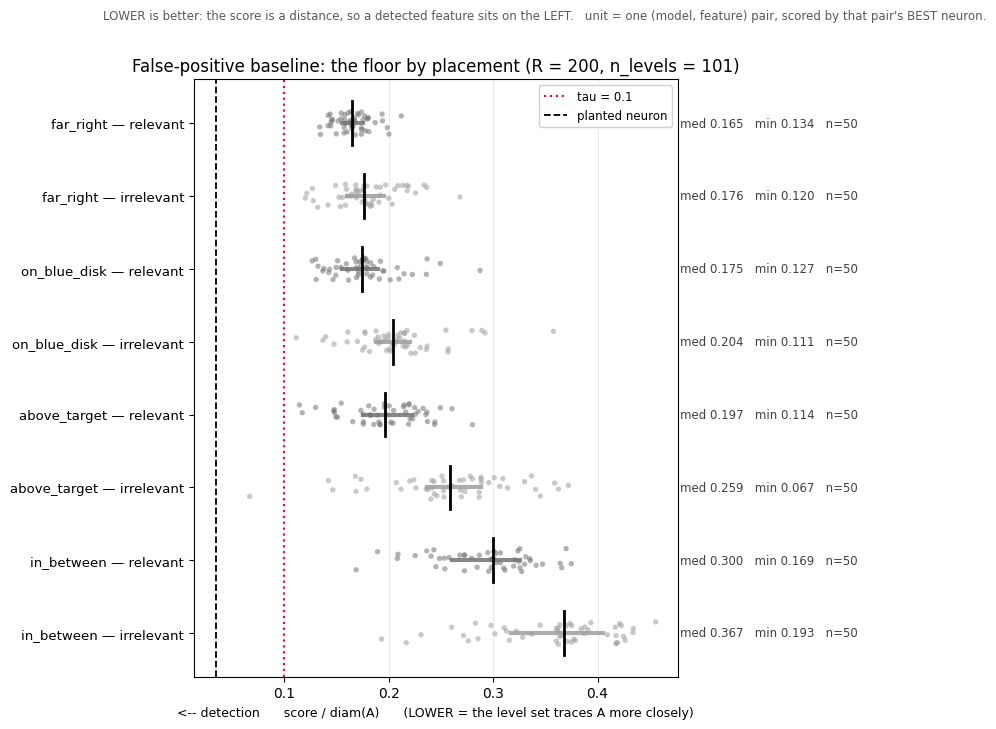

median     q25     q75     min  units
feature           dataset                                          
null_above_target irrelevant  0.2590  0.2363  0.2886  0.0667     50
                  relevant    0.1968  0.1756  0.2222  0.1144     50
null_far_right    irrelevant  0.1764  0.1598  0.1957  0.1201     50
                  relevant    0.1650  0.1551  0.1749  0.1339     50
null_in_between   irrelevant  0.3675  0.3172  0.4055  0.1930     50
                  relevant    0.2997  0.2603  0.3253  0.1688     50
null_on_blue_disk irrelevant  0.2044  0.1876  0.2205  0.1113     50
                  relevant    0.1748  0.1555  0.1896  0.1266     50

units below tau: 1 of 400   |   neurons below tau: 1 of 10000
width of the floor (max−min over the eight cells): 0.2025


In [28]:
# ── The frozen configuration: from here on everything is computed ONLY with it ─
#     R = 200, n_levels = 101 — the choice made in the sections above. The
#     sweeps have already answered the question "does the answer depend on the
#     parameters"; sections 4-7 answer the question "what is the answer" with
#     the detector that goes on to the next experiments. The stability of each
#     statement is given in one line in its conclusion, systematically in
#     section 8.
from visualization.calibration_plots import plot_populations, plot_unit_strips

if "ens" not in globals():
    ens = cal.read_scores_csv(SWEEP_CSV)
if "df_A" not in globals():
    df_A = cal.read_scores_csv(PLANTED_CSV)

FROZEN     = ens[ens.resolution == REFERENCE_RES]
PLANTED_200 = df_A[df_A.resolution == REFERENCE_RES]
PLANTED_AT = float(PLANTED_200[PLANTED_200.criterion == "structural"].score.iloc[0])
CONTRAST   = cal.sweep_contrast(FROZEN[FROZEN.criterion == "structural"],
                                by=("criterion", "dataset"), threshold=TAU)
CONTRAST_H = cal.sweep_contrast(FROZEN[FROZEN.criterion == "homological"],
                                by=("criterion", "dataset"))
_units = cal.best_per_unit(FROZEN[FROZEN.criterion == "structural"],
                           lower_is_better=True, unit=("model_path", "feature", "dataset"))

# ── B: the floor is a distribution over placements, not a number ──────────────
_NULLS = ["null_far_right", "null_on_blue_disk", "null_above_target", "null_in_between"]
plot_unit_strips(FROZEN, "structural",
    [(f"{p.replace('null_', '')} — {d}", {"dataset": d, "feature": p},
      "0.45" if d == "relevant" else "0.62")
     for p in _NULLS for d in ("relevant", "irrelevant")],
    threshold=TAU, planted=PLANTED_AT,
    title="False-positive baseline: the floor by placement (R = 200, n_levels = 101)",
    save_path=(FIGDIR / "s4_floor_by_placement.png") if SAVE else None)

_n = _units[_units.role == "null"]
display(_n.groupby(["feature", "dataset"])["best_score"]
        .agg(median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75),
             min="min", units="size").round(4))
_nn = FROZEN[(FROZEN.criterion == "structural") & (FROZEN.role == "null")]
print(f"units below tau: {int((_n.best_score <= TAU).sum())} of {len(_n)}   |   "
      f"neurons below tau: {int((_nn.score <= TAU).sum())} of {len(_nn)}")
print(f"width of the floor (max−min over the eight cells): "
      f"{_n.groupby(['feature','dataset'])['best_score'].median().max() - _n.groupby(['feature','dataset'])['best_score'].median().min():.4f}")


**Conclusion of section 4.** The floor is not a number but a distribution over placements. The eight
cells (4 placements × 2 datasets) give medians from **0.1650** (`far_right`, relevant) to **0.3675**
(`in_between`, irrelevant) — a spread of **0.2025**, i.e. larger than the target's separation from the
floor (`gap` = 0.1509). Hence the reporting rule: the verdict is compared with the **softest** placement
(`gap_vs_softest`), not with the average over the floor.

**The empirical baseline of false positives at τ = 0.1: 1 unit out of 400** (0.25%) and **1 neuron out
of 10,000**. The only firing is `model24 L1n4` on `null_above_target`, 0.0667; the "Sandbox" shows that
this is a closed level curve of elliptical shape in a layer-1 neuron, and explains why it can be there
at all (the Morse lemma: near a non-degenerate maximum the level curves are ellipses; a circle requires
a repeated eigenvalue, and width 5 gives only 2 independent directions out of the 3 needed for isotropy).

Two limitations that must not be forgotten when transferring these numbers:

* **The minimum over the nulls is a quantity of the instrument, not of the network.** For the worst null
  neuron `best_level_eps` exactly equals the cutoff `0.5·range(f)/(n−1)`, and its score falls together
  with it as `n_levels` grows. What is worth transferring are the medians by placement; they are stable.
* **False positives grow with the number of attempts.** ×7.9 levels moved them from 1 to 3 with the
  network unchanged; the same multiple gained through neurons (width, depth) will move them more.

Stability across the sweeps: not a single false positive on the relevant nulls at any R and any
`n_levels`; on the irrelevant nulls 0 at R ≤ 50 and exactly one at R ≥ 100.

## 5. Task irrelevance

Analyse the scores on the task-irrelevant feature of dataset A and compare them with the corresponding null baseline.

**Task:** show that the presence of a geometric feature that the task does not require does not lead to systematic detection compared with the null-features.

---

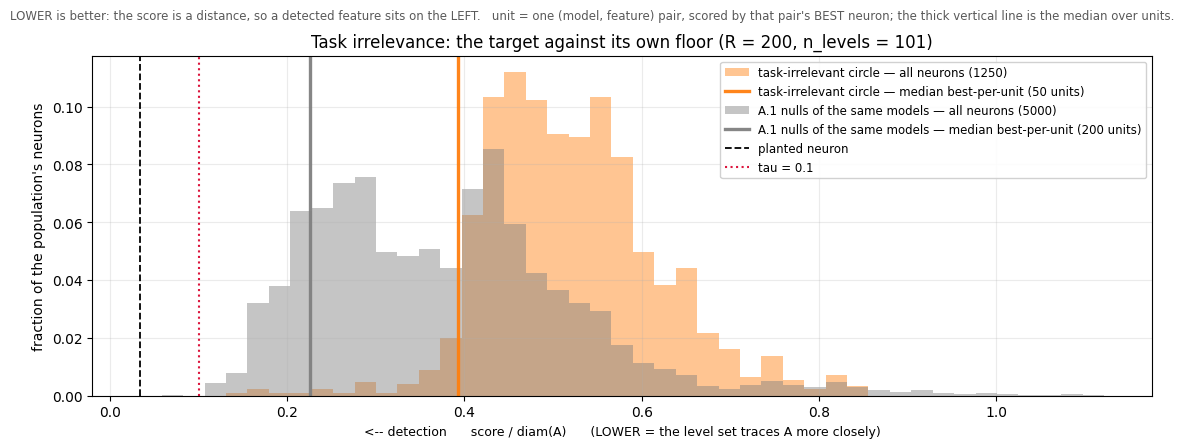

,criterion,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
0,structural,irrelevant,0.3923,0.2259,null_far_right,0.1764,-0.1664,-0.2158,0.1991,0.0,0.005


best neuron in the WHOLE ensemble (1250 neurons): 0.1547 = 1.55 tau
neurons below tau: 0 of 1250


In [29]:
# ── C: the task-irrelevant circle against its own floor ──────────────────────
plot_populations(FROZEN, "structural", [
    ("task-irrelevant circle", {"dataset": "irrelevant", "role": "target"}, "tab:orange"),
    ("A.1 nulls of the same models", {"dataset": "irrelevant", "role": "null"},   "0.5"),
], planted=PLANTED_200, threshold=TAU,
   title="Task irrelevance: the target against its own floor (R = 200, n_levels = 101)",
   save_path=(FIGDIR / "s5_task_irrelevance.png") if SAVE else None)

display(CONTRAST[CONTRAST.dataset == "irrelevant"].round(4))
_i = FROZEN[(FROZEN.criterion == "structural") & (FROZEN.dataset == "irrelevant")
            & (FROZEN.role == "target")]
print(f"best neuron in the WHOLE ensemble (1250 neurons): {_i.score.min():.4f} "
      f"= {_i.score.min()/TAU:.2f} tau")
print(f"neurons below tau: {int((_i.score <= TAU).sum())} of {len(_i)}")


**Conclusion of section 5.** The geometry is present in the data but the task does not need it — and no
systematic detection arises. The median of the best neuron per model is **0.3923** against a floor of
**0.2259**, i.e. `gap` = **−0.1664**: the task-irrelevant circle scores **worse** than its own copy put in
another place. `p_superior` = **0.1991** — a random target unit beats a random null unit in only one case
out of five. Not **a single one** of the 50 models has a witness, and the best neuron in the whole
ensemble of 1250 scores 0.1547 — one and a half times above τ.

It is worth explaining separately **why the chance level here is 0.20 and not 0.50.** If "a target not
needed by the task" were indistinguishable from an arbitrary placement, `p_superior` would be around 0.5.
It is lower, and this agrees with what we found in the section on transferring the nulls: the floor is
determined by **the diversity of level curves** in the neighbourhood, and it is smallest where the task
lives. The target circle stands right in the middle of the data — in the "busiest" region, where the level
curves of all neurons are coherent with one another and with the decision boundary. This is a hard place
for a chance coincidence, harder than three of the four null placements. In other words, 0.20 is not a
weakness of the criterion but a measured property of the place.

The practical consequence: **the chance level must not be taken to be 0.5 "by default"** — it has to be
measured, and here it is measured.

## 6. Task relevance

Analyse the scores on the task-relevant feature of dataset B and compare them with the corresponding null baseline.

**Task:** show that the criterion is able to detect geometry that is genuinely necessary for solving the task.


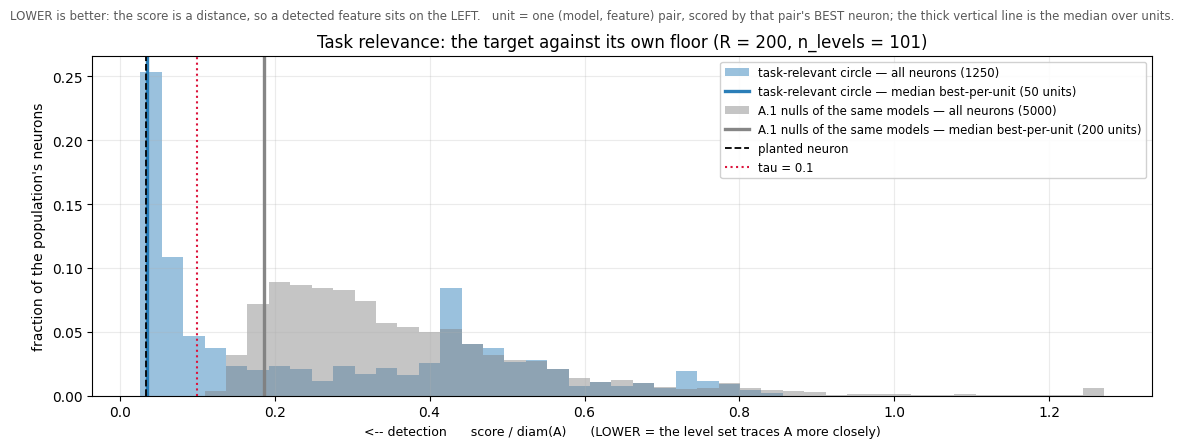

,criterion,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior,target_rate,null_rate
1,structural,relevant,0.0349,0.1858,null_far_right,0.165,0.1509,0.13,0.9995,0.98,0.0


median of the best neuron per model: 0.0349  90% CI [0.0339, 0.0395]   |   planted neuron: 0.0343
fraction of ALL neurons below tau: 0.419
homological criterion, independently:


,criterion,dataset,target_median,null_median,null_softest,null_softest_median,gap,gap_vs_softest,p_superior
1,homological,relevant,1.6273,-0.0416,null_on_blue_disk,-0.0088,1.6689,1.6361,1.0


In [30]:
# ── D: the task-relevant circle against its own floor ────────────────────────
plot_populations(FROZEN, "structural", [
    ("task-relevant circle", {"dataset": "relevant", "role": "target"}, "tab:blue"),
    ("A.1 nulls of the same models",  {"dataset": "relevant", "role": "null"},   "0.5"),
], planted=PLANTED_200, threshold=TAU,
   title="Task relevance: the target against its own floor (R = 200, n_levels = 101)",
   save_path=(FIGDIR / "s6_task_relevance.png") if SAVE else None)

display(CONTRAST[CONTRAST.dataset == "relevant"].round(4))
_t = _units[(_units.dataset == "relevant") & (_units.role == "target")].best_score.to_numpy()
_e, _lo, _hi = cal.bootstrap_over_models(list(_t), lambda xs: float(np.median(xs)))
print(f"median of the best neuron per model: {_e:.4f}  90% CI [{_lo:.4f}, {_hi:.4f}]"
      f"   |   planted neuron: {PLANTED_AT:.4f}")
print(f"fraction of ALL neurons below tau: "
      f"{(FROZEN[(FROZEN.criterion=='structural') & (FROZEN.dataset=='relevant') & (FROZEN.role=='target')].score <= TAU).mean():.3f}")
print("homological criterion, independently:")
display(CONTRAST_H[CONTRAST_H.dataset == "relevant"].round(4))


**Conclusion of section 6.** The median of the best neuron per model is **0.0349** (90% CI 0.0339–0.0395)
with the planted neuron at **0.0343**. This coincidence is not accidental, and it is worth spelling out:
the planted neuron is built so that its true geometric error is ≈ 0, so its score is **the instrument's
ceiling** at the given resolution. The task-relevant circle is detected as well as the instrument is able
to detect anything at all; not even an ideal witness would rise above this ceiling.

The separation from its own floor: `gap` = **+0.1509**, `gap_vs_softest` = **+0.1300** (against
`far_right`, the softest placement), `p_superior` = **0.9995**. **49 of 50** models have a witness.
**41.9% of all** neurons of the ensemble lie below τ, not only the best ones — i.e. this is a property of
the population, not of one lucky neuron per model.

The only model without a witness is `model21` (0.1304). It is examined in the "Sandbox": at 100% accuracy
its decision boundary and deep level curves are **a rounded square**, topologically correct and
geometrically off the mark.

**The homological criterion confirms this independently and more sharply:** the median best margin is
**1.6273** against a floor of **−0.0416**, `p_superior` = **1.0000**, and a bar of the required dimension
was found for **all 50** units against 84% on the nulls. This is a different instrument — it looks at
contrast, not at geometry — and it gives the same answer.

## 7. Selectivity

Compare the scores on the task-relevant feature of dataset B and the task-irrelevant feature of dataset A.

**Task:** show that the criterion responds specifically to task relevance, and not simply to the presence or the geometric shape of a circle.


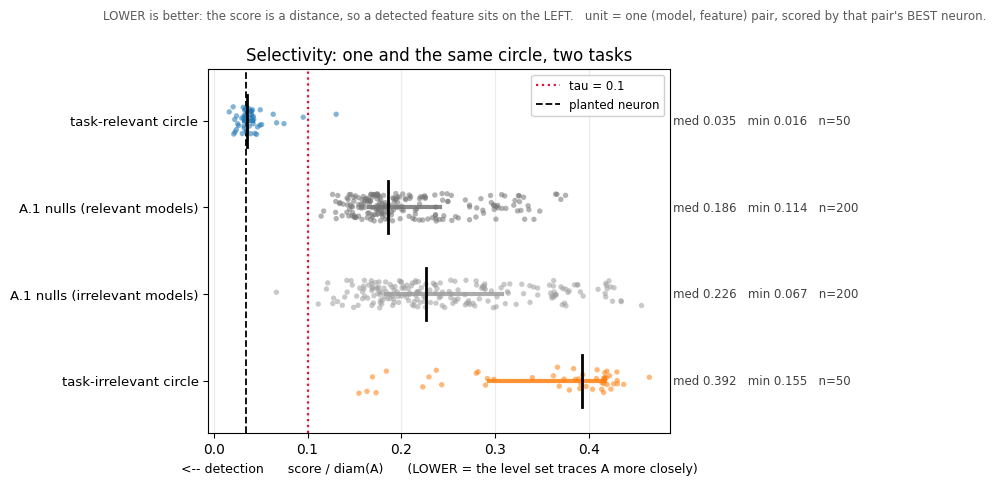

relevant  : median 0.0349  worst unit 0.1304  passed tau 49/50
irrelevant: median 0.3923  best unit 0.1547  passed tau 0/50
p_superior(relevant over irrelevant) = 1.0000   margin between the worst relevant and the best irrelevant = +0.0243
  fraction of models with a witness, relevant  : 0.980  90% CI [0.940, 1.000]
  fraction of models with a witness, irrelevant: 0.000  90% CI [0.000, 0.000]


In [31]:
# ── E: the same circle, two tasks ─────────────────────────────────────────────
#     The only picture that contains the whole experiment: four populations at
#     the frozen configuration, each point is one (model, feature) pair, i.e.
#     the best neuron of that pair.
plot_unit_strips(FROZEN, "structural", [
    ("task-relevant circle",   {"dataset": "relevant",   "role": "target"}, "tab:blue"),
    ("A.1 nulls (relevant models)", {"dataset": "relevant",   "role": "null"},   "0.45"),
    ("A.1 nulls (irrelevant models)", {"dataset": "irrelevant", "role": "null"}, "0.62"),
    ("task-irrelevant circle", {"dataset": "irrelevant", "role": "target"}, "tab:orange"),
], threshold=TAU, planted=PLANTED_AT,
   title="Selectivity: one and the same circle, two tasks",
   save_path=(FIGDIR / "s7_selectivity_strips.png") if SAVE else None)

_rel = _units[(_units.dataset == "relevant")   & (_units.role == "target")].best_score.to_numpy()
_irr = _units[(_units.dataset == "irrelevant") & (_units.role == "target")].best_score.to_numpy()

print(f"relevant  : median {np.median(_rel):.4f}  worst unit {_rel.max():.4f}  "
      f"passed tau {int((_rel <= TAU).sum())}/50")
print(f"irrelevant: median {np.median(_irr):.4f}  best unit {_irr.min():.4f}  "
      f"passed tau {int((_irr <= TAU).sum())}/50")
print(f"p_superior(relevant over irrelevant) = "
      f"{cal.superiority_probability(_rel, _irr):.4f}   "
      f"margin between the worst relevant and the best irrelevant = {_irr.min() - _rel.max():+.4f}")
for _name, _v in [("relevant", _rel), ("irrelevant", _irr)]:
    _e, _lo, _hi = cal.bootstrap_over_models(
        list(_v), lambda xs: float(np.mean([x <= TAU for x in xs])))
    print(f"  fraction of models with a witness, {_name:10s}: {_e:.3f}  90% CI [{_lo:.3f}, {_hi:.3f}]")


**Conclusion of section 7.** The circle is bitwise the same in the two datasets — the same 500 points, the
same radius, the same place. The only difference is whether the task needs it.

| | task-relevant | task-irrelevant |
|---|---|---|
| median of the best neuron per model | **0.0349** | **0.3923** |
| models with a witness at τ = 0.1 | **49 / 50** (90% CI 0.94–1.00) | **0 / 50** (CI 0.00–0.00) |
| worst / best unit | 0.1304 | 0.1547 |

**The separation is complete.** `p_superior = 1.0000`: the worst relevant model (0.1304) is better than
the best irrelevant model (0.1547), with a margin of **+0.0243**. Not one of the 2,500 pairs overlaps —
this is not "a statistically significant difference" but two disjoint sets.

Importantly, **the floors of the two ensembles are close** — 0.1858 against 0.2259. That is, the relevant
networks are not "richer in level curves in general": they catch a random circle off to the side about
as poorly as the irrelevant networks do. Exactly one place differs — the one where the circle is needed
to solve the task.

This is the main scientific result of the notebook: **the criterion responds to task relevance, not to
the presence of geometry.**


## 8. Numerical stability and frozen methodological specification

Summarise the results of all the previous sections and determine the region of stability in `resolution`, `n_levels` and `level_eps`.

Check that as the hyperparameters change:
- the scores do not change substantially beyond a numerical tolerance set in advance;
- the conclusions about the null, task-irrelevant and task-relevant features are preserved;
- their qualitative relationship is preserved.

Choose a working configuration from the region of stability and freeze it as the `DetectorSpec` for all subsequent experiments.



In [ ]:
# ── F: do the conclusions of sections 4-7 hold at ALL points of both sweeps ───
#     Sections 4-7 reported at a single configuration. Here we check that the
#     choice of that configuration decided nothing: each statement is checked
#     at all five resolutions and all six values of n_levels.
if "nl" not in globals():
    nl = cal.read_scores_csv(NL_SWEEP_CSV)

def stability_grid(scores, axis, threshold=TAU):
    """One row per point of the sweep: all reported quantities at once."""
    s = scores[scores.criterion == "structural"]
    con = cal.sweep_contrast(s, by=("criterion", axis, "dataset"), threshold=threshold)
    sel = cal.selectivity(s, by=(axis,), threshold=threshold)
    rel = con[con.dataset == "relevant"].set_index(axis)
    irr = con[con.dataset == "irrelevant"].set_index(axis)
    return pd.DataFrame({
        "relevant rate":        rel.target_rate,
        "irrelevant rate":      irr.target_rate,
        "false pos. on nulls rel": rel.null_rate,
        "false pos. on nulls irr": irr.null_rate,
        "p_sup relevant":       rel.p_superior,
        "p_sup irrelevant":     irr.p_superior,
        "gap relevant":         rel.gap,
        "gap irrelevant":       irr.gap,
        "p_sup selectivity":    sel.set_index(axis).p_superior,
        "margin selectivity":   sel.set_index(axis).margin,
        "softest placement":    rel.null_softest.str.replace("null_", "", regex=False),
    })

GRID_RES = stability_grid(ens, "resolution")
GRID_NL  = stability_grid(nl,  "n_levels")
print("over resolution (n_levels = 101):"); display(GRID_RES.round(4))
print("over n_levels (R = 200):");          display(GRID_NL.round(4))

_all = pd.concat([GRID_RES, GRID_NL])
print(f"configurations checked: {len(_all)}")
print(f"  irrelevant rate  : always {sorted(_all['irrelevant rate'].unique())}")
print(f"  false pos. on nulls relevant: always {sorted(_all['false pos. on nulls rel'].unique())}")
print(f"  relevant rate    : from {_all['relevant rate'].min():.2f} to {_all['relevant rate'].max():.2f}")
print(f"  p_sup relevant   : from {_all['p_sup relevant'].min():.4f} to {_all['p_sup relevant'].max():.4f}")
print(f"  gap relevant > 0 : {(_all['gap relevant'] > 0).all()}   |   "
      f"gap irrelevant < 0: {(_all['gap irrelevant'] < 0).all()}")
print(f"  complete separation (p_sup selectivity = 1): "
      f"{int((_all['p_sup selectivity'] >= 1.0).sum())} of {len(_all)} configurations")


**Conclusion of section 8: the choice of configuration decided nothing.**

Eleven rows — five resolutions at `n_levels = 101` and six values of `n_levels` at R = 200, of which the
working point (R = 200, `n_levels` = 101) is shared, i.e. **ten distinct configurations**. In each of them
all the reported quantities of sections 4–7 were checked.

| | over resolution 25→400 | over n_levels 6→401 |
|---|---|---|
| fraction of relevant models with a witness | 0.86 → 0.98 | 0.92 → 0.98 |
| **fraction of irrelevant models** | **0.00 everywhere** | **0.00 everywhere** |
| false positives on the relevant nulls | **0 everywhere** | **0 everywhere** |
| false positives on the irrelevant nulls | 0 … 0.005 | 0 … 0.015 |
| `p_superior` relevant | 0.9835 → 0.9995 | 0.9907 → 0.9993 |
| `p_superior` irrelevant | 0.186 … 0.209 | 0.194 … 0.201 |
| `gap` relevant | always **> 0** | always **> 0** |
| `gap` irrelevant | always **< 0** | always **< 0** |

**Not a single exception in any configuration.** Zero false witnesses on the task-irrelevant circle is
500 (model, configuration) pairs in a row. The sign of `gap` changes nowhere: the target is always better
than its floor on relevant and always worse than it on irrelevant.

**Complete separation is a stronger statement, and it requires a minimum resolution.** `p_superior`
between the two targets equals **1.0000** in eight rows of eleven; three fall short: R = 25 (margin
−0.0870), R = 50 (−0.0024, i.e. the populations just touch) and `n_levels` = 6 (−0.0418). In other words,
**the separation is complete at R ≥ 100 and `n_levels` ≥ 26**, while below that the populations overlap —
by two models at R = 25 and literally by one point at R = 50. Importantly, even where there is overlap,
all the other statements hold: the irrelevant fraction is still 0.00, the signs of `gap` are the same,
`p_superior` relevant is 0.98+.

The softest placement of the floor is `far_right` in nine configurations out of ten (`on_blue_disk` at
the two edges of the grid, R = 25 and `n_levels` = 401).

**What does depend on the parameters** — and this is exactly what sections 2 and 4 warned about: the
absolute level of the floor (`gap` relevant wanders 0.132…0.192), the number of false positives on the
nulls (0…3 of 200) and the absolute level of the score. Nothing of what we report depends on them: not a
single sign, not a single ordering, not a single verdict.

### The frozen methodological specification

```python
# structural criterion
resolution   = 200          # or, for a different scale: N_A = diam(A)/max(h) ≈ 40, one number per axis
n_levels     = 101          # default of structural_criterion
levels       = linspace(min f, max f, n_levels)    # activation=None: observed range
level_eps    = "adaptive"   # with the lower cutoff 0.5·range(f)/(n_levels − 1)
threshold τ  = 0.1          # score / diam(A)
kind         = "pre"        # project convention

# homological criterion
backend           = "delaunay"
max_sample_points = 7000    # > the number of grid points in the window; for a different N_A recompute as ≈ 1.8·N_A²

# reporting protocol
unit of observation = a (model, feature) pair, its value is the pair's best neuron
floor               = the distribution over the A.1 placements; the verdict is compared with the softest one
nulls               = at least two placements in different directions from the target, both far from the decision boundary
```

The specification is checked by machine: `cal.check_conventions(SPEC.eval)` compares it with what is
actually set in `EXPERIMENTS["exp1_sanity_check"]`, and fails if they have diverged.

## 9. Summary

A summary table over the criteria and the chosen configuration of hyperparameters.

To be frozen:
- the working values of `resolution`, `n_levels`, `level_eps`;
- evidence for detector validity;
- false-positive baseline;
- the results for the task-irrelevant and task-relevant features;
- the final conclusion on selectivity.

**After this the `DetectorSpec` is considered frozen and is not changed in subsequent experiments.**

In [ ]:
# ── Summary: one row per statement ──────────────────────────────────────────
_rows = []
for _ds, _label in [("relevant", "task-relevant"), ("irrelevant", "task-irrelevant")]:
    _c = CONTRAST[CONTRAST.dataset == _ds].iloc[0]
    _t = _units[(_units.dataset == _ds) & (_units.role == "target")].best_score
    _rows.append({
        "dataset": _label,
        "target median": _c.target_median,
        "floor median": _c.null_median,
        "gap": _c.gap,
        "gap vs softest": _c.gap_vs_softest,
        "p_superior": _c.p_superior,
        "models with a witness": f"{int((_t <= TAU).sum())}/50",
        "best unit": _t.min(),
        "worst unit": _t.max(),
    })
display(pd.DataFrame(_rows).round(4))

_sel = cal.selectivity(FROZEN[FROZEN.criterion == "structural"], threshold=TAU).iloc[0]
print(f"selectivity: p_superior = {_sel.p_superior:.4f}, "
      f"margin between the populations = {_sel.margin:+.4f} "
      f"({'disjoint' if _sel.margin > 0 else 'overlapping'})")
print(f"planted neuron (the instrument's ceiling) = {PLANTED_AT:.4f} "
      f"at a true error of {float(PLANTED_200[PLANTED_200.criterion=='structural'].ideal_score.iloc[0]):.4f}")
print()
display(cal.conventions_table())
display(cal.check_conventions(SPEC.eval))


### Outcome of the calibration

**What has been established.** One and the same circle — the same 500 points, the same radius, the same
place — is detected in **49 of 50** models when the task needs it, and in **0 of 50** when it does not.
The populations do not overlap: `p_superior = 1.0000`, the margin between the worst relevant model and
the best irrelevant model is **+0.0243**. False positives on the A.1 nulls: **1 unit out of 400**. All
of this is stable across all ten tested configurations (section 8).

**Three anchors of the scale, each measured rather than assigned:**

| rung | what it is | value |
|---|---|---|
| known witness (not a ceiling, see the correction in section A) | planted neuron, true error 0.0016 | **0.0343** |
| threshold | τ, assigned in advance | **0.1** |
| floor | A.1 nulls, median by placement | **0.165 … 0.368** |

The median of the task-relevant target (**0.0349**) coincides with the value on the known witness; the
median of the task-irrelevant target (**0.3923**) lies beyond the floor, i.e. it is **worse** than a copy
of the same circle put in a random place.

**What the calibration does NOT give.**

* It is not about the size of the effect or about what influences it: the verdict is binary, "the
  feature is there or not". The dependence of the score on geometry is the subject of a separate
  experiment (a draft lies in the sandbox).
* The floor **does not transfer** to another task, another architecture, another feature shape or
  another multiplicity. It has to be measured anew in every experiment; what transfers is the
  construction of the set of nulls, not its numbers.
* The chance level here is **0.20, not 0.50** — this is a property of the place where the target
  stands, and it too has to be measured, not assumed.
* The threshold applies only where the instrument passes its own check: at `N_A < 6` the planted neuron
  does not pass τ, and a negative answer from the criterion means nothing there.

### What carries over to the next experiments

**1. Not `resolution = 200` but `N_A ≈ 40`.** Two hundred is the number for this box and this circle; it
does not transfer anywhere: with a different box or a different feature size the same two hundred points
mean a different discretisation. What transfers is the dimensionless quantity — **how many grid steps fit
into the feature's diameter**, `N_A = diam(A) / max(h_x, h_y)`. The whole sweep reads off it: at
`N_A ≈ 22` the ordinal verdict is already stable, at `N_A ≈ 44` the counting one is stable too, at
`N_A ≈ 89` nothing changes, and at `N_A < 6` the planted neuron does not pass its own threshold and any
negative answer is meaningless. The working point is 40, and it has to be computed **as one number per
axis**, otherwise one axis ends up overpaid (our box is elongated 1.8 times, and along `y` we compute 1.8
extra points for every useful one):

```python
h = diam(A) / 40
resolution = tuple(int(np.ceil((b - a) / h)) + 1 for a, b in BOUNDS)
```

Along with this, `max_sample_points` of the homological criterion is recomputed for the scale: the number
of grid points in its window is roughly `1.8·N_A²`, i.e. ≈ 2,800 at `N_A = 40`; our 7,000 cover this with
a margin, but at a substantially larger `N_A` the value has to be raised. Everything else in the
specification is dimensionless and transfers as it is: τ (it is a fraction of `diam(A)`), `n_levels` (a
fraction of the neuron's own range), adaptive ε (it scales with the grid by itself),
`neighborhood_factor` (given in feature radii).

**2. The minimal set of nulls is two placements, but not just any two.** The floor depends not on the
distance to the data but on the **direction**: `far_right` and `above_target` stand at one and the same
distance of 3.5 from the target's centre and differ by 47%. Therefore both placements are taken **far from
the decision boundary** (there the diversity of the level curves is largest and the floor is softest — and
it is this floor that binds the verdict) and in **two different directions from the target**: along the
task axis and across it. The second is not a duplicate but a check that the soft direction has been
found. A third placement, in the corridor by the decision boundary, is needed only if one reports the
width of the floor: it gives the hard end and never binds the verdict. Each placement goes through the
admissibility check `field_grad_norm_on_feature` — in a dead region one gets not a soft floor but the
absence of a measurement. And an alarm signal: if two placements gave a floor that coincides to within a
few percent, they most likely fell into one regime, and there is no coverage — a third one is needed.

**3. The comparison protocol.** The fraction of witnesses at width W may only be compared with a floor
measured **at the same width** (the floor falls with the number of attempts as ≈ `N^(−0.28)`, and the
growth of the fraction of witnesses with width is partly reproduced by the floor). The unit of observation
is a (model, feature) pair, and its value is the best neuron of the pair. The verdict is compared with the
softest placement, not with the average over the floor.

---
## Sandbox

Examination of individual models by hand. Nothing from here goes into the report — this is the place
where one looks with one's own eyes at what the tables showed as numbers.

In [32]:
# ── Which relevant models do NOT pass tau? We look this up in the table already
#     computed rather than typing the path in by hand — otherwise it goes stale
#     when the sweep is re-run.
SANDBOX_RES = 200

_best = cal.best_per_unit(ens[ens.criterion == "structural"], lower_is_better=True,
                          unit=("model_path", "feature", "resolution", "dataset"))
miss = (_best[(_best.dataset == "relevant") & (_best.role == "target")
              & (_best.resolution == SANDBOX_RES) & (_best.best_score > TAU)]
        .sort_values("best_score", ascending=False))
display(miss[["model_path", "best_score"]])
assert len(miss), f"at R={SANDBOX_RES} all relevant models passed tau"

BAD = miss.model_path.iloc[0]
print("examining:", BAD)

# What it looks like under both criteria at all resolutions.
_m = ens[(ens.model_path == BAD) & (ens.feature == "relevant")]
_agg = []
for (cname, res), g in _m.groupby(["criterion", "resolution"]):
    sc = g["score"].dropna()
    _agg.append({"criterion": cname, "resolution": res,
                 "best": (sc.min() if cal.DIRECTIONS[cname] else sc.max())
                          if len(sc) else float("nan")})
display(pd.DataFrame(_agg).pivot(index="criterion", columns="resolution",
                                 values="best").round(4))
for cname, lower in (("structural", True), ("homological", False)):
    g = _m[(_m.criterion == cname) & (_m.resolution == SANDBOX_RES)]
    g = g.sort_values("score", ascending=lower).head(5)
    print(f"\n{cname}: 5 best neurons at R={SANDBOX_RES}")
    print(g[["layer_id", "coord_id", "score", "is_witness"]].to_string(index=False))

,model_path,best_score
1820,models/runs/simple_relevant/simple_relevant_0/...,0.1304


examining: models/runs/simple_relevant/simple_relevant_0/simple_relevant_0_tanh_w5_d5_mass-train_model21


resolution,25,50,100,200,400
criterion,,,,,
homological,0.4323,0.4712,0.4768,0.4766,0.4785
structural,0.2635,0.1746,0.1390,0.1304,0.1308



structural: 5 best neurons at R=200
 layer_id  coord_id    score  is_witness
        3         2 0.130400       False
        3         4 0.133045       False
        3         3 0.142772       False
        4         3 0.181702       False
        4         1 0.188568       False

homological: 5 best neurons at R=200
 layer_id  coord_id     score  is_witness
        4         4  0.476648        True
        4         3  0.419463        True
        1         1 -0.059053       False
        1         2 -0.078725       False
        3         1 -0.117003       False


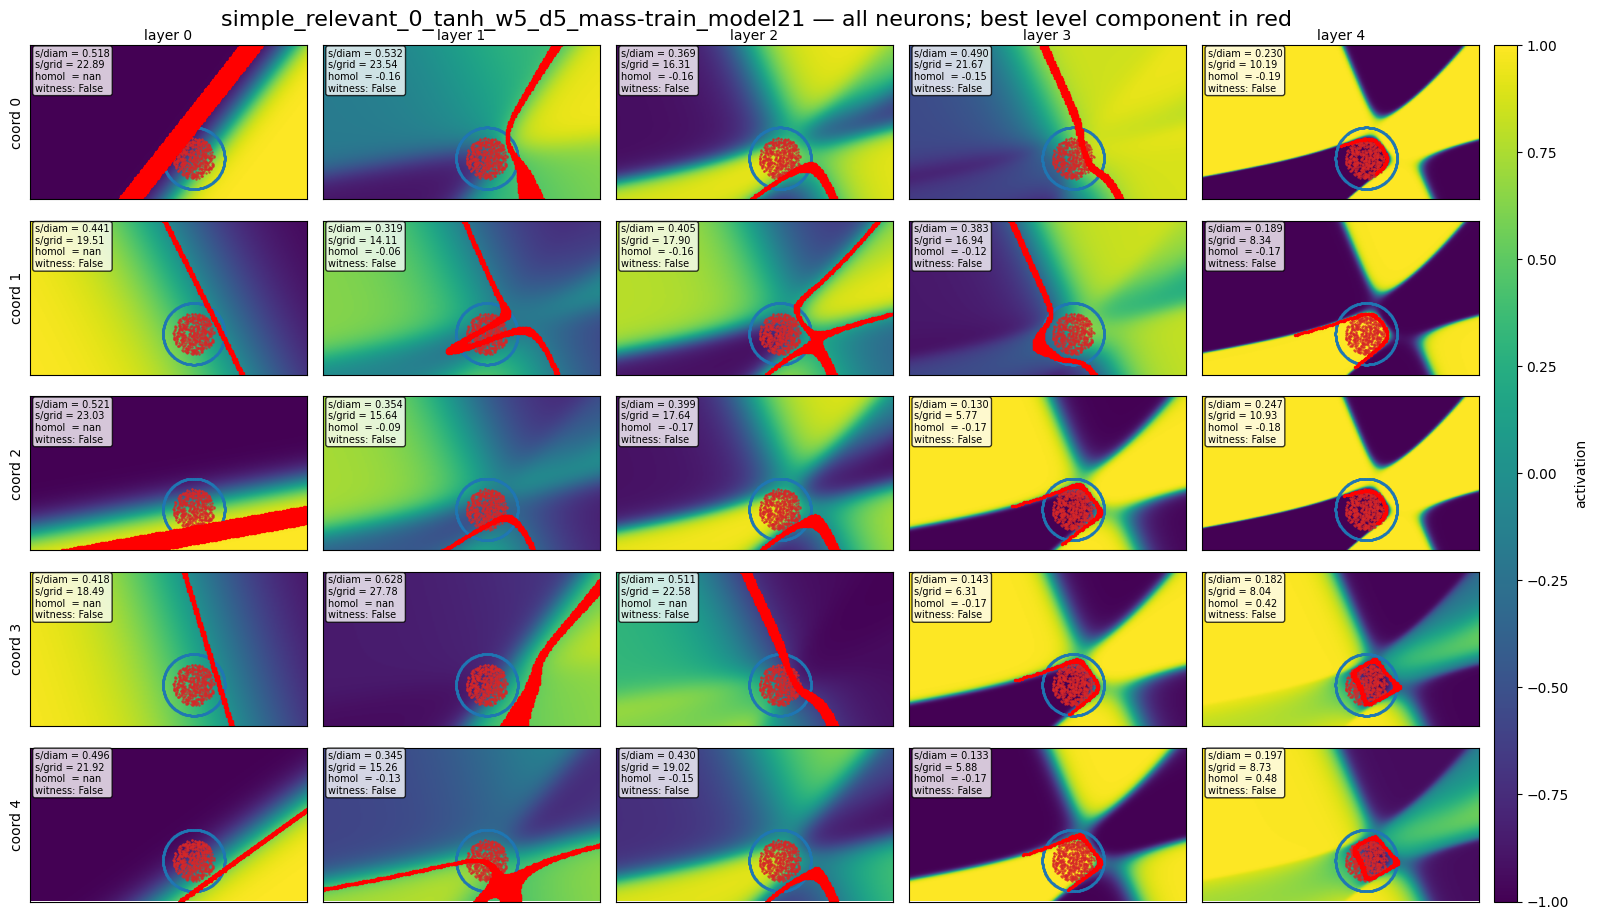

In [33]:
# ── All neurons of this model: field + data + best level component ───────────
#     The same box and the same resolution as in the sweep, otherwise the
#     picture explains a different number from the one in the table.
from analysis.criterions import evaluate_neurons_on_feature
from visualization.plot_point_clouds import plot_all_hidden_neuron_fields_2d_with_criteria
from experiments import runner

bad_model, _ = load_model_instance(BAD)
d_rel = load_dataset_instance("data/dataset_instances/simple_relevant/simple_relevant_0/",
                              reconstruct_data=False)

rows_bad = evaluate_neurons_on_feature(
    model=bad_model,
    feature_points=FEATURES["relevant"]["relevant"],
    bounds=BOUNDS,
    resolution=SANDBOX_RES,
    kinds=SPEC.eval.kinds,
    structural_kwargs={**SPEC.eval.structural_kwargs,
                       "return_best_component_points": True},
    run_structural=True,
    run_tubular=False,
    extra_criteria=runner._resolve_extra_criteria(SPEC.eval) or None,
    return_full_result_structural=True,
    verbose=False,
)

_ = plot_all_hidden_neuron_fields_2d_with_criteria(
    bad_model, rows_bad, BOUNDS,
    X=d_rel["X"], y=d_rel["y"],
    kind=SPEC.eval.kinds[0],
    resolution=SANDBOX_RES,
    title=f"{BAD.split('/')[-1]} — all neurons; best level component in red")

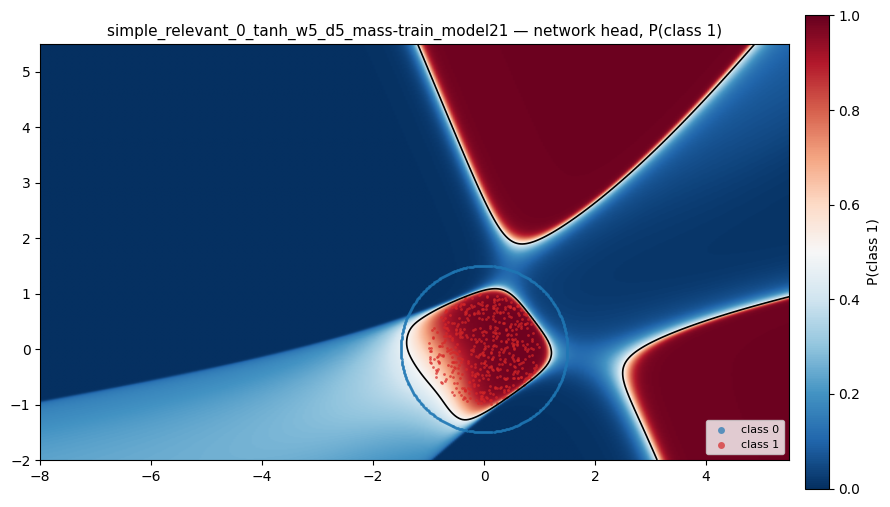

In [34]:
# ── The head of the same network: what the model actually computes ──────────
#     The neurons inherit their shape from it, so looking at them apart from
#     the head makes no sense. The decision boundary here is a rounded square,
#     and exactly this shape is repeated by the level sets in layers 3-4.
from visualization.plot_point_clouds import plot_decision_boundary_2d

_ = plot_decision_boundary_2d(
    bad_model, BOUNDS, X=d_rel["X"], y=d_rel["y"], resolution=400,
    title=f"{BAD.split('/')[-1]} — network head, P(class 1)")

reference: models/runs/simple_relevant/simple_relevant_0/simple_relevant_0_tanh_w5_d5_mass-train_model18


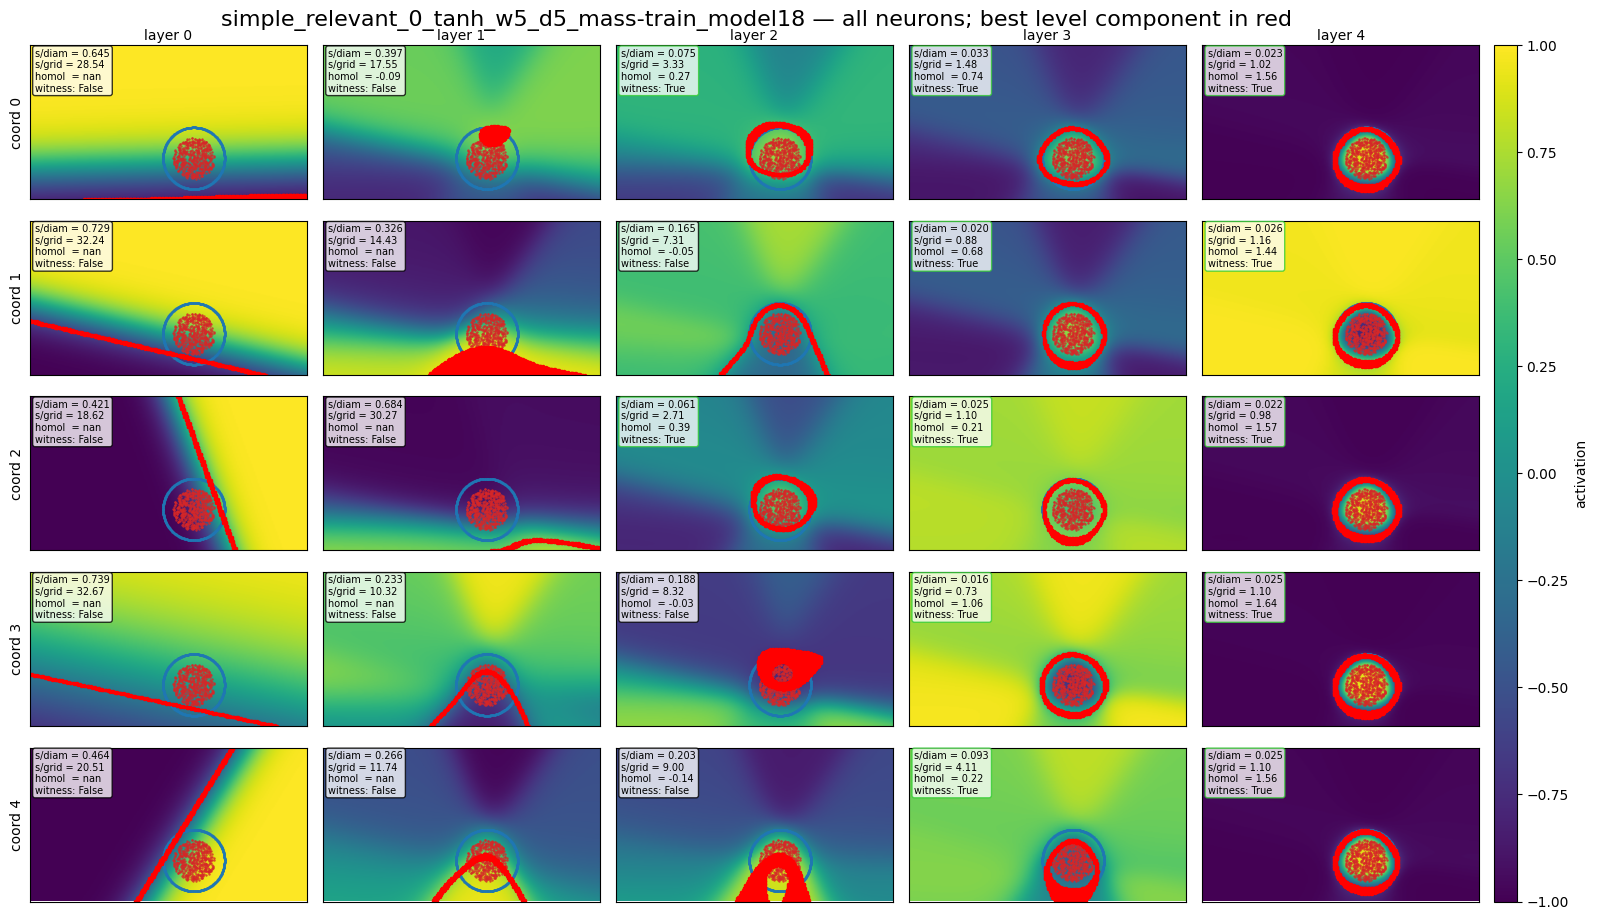

In [35]:
# ── For comparison: the best relevant model, seen the same way ───────────────
GOOD = (_best[(_best.dataset == "relevant") & (_best.role == "target")
              & (_best.resolution == SANDBOX_RES)]
        .sort_values("best_score").model_path.iloc[0])
print("reference:", GOOD)

good_model, _ = load_model_instance(GOOD)
rows_good = evaluate_neurons_on_feature(
    model=good_model,
    feature_points=FEATURES["relevant"]["relevant"],
    bounds=BOUNDS, resolution=SANDBOX_RES, kinds=SPEC.eval.kinds,
    structural_kwargs={**SPEC.eval.structural_kwargs,
                       "return_best_component_points": True},
    run_structural=True, run_tubular=False,
    extra_criteria=runner._resolve_extra_criteria(SPEC.eval) or None,
    return_full_result_structural=True, verbose=False,
)
_ = plot_all_hidden_neuron_fields_2d_with_criteria(
    good_model, rows_good, BOUNDS, X=d_rel["X"], y=d_rel["y"],
    kind=SPEC.eval.kinds[0], resolution=SANDBOX_RES,
    title=f"{GOOD.split('/')[-1]} — all neurons; best level component in red")

In [36]:
# ── The only false positive: a neuron that caught a NULL ─────────────────────
#     We search the whole table at once, over all resolutions and datasets.
fp = ens[(ens.criterion == "structural") & (ens.role == "null") & (ens.score <= TAU)]
display(fp[["resolution", "dataset", "feature", "model_path", "layer_id", "coord_id",
            "score", "best_level_eps"]].sort_values(["resolution", "score"]))
assert len(fp), "there are no false positives on the nulls"

_r = fp[fp.resolution == SANDBOX_RES].sort_values("score").iloc[0]
FP_MODEL, FP_FEATURE = _r.model_path, _r.feature
FP_L, FP_C = int(_r.layer_id), int(_r.coord_id)
print(f"\n{FP_MODEL}")
print(f"  feature {FP_FEATURE}, neuron L{FP_L}n{FP_C}, score {_r.score:.4f} at tau={TAU}")

,resolution,dataset,feature,model_path,layer_id,coord_id,score,best_level_eps
52200,100,irrelevant,null_above_target,models/runs/simple_irrelevant/simple_irrelevan...,1,4,0.073420,0.006701
77200,200,irrelevant,null_above_target,models/runs/simple_irrelevant/simple_irrelevan...,1,4,0.066721,0.005138
102200,400,irrelevant,null_above_target,models/runs/simple_irrelevant/simple_irrelevan...,1,4,0.067337,0.005138



models/runs/simple_irrelevant/simple_irrelevant_0/simple_irrelevant_0_tanh_w5_d5_mass-train_model24
  feature null_above_target, neuron L1n4, score 0.0667 at tau=0.1


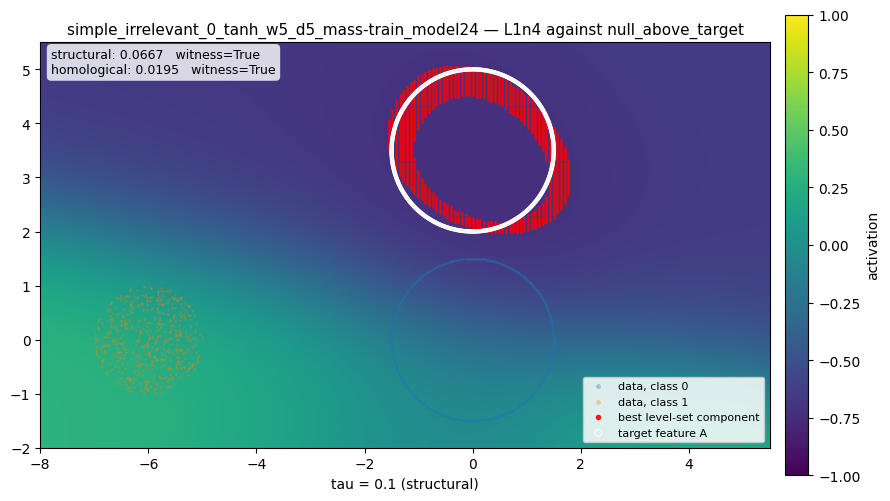

In [37]:
# ── That very neuron, close up ───────────────────────────────────────────────
#     In white is the null feature itself. A null is a rigid copy of the target
#     put in another place; it is not in the data, so without the white circle
#     the picture cannot be read.
fp_model, _ = load_model_instance(FP_MODEL)
fp_probe = cal.trained_probe(fp_model, FP_L, FP_C, FEATURES["irrelevant"][FP_FEATURE])

_ = plot_probe_field(
    fp_probe, BOUNDS, SANDBOX_RES, criteria_specs=CRITS, threshold=TAU,
    X=DATA["irrelevant"]["X"], y=DATA["irrelevant"]["y"],
    title=f"{FP_MODEL.split('/')[-1]} — L{FP_L}n{FP_C} against {FP_FEATURE}")

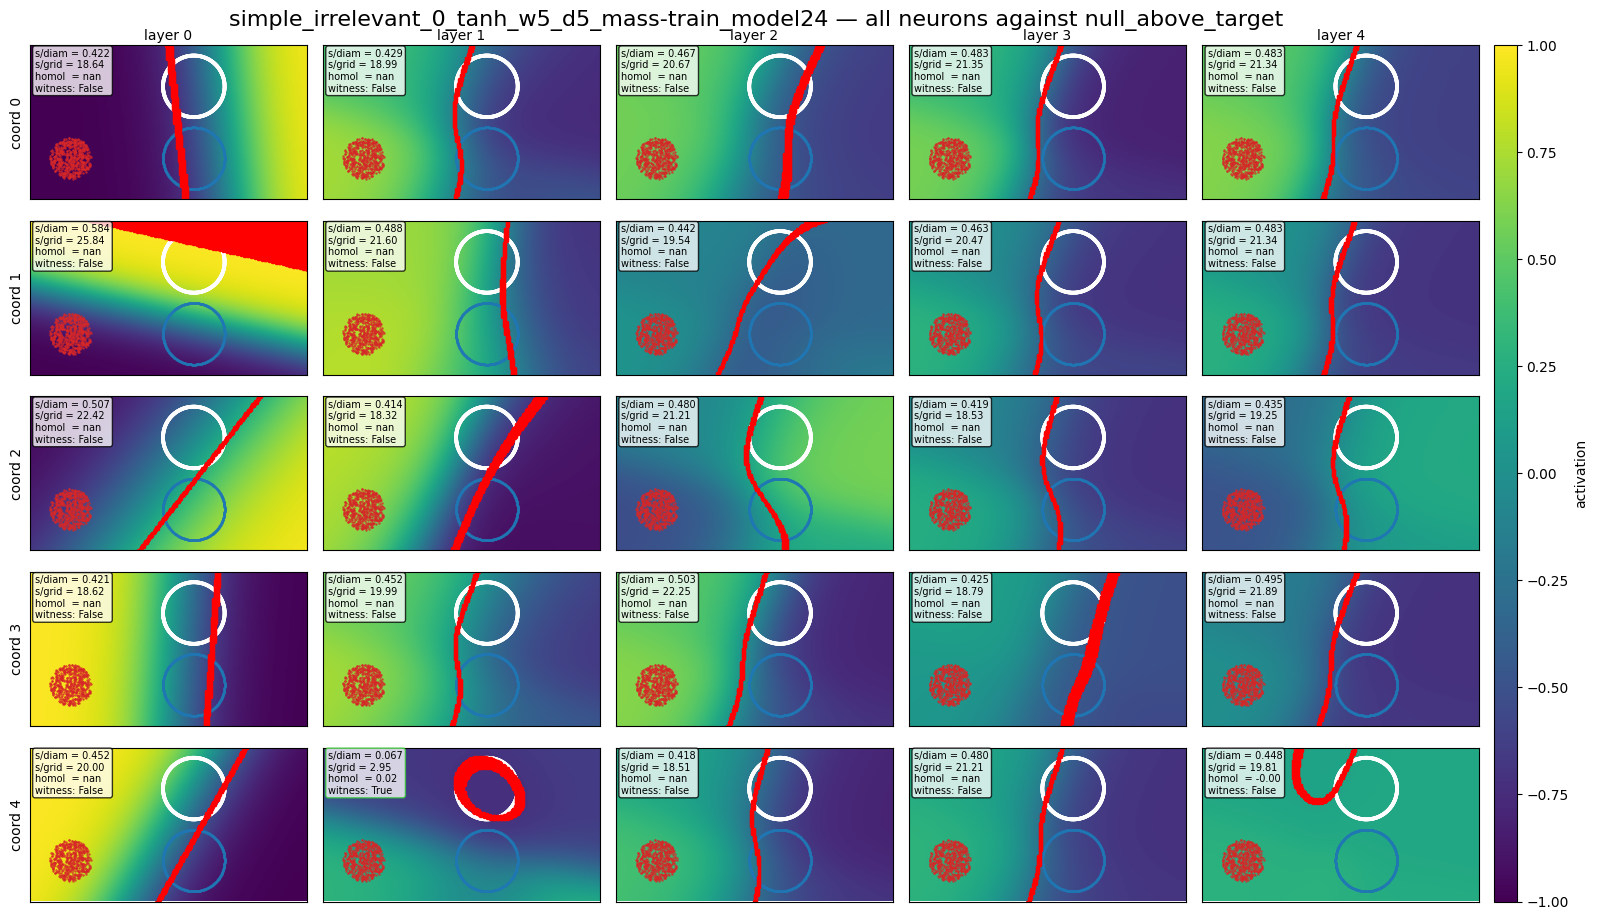

In [38]:
# ── All neurons of the same model against the same null ──────────────────────
rows_fp = evaluate_neurons_on_feature(
    model=fp_model,
    feature_points=FEATURES["irrelevant"][FP_FEATURE],
    bounds=BOUNDS,
    resolution=SANDBOX_RES,
    kinds=SPEC.eval.kinds,
    structural_kwargs={**SPEC.eval.structural_kwargs,
                       "return_best_component_points": True},
    run_structural=True,
    run_tubular=False,
    extra_criteria=runner._resolve_extra_criteria(SPEC.eval) or None,
    return_full_result_structural=True,
    verbose=False,
)

_ = plot_all_hidden_neuron_fields_2d_with_criteria(
    fp_model, rows_fp, BOUNDS,
    X=DATA["irrelevant"]["X"], y=DATA["irrelevant"]["y"],
    feature_points=FEATURES["irrelevant"][FP_FEATURE],
    kind=SPEC.eval.kinds[0], resolution=SANDBOX_RES,
    title=f"{FP_MODEL.split('/')[-1]} — all neurons against {FP_FEATURE}")

#### Where a closed level curve comes from in a layer-1 neuron at all

A fair question: a **layer-0** neuron cannot have closed level curves in principle. It equals
$\tanh(a\cdot x+b)$, is constant on the lines $a\cdot x=\text{const}$, and its level sets are parallel
straight lines.

A **layer-1** neuron is built differently:

$$f(x)=\tanh\big(g(x)\big),\qquad g(x)=\sum_{i=1}^{5} w_i\,\tanh(a_i\cdot x+b_i)+b .$$

Since $\tanh$ is strictly monotonic, the level sets of $f$ are exactly the level sets of $g$. So the
question reduces to whether **a sum of five ridge functions** can have a closed level curve. It can, and
for two independent reasons.

**Constructively.** A pair of $\tanh$ with opposite signs along one direction $u$ gives a "strip":
$\tanh\!\big(s(u\cdot x+\delta)\big)-\tanh\!\big(s(u\cdot x-\delta)\big)$ — high inside a strip of width
$2\delta$, low outside. Two such pairs along two independent directions give a function that is high
only in the intersection of the strips, i.e. a bump with closed level curves shaped like a rounded
parallelogram. This takes 4 layer-0 neurons; at width 5 one is left in reserve. This is exactly the
construction of `plant_radial_neuron` (`src/analysis/controls.py:302`), where the number of directions is
$k=3$ when `hidden_dim >= 6` and $k=2$ otherwise.

**Theoretically — and this is a stronger statement.** The Hessian:

$$\nabla^2 g(x)=\sum_i w_i\,\tanh''(a_i\cdot x+b_i)\,a_i a_i^{\mathsf T},
\qquad \tanh''(z)=-2\tanh(z)\,\mathrm{sech}^2(z).$$

Each term is a signed rank-1 matrix. A sum of such matrices may well be negative definite: two terms with
linearly independent $a_i$ and suitable signs suffice. So $g$ can have a non-degenerate local maximum
$x^{*}$. And by the Morse lemma, near a non-degenerate critical point

$$g(x)\approx g(x^{*})+\tfrac12 (x-x^{*})^{\mathsf T} H\,(x-x^{*}),$$

and the level sets in the neighbourhood are **ellipses** with axes along the eigenvectors of $H$. A
circle arises only if $H$ has a repeated eigenvalue, and that is a codimension-2 condition: a trained
network never satisfies it.

The right answer is therefore this: **a closed level curve in a layer-1 neuron is not merely possible — it
is typical, and its typical shape is precisely an ellipse, not a circle.** Circles are not to be expected
here at all: at width 5 layer 0 can provide at most 2 independent directions for the bump, while isotropy
in this construction needs 3 — only then do the harmonics $\cos 2\theta$ and $\cos 4\theta$ cancel and the
level curves become circles up to 6th order.

**Why the criterion fired, then.** The score is the max-symmetrised mean Chamfer distance between the
component and the feature's points, divided by $\mathrm{diam}(A)\approx 3.0$. The value 0.0667
corresponds to a raw distance of about 0.20 at a circle radius of 1.5. An ellipse whose semi-axes differ
by some ten percent already falls into this range — and part of this distance is eaten up by the
thickness of the $\varepsilon$-band itself, not by the shape. That is, the firing requires nothing
exotic: a bump of suitable size that happened to sit roughly in the right place is enough.

**And this is not a defect of the criterion.** It reported exactly what is there: this neuron really does
have a level curve that goes around the null's circle with an accuracy of 6.7% of its diameter. It is
precisely to measure the frequency of such coincidences that the A.1 floor is needed — the measured
frequency is 1 per 200 units.

**A side observation from the same picture.** The null lies on a saturated plateau, where the field is
almost constant, and the adaptive $\varepsilon$ there is 0.0051 against 0.0213 for the real target at the
same resolution ($\varepsilon\approx|\nabla f|\cdot h$, and $|\nabla f|$ is small). A thin band in an
almost flat region is exactly the situation where the coupling "levels ↔ $\varepsilon$" becomes
fragile.

---
#### Detection curves — outside the scope of this experiment

This piece is in the sandbox on purpose. It measures **how the score changes under a measured distortion
of the geometry** — that is, the size of the effect and what influences it. The current experiment does
not pose such a question: it only detects whether the feature is there or not, and its verdict is
binary. Studying how the effect depends on geometry is the subject of a separate experiment, and there is
nothing to move from here into section 3.

What is nevertheless useful here and why it is worth keeping: one of the three axes revealed a property
of **the criterion itself**, not of the data — it is invariant to the level at which the feature sits, and
therefore does not constrain the radius at all. This is a limitation of the instrument, and it is worth
remembering when reading any result.

Nothing is recomputed: `sanity_detection_curves.csv` is already on disk.


reusing analysis/results/calibration/sanity_detection_curves.csv (29 rows)

center_offset_frac (fraction of diam(A)):
   0→0.034  0.05→0.048  0.1→0.075  0.15→0.103  0.2→0.129  0.3→0.172  0.4→0.206  0.6→0.280  0.8→0.315  1→0.395
   tau crossing: 0.144

radius_scale (planted radius / r_A):
   0.6→0.044  0.7→0.019  0.8→0.013  0.9→0.036  0.95→0.043  1→0.034  1.05→0.024  1.1→0.021  1.2→0.018  1.4→0.015
   tau crossing: none within the range

coverage (fraction of A that remains):
   0.2→0.330  0.3→0.177  0.4→0.144  0.5→0.147  0.6→0.148  0.7→0.098  0.8→0.061  0.9→0.040  1→0.034
   tau crossing: 0.695


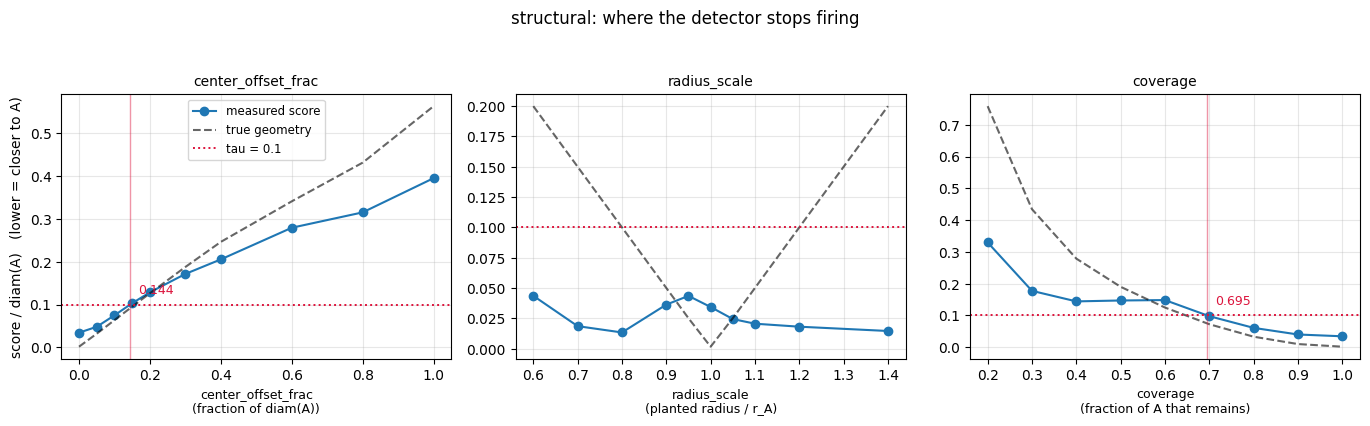

In [27]:
# ── A': the detection curve — where exactly the detector stops firing ────────
#     One positive example is not enough: it shows that the criterion CAN
#     fire, but not that it fires ONLY when the geometry is there. Here the
#     geometry is spoiled by a measured amount, and we look at where the score
#     crosses tau. Computed on ONE neuron (the planted one), not on the
#     ensemble: about 2-3 minutes for all three axes. The result is written to
#     disk and reused.
from visualization.calibration_plots import plot_detection_curves

DETECTION_CSV = Path("analysis/results/calibration/sanity_detection_curves.csv")
DEG_AXES = {
    # axis -> values; each spoils the circle in its own way
    "center_offset_frac": [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0],
    "radius_scale":       [0.6, 0.7, 0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2, 1.4],
    "coverage":           [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2],
}

if DETECTION_CSV.exists():
    curves = cal.read_scores_csv(DETECTION_CSV)
    print(f"reusing {DETECTION_CSV} ({len(curves)} rows)")
else:
    t0, parts = time.perf_counter(), []
    for axis, values in DEG_AXES.items():
        df = cal.detection_curve(
            probe_model, FEATURES["relevant"]["relevant"], BOUNDS,
            {"structural": CRITS["structural"]}, axis=axis, values=values,
            resolution=REFERENCE_RES, layer_id=3, coord_id=0, verbose=False)
        df["axis"] = axis
        df["value"] = df[axis]
        parts.append(df)
        print(f"  {axis:20s} {len(df)} points")
    curves = pd.concat(parts, ignore_index=True)
    curves.to_csv(DETECTION_CSV, index=False)
    print(f"done in {time.perf_counter() - t0:.0f} s → {DETECTION_CSV}")

for axis in DEG_AXES:
    block = curves[curves.axis == axis].sort_values("value")
    x_tau = cal.crossing(block, TAU, x="value", y="score")
    unit = cal.DEGRADATION_AXES[axis][1]
    print(f"\n{axis} ({unit}):")
    print("   " + "  ".join(f"{v:g}→{s:.3f}" for v, s in zip(block.value, block.score)))
    print(f"   tau crossing: {'none within the range' if x_tau is None else f'{x_tau:.3f}'}")

plot_detection_curves(curves, threshold=TAU,
                      save_path=(FIGDIR / "s3_detection_curves.png") if SAVE else None)


**What the curves showed: the detector does not fire on just anything — and one axis revealed a property
of the criterion itself.**

Three ways of spoiling a geometry known to be correct, and three different answers.

| axis | what is spoiled | τ crossing |
|---|---|---|
| `center_offset_frac` | the circle is shifted | **0.144** of diam(A) |
| `coverage` | only part of the circle is encoded | **0.695** — ≈ 70% of the arc is needed |
| `radius_scale` | the wrong radius | **does not cross at all** in the range 0.6–1.4 |

#### Shift and coverage: the detector behaves as it should

The score follows the true geometry while the shift is small (0.0343 against 0.0016 at zero; 0.0749
against 0.0636 at 0.10) and goes past τ at a shift of **14.4% of the diameter**. At large shifts the
measured score turns out to be **lower** than the true one (0.3954 against 0.5636 at a shift of a whole
diameter) — and this is not an error but a consistency check: the score is a minimum over all
components, so as soon as the planted circle moves far away, the criterion stops measuring it and starts
measuring the floor. 0.3954 lies exactly within the range of the floor (0.18–0.37 by placement, section
4). The curve runs into the same floor that we measured independently.

The same holds for coverage: below 0.6 the score flattens out around 0.145 — the floor again.

#### Radius: the criterion does not look at it, and this has to be written down

The true error grows in a V shape (0.20 at 0.6× and at 1.4×), while the measured score stays between
0.013 and 0.044 the whole time — **the verdict is "witness" over the whole range**. This is not an
implementation defect but a direct consequence of how the criterion is built:

`plant_radial_neuron` creates a **radially symmetric** function whose level curves are concentric circles
of **all** radii at once. Shifting the radius of the ridge changes only **at which level** the circle of
radius `r_A` lies, but does not remove it from the family. And the structural criterion is a minimum
**over levels**: which level carries the feature is irrelevant to it by construction.

Hence an honest formulation of what the criterion actually checks:

> **"This neuron has a level curve that repeats A" — not "the ridge of this neuron is A".**
> The criterion is invariant to the level at which the feature sits.

Together the two axes give a precise boundary: **the centre is localised to within 14% of the diameter,
the radius is not constrained at all** (within ±40%). What matters is concentricity, not size — that is
why the shift degrades and the scale does not. `radius_scale` does not work as a degradation axis for
this criterion, and one must not report along it.

#### What this gives: τ in physical units

The main use of the curves is that they translate the dimensionless score into an understandable
quantity. Applying the numbers measured earlier to the shift curve and the coverage curve:

| quantity | score | ≈ shift (fractions of diam) | ≈ coverage |
|---|---|---|---|
| planted neuron | 0.0343 | 0 | 1.00 |
| **median of the task-relevant target** | 0.0349 | **0.002** | **0.99** |
| **threshold τ** | 0.100 | **0.144** | **0.70** |
| `model21` — the only failure | 0.1304 | 0.20 | ≈ 0.6 |
| **median of the A.1 floor** | 0.1858 | **0.34** | **0.29** |
| median of the task-irrelevant target | 0.3923 | > 1 | < 0.2 |

This reads as follows: **the threshold τ = 0.1 is "a circle shifted by a seventh of its diameter" or "70%
of the arc encoded"**. The median trained witness on the task-relevant task is equivalent to a
practically ideal circle, and the floor to a circle shifted by a third of its diameter or encoded to 29%.
This is the missing piece of the calibration: between the planted ideal and the floor there is now
a scale rather than two numbers — but, to repeat, this is a draft for a separate experiment, not a result
of the current one.

A caveat: the conversion was made along the curve of the **planted** construction, so this is an
interpretive scale, not a measurement of trained neurons. One cannot claim "neuron model21 encodes a
circle shifted by 0.20 of the diameter" — one can claim that it scores as much as such a circle would.
